4.46 Beyond the Dipole: Multipoles and Magnetic Coupling

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs%2Ftut%2F4-Analysis%2F4.46-Beyond-the-dipole-multipoles-and-magnetic-coupling.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Ftut%2F4-Analysis%2F4.46-Beyond-the-dipole-multipoles-and-magnetic-coupling.ipynb)

> 💡 **What you need.** gmsh, scikit-fem and SciPy (`pip install "quantum-metal[skfem]" pymetis`). One knob, `BUDGET` in the first code cell, sets the cost: `"standard"` (the default) takes about 15–20 minutes and 10–14 GB (measured on an 8-core laptop with 24 GB; the mesher is not deterministic, so run times and peak memory vary by tens of percent, and a run with less memory may need the optional sections switched off); `"quick"` about 40 seconds and 2.3 GB, on a coarse mesh whose floors are large and with claim thresholds written for `"standard"`, so some rows of the claims table will read CAVEAT or FAIL; `"fine"` about 30 minutes and 13 GB. Memory is the peak of the kernel. The optional sections (the `RUN_*` flags next to `BUDGET`) can each be switched off. Extends the series on Molavi *et al.* [1] beyond what the paper does; [4.44](4.44-Every-coupling-from-one-eigenmode.ipynb) and [4.45](4.45-Four-methods-one-full-wave-model.ipynb) built the full-wave model this notebook looks inside.

> 🧭 **Other simulation pathways.** This notebook uses the open-source gmsh + scikit-fem solver. The same quantities can come from Ansys HFSS / Q3D (tutorials 4.01–4.23) or, for capacitance, from the open-source ElmerFEM path for capacitance (tutorial 4.19); AWS Palace is available through SQDMetal, with a native integration in progress. [Simulation pathways](https://qiskit-community.github.io/qiskit-metal/simulation-pathways.html) summarizes what each solver computes, how to install it, and which tutorials use it.

Tutorials 4.41–4.45 treated each transmon as an electric dipole in the in-plane field of a package mode, and the paper's Fig. 7 shows that this picture reproduces the full-wave couplings to a few percent. This notebook asks what the dipole picture leaves out, and answers it from computed fields, term by term:

- **the electric dipole is the whole story to a few parts in a thousand.** The next electric term that survives, the octupole, rescales the dipole coupling by a fixed factor of order $10^{-3}$ and does not change its pattern across the array;
- **the electric quadrupole and the magnetic dipole of a two-pad transmon vanish by symmetry**, and the next magnetic moment, the one that does not vanish, couples to a field the lowest package modes do not have (the vertical magnetic field $B_z$);
- **none of these zeros is a blind spot.** The notebook shows where each one fails if its condition is broken: an asymmetric qubit has a quadrupole, a vertical current element has a magnetic moment that the in-plane magnetic field of the mode does drive, and a mode with $B_z\neq0$ exists, at higher frequency.

Every statement above comes with a condition, a test, and a measured number in the table of Sec. 12, computed in this notebook rather than typed into it, and every small term carries an error bar and a verdict on whether it is resolved at all (Secs. 9–11). The mathematics is a multipole expansion of the qubit's coupling energy, and the physics is in which terms the geometry allows.

**What you'll learn**

- how a qubit's charge and current become a short list of moments, and how to compute them from an electrostatic solve (Sec. 1–2);
- why a *planar* source sees only the in-plane electric field and the normal magnetic field of a package mode, and what that does to the electric/magnetic split (Sec. 3);
- how to show that a coupling term vanishes, rather than assert it: against the finite-element field, with and without the paddles, and against the exact induced-EMF coupling of 4.44 (Sec. 4–6);
- where the magnetic coupling is *not* zero, and how the quadrupole appears when the symmetry is broken (Sec. 7–8);
- how genuine terms and symmetry zeros behave under mesh refinement, and how to put a measured noise floor under every small number, so that a coupling of $10^{-6}$ is reported as a value, or as an upper limit (Secs. 9–11).

## 0. Setup and the compute budget

The model is the paper's device of notebooks 4.43–4.45: a 10 × 10 array of two-pad transmons on a silicon slab in a $30\times30\times3$ mm box. The mirror symmetry of the box and the array lets a quarter, 25 qubits, stand for all 100. `BUDGET` picks the mesh and the optional sections:

In [1]:
# In Colab, uncomment to install the dependencies of the whole series.
# gmsh's Linux wheel links against system graphics libraries that Colab lacks (libGLU and a few X11 ones):
# !apt-get -qq update && apt-get -qq install -y libglu1-mesa libgl1 libxcursor1 libxft2 libxinerama1 libxfixes3 libxrender1 libxext6 libfontconfig1 > /dev/null
# !pip install -q "quantum-metal[skfem]" pymetis

In [2]:
import os
import sys
import time
import urllib.request
import warnings
from pathlib import Path

# The code shared by tutorials 4.41-4.46 lives in docs/tut/resources/package_modes/.
RES = Path("../resources/package_modes")
if not (RES / "multipoles.py").exists():  # e.g. in Colab: fetch it next to the notebook
    RES = Path("package_modes")
    RES.mkdir(exist_ok=True)
    for name in ("package_modes.py", "multipoles.py"):
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/qiskit-community/qiskit-metal/main/"
            f"docs/tut/resources/package_modes/{name}", RES / name)
sys.path.insert(0, str(RES))

import package_modes as pm
import multipoles as mp

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib import cm, colors as mcolors
from matplotlib.collections import PolyCollection

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"font.size": 10.5, "axes.titlesize": 11, "axes.labelsize": 10.5, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- the one knob -----------------------------------------------------------------------------
BUDGET = "standard"  # "quick" | "standard" | "fine"
# -----------------------------------------------------------------------------------------------
PRESETS = {
    # h_metal, h_max: element sizes (mm) at the paddle edges and in the bulk; order: electrostatics element order;
    # N_fit: points of every polynomial fit to a finite-element field; sweep: the other mesh levels of Sec. 9; n_ens: meshes of
    # nearly the same size that measure the nondeterminism of the mesher (Sec. 10)
    "quick": dict(h_metal=0.15, h_max=1.0, order=1, N_fit=800, sweep=[], n_ens=0,
                  convergence=False, box=False, symmetry_breaking=True, lse=False),
    "standard": dict(h_metal=0.07, h_max=0.7, order=2, N_fit=2000, sweep=[0.2, 0.14, 0.1], n_ens=4,
                     convergence=True, box=True, symmetry_breaking=True, lse=True),
    "fine": dict(h_metal=0.05, h_max=0.7, order=2, N_fit=3000, sweep=[0.2, 0.14, 0.1, 0.07], n_ens=5,
                 convergence=True, box=True, symmetry_breaking=True, lse=True),
}
BUD = PRESETS[BUDGET]
RUN_CONVERGENCE = BUD["convergence"]  # Sec. 9: refine the mesh and watch each term
RUN_SINGLE_QUBIT_BOX = BUD["box"]  # Sec. 2: a full-wave mode of one qubit, to see its magnetic field
RUN_SYMMETRY_BREAKING = BUD["symmetry_breaking"]  # Sec. 8: asymmetric qubits
RUN_LSE_SEARCH = BUD["lse"]  # Sec. 7: look for a package mode with B_z != 0

FIG_DIR = os.environ.get("QM_FIG_DIR")  # set to a folder to keep 200-dpi PNG copies of every figure


def show(fig, name):
    """Display a figure and, if QM_FIG_DIR is set, keep a 200-dpi copy."""
    if FIG_DIR:
        fig.savefig(Path(FIG_DIR) / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


# every statement of the notebook, with its condition, test and measured result, collects here (Sec. 12)
CLAIMS = []


def claim(statement, condition, test, measured, verdict, note="", term=None):
    """Record one claim. verdict: 'PASS', 'FAIL' or 'CAVEAT' (holds, with a limitation named in ``note``).
    ``term`` = (name, mode) links the claim to a row of the error budget of Sec. 10, which adds its floor and significance."""
    CLAIMS.append(dict(statement=statement, condition=condition, test=test, measured=measured,
                       verdict=verdict, note=note, term=term))


TIMES = {}  # seconds per stage, for the table of the budget


def tier(value, limit):
    """PASS below ``limit``, CAVEAT below 3 x limit (mesh noise of the same order), FAIL above."""
    return "PASS" if value < limit else ("CAVEAT" if value < 3 * limit else "FAIL")
P = pm.PAPER
t = pm.DEVICE["t"]  # silicon thickness, mm
design = pm.build_design()
package = pm.package_from_design(design)
QUBITS = [(i, j) for j in range(5) for i in range(5)]  # the quarter: column i along x, row j along y
centers = pm.qubit_centers()
an = {"110": pm.lsm_mode(1, 1), "210": pm.lsm_mode(2, 1)}  # analytic LSM modes (notebook 4.41)
print(f"BUDGET = {BUDGET!r}: h_metal = {BUD['h_metal']} mm, h_max = {BUD['h_max']} mm, "
      f"order-{BUD['order']} electrostatics, optional sections: "
      f"{[k for k, v in dict(convergence=RUN_CONVERGENCE, box=RUN_SINGLE_QUBIT_BOX, symmetry_breaking=RUN_SYMMETRY_BREAKING, lse=RUN_LSE_SEARCH).items() if v]}")
print("mesh-free checks of the helper module:")
_ = mp.selftest()

BUDGET = 'standard': h_metal = 0.07 mm, h_max = 0.7 mm, order-2 electrostatics, optional sections: ['convergence', 'box', 'symmetry_breaking', 'lse']
mesh-free checks of the helper module:
          T1 p: 0.00e+00 (limit 1e-12)  ok
          T1 S: 3.53e-18 (limit 1e-12)  ok
          T1 O: 0.00e+00 (limit 1e-12)  ok
      T1 shift: 1.40e-16 (limit 1e-12)  ok
        T2 ray: 9.10e-15 (limit 1e-10)  ok
    T2 series3: 1.01e-05 (limit 5e-03)  ok
  T3 int K = p: 2.31e-15 (limit 1e-10)  ok
       T3 curl: 1.11e-16 (limit 1e-09)  ok
       T3 quad: 2.32e-03 (limit 2e-02)  ok


### How the numbers are reported

Several of the couplings below are a part in $10^{4}$ to $10^{6}$ of the main one. A number that small is only meaningful if it is larger than the noise of the way it was computed, so every term of this notebook carries a **floor**, measured and not assumed, and the notebook says plainly when a term is below it.

**Four measured contributions to the floor of a term** (Sec. 9–10 compute them; they add in quadrature, and the largest is reported alone as well):

1. *mesh discretization*: the change of the term between the two finest mesh levels;
2. *mesher nondeterminism*: gmsh's tetrahedral mesher returns a different mesh each time, so a few independent meshes of nearly the same size give a free ensemble, and the scatter of the term over it is a floor;
3. *estimator noise*: the polynomial fit that turns a finite-element field into a value and a gradient has choices (radius, number of points, degree, where the disc sits), and the scatter over those choices is a floor;
4. *null calibration*: a quantity that is exactly zero by symmetry ($p_y$, $S_{ij}$, $\tilde m_z$, the coupling of a dark qubit, $B_z$ of the bare mode) measures directly what the estimator returns for zero. For a term that is itself such a zero, its value *is* the floor.

A fifth, not a noise, multiplies the magnetic terms: the current model of Sec. 2 is good to a factor of about 2, carried as a band $[\tfrac12,2]\times$.

**The significance rule.** A term is *resolved* if its value exceeds 3 times its floor **and** it changes by less than its own size between the two finest mesh levels. Otherwise it is reported as an upper limit, "< floor", never as a number. Every term is given as kilohertz ($g/2\pi$) and as a fraction of the dipole coupling $E_1$, against two reference lines: **1 kHz**, a practical frequency resolution, and **4.8%**, the largest spread between the paper's four extraction methods. A term can be resolved and still irrelevant, or an upper limit and still the interesting one. The analytic octupole is a closed-form function of the moments and the analytic field and has no finite-element noise in its field factor; the finite-element estimate of the same term, which needs second derivatives of a field, does, and is reported separately.

In the sections before Sec. 10 the bare numbers are printed as they come out; Sec. 10 puts the error bars on all of them, and Sec. 11 redraws the hierarchy and the maps with them.

## 1. The qubit as a source of moments

A qubit mode with energy $E_n$ carries charge $\pm q$ on its two paddles, with $q=\sqrt{2C E_n}$ for the capacitance $C$ across the junction. Far from the paddles only the *moments* of that charge matter,

$$p_i=\sum_k q_k r_i,\qquad S_{ij}=\sum_k q_k r_ir_j,\qquad O_{ijk}=\sum_k q_k r_ir_jr_k,$$

the dipole, the Cartesian quadrupole and the octupole, with $r$ measured from the qubit's center, the midpoint of its junction line. The charges come from second-order electrostatics on the mesh, as in 4.43: each node of the paddles carries the charge $\int\sigma\psi_k\,dA$ that the solver reports, so sums over the nodes are exact for fields that vary at most quadratically, and the total charge of the qubit is zero to rounding.

`pm.Electrostatics` solves the whole quarter once; `mp.qubit_sources` then takes each qubit's own paddles out of it, and also builds its current (Sec. 2).

In [3]:
start = time.time()
quarter = pm.mesh_package(package, region="quarter", h_metal=BUD["h_metal"], h_max=BUD["h_max"])
TIMES["mesh"] = time.time() - start
es = pm.Electrostatics(quarter, order=BUD["order"])
src = mp.qubit_sources(es, quarter, package, QUBITS, order=BUD["order"])
TIMES["electrostatics"] = time.time() - start - TIMES["mesh"]
print(f"{quarter.summary()}\nelectrostatics (order {BUD['order']}) and the moments of 25 qubits: {TIMES['electrostatics']:.0f} s")

mom = {ij: s["mom"] for ij, s in src.items()}
px = np.array([m["p"][0] for m in mom.values()])
print(f"\n25 qubits: p_x = {px.mean():.4e} C m (spread {np.ptp(px) / px.mean():.2%}),"
      f" net charge {max(abs(m['Q']) for m in mom.values()) / np.abs(src[(0, 0)]['q']).sum():.1e} of the charge on the paddles")
print(f"a typical qubit ((2,2), {pm.qubit_centers()[(2, 2)]} mm), moments about its junction midpoint (SI):")
m22 = mom[(2, 2)]
print(f"  p   = ({m22['p'][0]:+.3e}, {m22['p'][1]:+.1e}) C m")
print(f"  S   = [[{m22['S'][0, 0]:+.1e}, {m22['S'][0, 1]:+.1e}], [{m22['S'][1, 0]:+.1e}, {m22['S'][1, 1]:+.1e}]] C m^2"
      f"   (compare p x 1 mm = {m22['p'][0] * 1e-3:.1e})")
print(f"  O_xxx = {m22['O'][0, 0, 0]:+.3e}, O_xyy = {m22['O'][0, 1, 1]:+.3e} C m^3"
      f"   (O/p = {m22['O'][0, 0, 0] / m22['p'][0] * 1e6:.3f} and {m22['O'][0, 1, 1] / m22['p'][0] * 1e6:.3f} mm^2)")

quarter package: 300,583 tetrahedra, 53,830 nodes, 50 paddles, 25 junctions (meshed in 2.9 s)
electrostatics (order 2) and the moments of 25 qubits: 89 s

25 qubits: p_x = 3.7868e-10 C m (spread 0.46%), net charge 6.3e-15 of the charge on the paddles
a typical qubit ((2,2), (7.5, 7.5) mm), moments about its junction midpoint (SI):
  p   = (+3.788e-10, -6.3e-14) C m
  S   = [[+3.3e-16, -1.3e-16], [-1.3e-16, -1.9e-16]] C m^2   (compare p x 1 mm = 3.8e-13)
  O_xxx = +7.753e-17, O_xyy = +4.210e-17 C m^3   (O/p = 0.205 and 0.111 mm^2)


The dipole is $p_x\approx3.8\times10^{-10}$ C m, along the line between the paddles. Everything else is small, and the pattern of what is small is the point. Two identical paddles, one the mirror image of the other under $x\to-x$ and each symmetric under $y\to-y$, carry a charge density $\sigma(x,y)$ that is **odd in $x$ and even in $y$**. Each moment is a sum of $\sigma$ times a monomial, so a monomial of the wrong parity sums to zero:

- $p_y=\sum q\,y=0$ and $S_{xy}=\sum q\,xy=0$ because $\sigma$ is even in $y$ (these are odd in $y$);
- $S_{xx}=\sum q\,x^2$ and $S_{yy}=\sum q\,y^2$ vanish because $\sigma$ is odd in $x$ (these are even in $x$);
- $O_{xxx}$ and $O_{xyy}$ are odd in $x$ and even in $y$: they are the octupole moments that can survive.

The table of 25 qubits below tests those statements on the computed charges. A discrete mesh is not symmetric, so each zero comes out as a small number, and Sec. 9 shows how that number moves with refinement.

In [4]:
S_all = np.array([np.abs(m["S"]).max() for m in mom.values()])
py_all = np.array([abs(m["p"][1]) for m in mom.values()])
Oxxx = np.array([m["O"][0, 0, 0] / m["p"][0] for m in mom.values()]) * 1e6
Oxyy = np.array([m["O"][0, 1, 1] / m["p"][0] for m in mom.values()]) * 1e6
Odd = np.array([max(abs(m["O"][0, 0, 1]), abs(m["O"][1, 1, 1])) for m in mom.values()])
rows = [("p_x (C m)", f"{px.mean():.4e}", "—"),
        ("max |p_y| / p_x", f"{(py_all / px).max():.1e}", "odd in y"),
        ("max |S_ij| / (p_x · 1 mm)", f"{(S_all / (px * 1e-3)).max():.1e}", "odd in x (S_xx, S_yy), odd in y (S_xy)"),
        ("O_xxx / p_x (mm²)", f"{Oxxx.mean():.3f} ± {Oxxx.std():.3f}", "survives"),
        ("O_xyy / p_x (mm²)", f"{Oxyy.mean():.3f} ± {Oxyy.std():.3f}", "survives"),
        ("max |O_xxy|, |O_yyy| / (p_x · 1 mm²)", f"{(Odd / (px * 1e-6)).max():.1e}", "odd in y")]
print(f"{'quantity over the 25 qubits':>40} {'value':>16}   parity argument")
for a, b, c in rows:
    print(f"{a:>40} {b:>16}   {c}")
claim("p_y = 0", "σ even in y (paddles symmetric about the junction axis)", "25 qubits, order-2 charges",
      f"max |p_y|/p_x = {(py_all / px).max():.1e}", tier((py_all / px).max(), 5e-3),
      "the mesh is not symmetric: the value changes from run to run with the mesh (ensemble of Sec. 10) and falls under refinement (Sec. 9)")
claim("S_ij = 0 (Cartesian electric quadrupole)", "two identical paddles, mirror images under x → −x, each even in y",
      "25 qubits, order-2 charges", f"max |S_ij|/(p·1 mm) = {(S_all / (px * 1e-3)).max():.1e}",
      tier((S_all / (px * 1e-3)).max(), 5e-3))

             quantity over the 25 qubits            value   parity argument
                               p_x (C m)       3.7868e-10   —
                         max |p_y| / p_x          3.4e-03   odd in y
               max |S_ij| / (p_x · 1 mm)          1.7e-03   odd in x (S_xx, S_yy), odd in y (S_xy)
                       O_xxx / p_x (mm²)    0.205 ± 0.000   survives
                       O_xyy / p_x (mm²)    0.111 ± 0.000   survives
    max |O_xxy|, |O_yyy| / (p_x · 1 mm²)          8.4e-04   odd in y


The octupole numbers are the first nonzero correction. Their size, $O/p\approx0.2$ and $0.1$ mm², is the square of a length of a few tenths of a millimeter, smaller than the paddle ($0.5\times1$ mm), as it should be for a charge that sits within about half a millimeter of the center.

**What the charge looks like.** The next figure puts the three things this notebook keeps comparing side by side for one qubit: the surface charge on the paddles, and the field lines of $\mathbf E$ and of $\mathbf D=\varepsilon\mathbf E$ in the plane through the junction axis, from the second-order potential. $\mathbf E$ is what charges feel and $\mathbf D$ is what charges source; across the silicon surface they differ by the factor 11.9 in the permittivity, which is why the field lines of $\mathbf D$ crowd into the silicon and those of $\mathbf E$ are the ones that look continuous in the plane of the paddles.

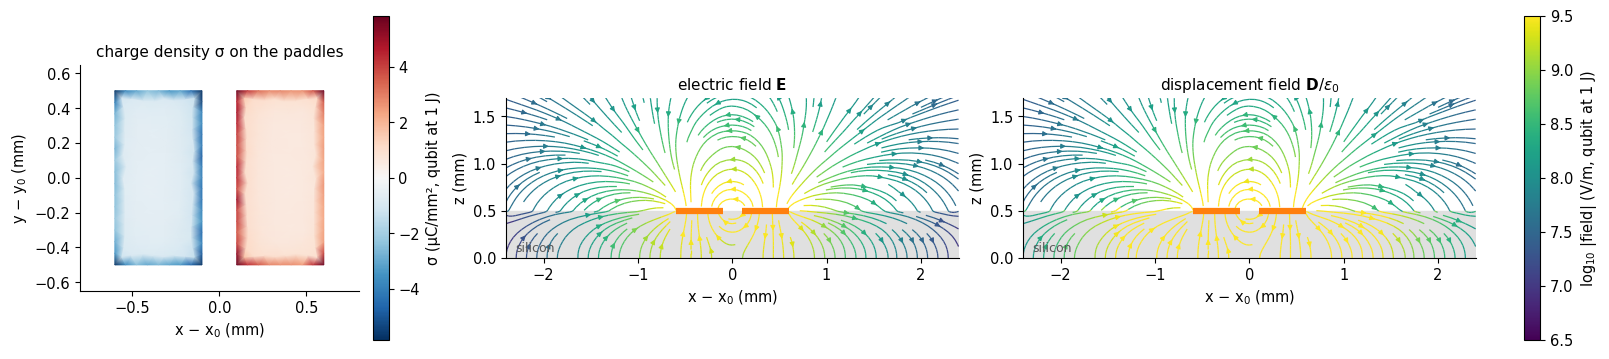

(potential on a grid: 2 s)


In [5]:
start = time.time()
q22 = (2, 2)
c22 = np.array(centers[q22])
xs = np.linspace(c22[0] - 2.4, c22[0] + 2.4, 241)
zs = np.linspace(0.0, 2.0, 161)  # z = t = 0.5 mm is a grid row, so each medium can be differentiated on its own
Xg, Zg = np.meshgrid(xs, zs)
pts = np.vstack([Xg.ravel(), np.full(Xg.size, c22[1]), Zg.ravel()])
phi = es.potential("Q_2_2.pad_right", "Q_2_2.pad_left", pts).reshape(Xg.shape)  # V, qubit energy 1 J
k_t = int(np.argmin(np.abs(zs - t)))
dz = zs[1] - zs[0]
Ex = -np.gradient(phi, xs[1] - xs[0], axis=1) * 1e3  # V/m
Ez = np.empty_like(phi)
Ez[:k_t + 1] = -np.gradient(phi[:k_t + 1], dz, axis=0) * 1e3  # silicon side (one-sided at the surface)
Ez[k_t:] = -np.gradient(phi[k_t:], dz, axis=0) * 1e3  # vacuum side
eps_r = np.where(Zg <= t, pm.DEVICE["eps_r"], 1.0)  # relative permittivity at each grid point

# surface charge density on the paddles (first-order nodal charge over the lumped area), C/m^2 = µC/mm^2
sig_pads = [(xy * 1e3, mp.lumped_density(xy, r, tri), tri) for xy, r, tri in src[q22]["pads"]]  # xy in mm

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw=dict(width_ratios=[0.8, 1.3, 1.3]), layout="constrained")
s_lim = np.percentile(np.abs(np.concatenate([s[1] for s in sig_pads])), 97)
for xy, sg, tri in sig_pads:
    tc = ax0.tripcolor(xy[0], xy[1], tri, sg, cmap="RdBu_r", vmin=-s_lim, vmax=s_lim, shading="gouraud")
ax0.set(aspect="equal", xlim=(-0.8, 0.8), ylim=(-0.65, 0.65), xlabel="x − x$_0$ (mm)", ylabel="y − y$_0$ (mm)",
        title="charge density σ on the paddles")
fig.colorbar(tc, ax=ax0, shrink=0.85, label="σ (µC/mm², qubit at 1 J)")
for a, (Fx, Fz, ttl) in zip((ax1, ax2), ((Ex, Ez, "electric field $\\mathbf{E}$"), (Ex * eps_r, Ez * eps_r, "displacement field $\\mathbf{D}/\\varepsilon_0$"))):
    mag = np.hypot(Fx, Fz)
    a.axhspan(0, t, color="0.88", zorder=0)
    sl = a.streamplot(xs - c22[0], zs, Fx, Fz, color=np.log10(mag), cmap="viridis", density=1.5, linewidth=0.9,
                      arrowsize=0.7, norm=mcolors.Normalize(6.5, 9.5))
    for xy, sg, tri in sig_pads:
        a.plot([xy[0].min(), xy[0].max()], [t, t], color="tab:orange", lw=4.5, solid_capstyle="butt", zorder=5)
    a.set(xlim=(-2.4, 2.4), ylim=(0, 1.7), xlabel="x − x$_0$ (mm)", ylabel="z (mm)", title=ttl, aspect="equal")
    a.text(-2.3, 0.07, "silicon", ha="left", color="0.35", fontsize=9)
fig.colorbar(sl.lines, ax=[ax1, ax2], shrink=0.85, label="log$_{10}$ |field| (V/m, qubit at 1 J)")
show(fig, "fig01_charge_E_D")
print(f"(potential on a grid: {time.time() - start:.0f} s)")

Two things to read from the figure. The charge crowds onto the facing edges of the paddles, which is why the mesh must be fine there (4.43). And the lines of $\mathbf D$ run mostly through the silicon between the paddles, while the lines of $\mathbf E$ spread above the chip: the same physical field, drawn with the quantity that is continuous across the interface in the normal direction ($\mathbf D_z$) and the one that is continuous along it ($\mathbf E_x$). Which one a thin planar source feels is Sec. 3.

**The potential on a circle.** A multipole is a statement about how the potential varies with angle at a distance. On a circle of radius 2 mm around the qubit — outside its paddles, inside the pitch to the next qubit — the in-plane potential has an expansion $\Phi(\theta)=\sum_n a_n\cos n\theta+b_n\sin n\theta$ whose $n=1$ term is the dipole, $n=2$ the quadrupole, $n=3$ the octupole. The symmetry of the qubit says which harmonics exist: $\sigma$ odd in $x$ and even in $y$ gives $\Phi(\pi-\theta)=-\Phi(\theta)$ and $\Phi(-\theta)=\Phi(\theta)$, so only $\cos n\theta$ with odd $n$ appear.

In [6]:
th = np.linspace(0, 2 * np.pi, 361)[:-1]
circ = np.vstack([c22[0] + 2.0 * np.cos(th), c22[1] + 2.0 * np.sin(th), np.full(th.size, t + 1e-6)])
phi_c = es.potential("Q_2_2.pad_right", "Q_2_2.pad_left", circ)


def harmonics(theta, phi_theta, n_max=6):
    """Cosine and sine amplitudes (V) of the angular harmonics 1..n_max of a potential on a circle."""
    a = [2 * np.mean(phi_theta * np.cos(n * theta)) for n in range(1, n_max + 1)]
    b = [2 * np.mean(phi_theta * np.sin(n * theta)) for n in range(1, n_max + 1)]
    return np.array(a), np.array(b)


a_sym, b_sym = harmonics(th, phi_c)
amp_sym = np.hypot(a_sym, b_sym)
odd_n, even_n = amp_sym[0::2], amp_sym[1::2]
print("amplitude of the angular harmonics of the potential on the 2 mm circle (V, qubit energy 1 J):")
print("  n:", *[f"{n:>9d}" for n in range(1, 7)])
print("   ", *[f"{v:9.2e}" for v in amp_sym])
print(f"largest even harmonic / dipole harmonic: {even_n.max() / amp_sym[0]:.1e}")
claim("only odd angular harmonics of the potential", "σ odd in x, even in y", "potential on a 2 mm circle, qubit (2,2)",
      f"max even / n=1 amplitude = {even_n.max() / amp_sym[0]:.1e}", tier(even_n.max() / amp_sym[0], 5e-3))
del es  # free the factorization; the charges, moments and currents are what we keep

amplitude of the angular harmonics of the potential on the 2 mm circle (V, qubit energy 1 J):
  n:         1         2         3         4         5         6
     1.28e+04  2.98e+01  9.48e+02  6.51e+00  2.35e+02  2.44e+01
largest even harmonic / dipole harmonic: 2.3e-03


## 2. The qubit as a source of current

At the qubit's frequency the charge $\pm q(t)$ on the paddles slosh through the junction, so a current flows in the paddles and across the gap. The coupling of that current to a magnetic field is the second half of the multipole expansion, and it needs the *current* distribution, not only the charge.

**What can be computed and what cannot.** Charge conservation fixes the divergence of the current: with $\mathbf K$ the charge displaced during the oscillation (so that $\partial_t\mathbf K$ is the sheet current), $\nabla\cdot\mathbf K=-\sigma$ on the paddles, and the junction carries the whole charge of one paddle to the other. It does not fix the rotation of $\mathbf K$: a current loop on a paddle satisfies $\nabla\cdot\mathbf K=0$ and moves no charge. That divergence-free part depends on the paddle's response (a superconducting sheet screens differently from a resistive one). This notebook takes the simplest closed model, the resistive-sheet limit in which $\mathbf K=-\nabla\psi$ with $\nabla^2\psi=\sigma$ on each paddle and the junction as the only exit, and treats the answer as good to a factor of about 2. What does *not* depend on the model is symmetry, which is what the zeros of Sec. 1 and this section rest on.

<!-- TODO-ZKM: the sheet-current model (resistive-sheet Poisson problem with a point sink at the junction) is good to a factor of ~2 for the magnetic quadrupole M̃_yz; the planner's estimate was M̃_yz = -1.5e-17 C m^3 with first-order charges, the notebook gets about 1.2e-17 with second-order charges lumped onto first-order triangles. Confirm the model is acceptable for a public tutorial. -->

**The moments of the current.** About the qubit's center,

$$\tilde m=\tfrac12\int\mathbf r\times\mathbf K\,dA,\qquad \tilde M_{ij}=\int r_i\,(\mathbf r\times\mathbf K)_j\,dA,$$

the magnetic dipole and the magnetic quadrupole of the sheet (with $\int\mathbf K\,dA=\mathbf p$ as a check that the current moves the charge it should). Because the sheet is flat, $\mathbf r\times\mathbf K$ points along $z$, so only $\tilde m_z$ and $\tilde M_{xz},\tilde M_{yz}$ exist. Under $y\to-y$ the current $K_x$ is even and $K_y$ is odd, so $(\mathbf r\times\mathbf K)_z=xK_y-yK_x$ is odd in $y$: $\tilde m_z$ and $\tilde M_{xz}$ integrate to zero, and $\tilde M_{yz}$, which carries one more factor $y$, does not. The current of a symmetric transmon is two opposite loops, one above and one below the junction axis, with no net circulation but a nonzero quadrupole.

In [7]:
cur = {ij: s["cur"] for ij, s in src.items()}
dip_err = max(np.abs(cur[ij].dipole() - mom[ij]["p"]).max() / abs(mom[ij]["p"][0]) for ij in QUBITS)
mz = np.array([cur[ij].m() for ij in QUBITS])
Mxz = np.array([cur[ij].M()[0] for ij in QUBITS])
Myz = np.array([cur[ij].M()[1] for ij in QUBITS])
print(f"int K dA - p, worst of 25 qubits: {dip_err:.1e} of p_x   (the current moves the charge it should)")
print(f"max |m_z| / (p_x · 1 mm)   = {np.abs(mz).max() / (px.mean() * 1e-3):.1e}   (zero by the y-mirror)")
print(f"max |M_xz| / |M_yz|        = {np.abs(Mxz).max() / np.abs(Myz).mean():.1e}   (zero by the y-mirror)")
print(f"M_yz = {Myz.mean():+.3e} C m³ ± {Myz.std() / abs(Myz.mean()):.1%} over the 25 qubits"
      f"  = {Myz.mean() / px.mean() / 1e-6:+.3f} p_x mm²   (model: good to a factor of ~2)")
claim("m_z = 0 (magnetic dipole of the current)", "y-mirror symmetry of the paddles and of the junction position",
      "Poisson sheet-current model, 25 qubits", f"max |m_z|/(p·1 mm) = {np.abs(mz).max() / (px.mean() * 1e-3):.1e}",
      tier(np.abs(mz).max() / (px.mean() * 1e-3), 2e-3))
claim("only M_yz survives (magnetic quadrupole of the current)", "same", "Poisson sheet-current model, 25 qubits",
      f"|M_xz|/|M_yz| ≤ {np.abs(Mxz).max() / np.abs(Myz).mean():.1e}; M_yz = {Myz.mean():.2e} C m³",
      "CAVEAT", "the size of M_yz depends on the current model (factor ~2); its vanishing partners do not")

int K dA - p, worst of 25 qubits: 8.7e-15 of p_x   (the current moves the charge it should)
max |m_z| / (p_x · 1 mm)   = 8.6e-04   (zero by the y-mirror)
max |M_xz| / |M_yz|        = 1.3e-02   (zero by the y-mirror)
M_yz = +1.157e-17 C m³ ± 0.4% over the 25 qubits  = +0.031 p_x mm²   (model: good to a factor of ~2)


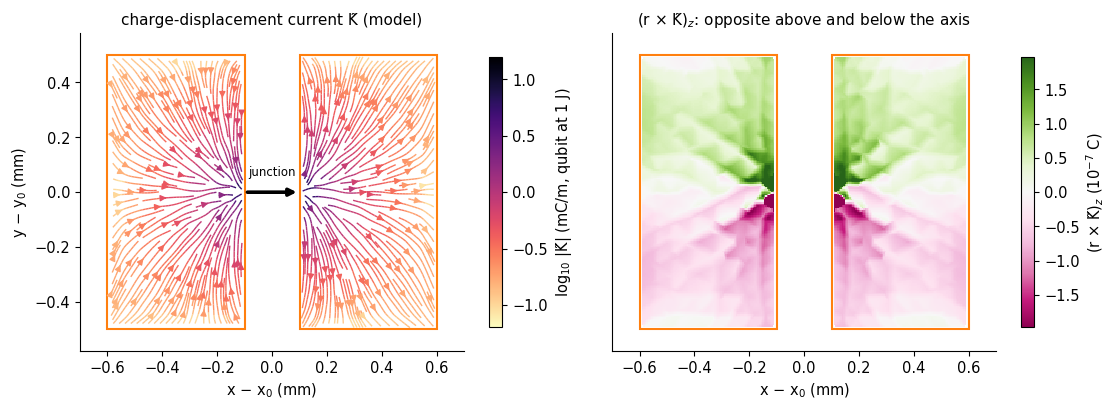

net circulation m_z = +2.4e-16 C m² against the integral of |r×K|/2 = 2.7e-14 C m²: the two loops cancel


In [8]:
c_ = src[q22]["cur"]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw=dict(width_ratios=[1, 1]))
from scipy.interpolate import griddata

gxy = np.meshgrid(np.linspace(-0.6, 0.6, 140), np.linspace(-0.5, 0.5, 120))
Kmag_max = 0
for sign, (lo, hi) in ((+1, (0.1, 0.6)), (-1, (-0.6, -0.1))):
    sel = c_.X[0] * sign > 0
    xx, yy = np.meshgrid(np.linspace(lo, hi, 90), np.linspace(-0.5, 0.5, 170))
    pts_ = np.vstack([c_.X[0][sel] * 1e3, c_.X[1][sel] * 1e3]).T
    kx = griddata(pts_, c_.K[0][sel], (xx, yy), method="linear")
    ky = griddata(pts_, c_.K[1][sel], (xx, yy), method="linear")
    mag = np.hypot(kx, ky)
    sl = ax[0].streamplot(xx, yy, np.nan_to_num(kx), np.nan_to_num(ky), color=np.log10(mag * 1e3 + 1e-12), cmap="magma_r",
                          density=1.6, linewidth=1.0, arrowsize=0.9, norm=mcolors.Normalize(-1.2, 1.2))
    ax[0].add_patch(plt.Rectangle((lo, -0.5), hi - lo, 1.0, fill=False, ec="tab:orange", lw=1.5))
ax[0].annotate("", xy=(0.1, 0), xytext=(-0.1, 0), arrowprops=dict(arrowstyle="-|>", lw=2.6, color="k"))
ax[0].text(0, 0.06, "junction", ha="center", fontsize=8.5)
ax[0].set(aspect="equal", xlim=(-0.7, 0.7), ylim=(-0.58, 0.58), xlabel="x − x$_0$ (mm)", ylabel="y − y$_0$ (mm)",
          title="charge-displacement current K̃ (model)")
plt.colorbar(sl.lines, ax=ax[0], shrink=0.85, label="log$_{10}$ |K̃| (mC/m, qubit at 1 J)")
# which way the current circulates: signed (r x K)_z on a grid of each paddle
circ = c_.X[0] * c_.K[1] - c_.X[1] * c_.K[0]
cg = np.zeros((170, 0))
lim_c = 1.0
for sign, (lo, hi) in ((+1, (0.1, 0.6)), (-1, (-0.6, -0.1))):
    sel = c_.X[0] * sign > 0
    xx, yy = np.meshgrid(np.linspace(lo, hi, 90), np.linspace(-0.5, 0.5, 170))
    cz = griddata(np.vstack([c_.X[0][sel] * 1e3, c_.X[1][sel] * 1e3]).T, circ[sel] * 1e7, (xx, yy), method="linear")
    lim_c = max(lim_c, np.percentile(np.abs(cz[np.isfinite(cz)]), 99))
    ax[1].pcolormesh(xx, yy, cz, cmap="PiYG", vmin=-lim_c, vmax=lim_c, shading="auto")
    ax[1].add_patch(plt.Rectangle((lo, -0.5), hi - lo, 1.0, fill=False, ec="tab:orange", lw=1.5))
ax[1].set(aspect="equal", xlim=(-0.7, 0.7), ylim=(-0.58, 0.58), xlabel="x − x$_0$ (mm)", yticks=[],
          title="(r × K̃)$_z$: opposite above and below the axis")
plt.colorbar(cm.ScalarMappable(mcolors.Normalize(-lim_c, lim_c), "PiYG"), ax=ax[1], shrink=0.85, label="(r × K̃)$_z$ (10$^{-7}$ C)")
plt.tight_layout()
show(fig, "fig02_sheet_current")
print(f"net circulation m_z = {c_.m():+.1e} C m² against the integral of |r×K|/2 = {0.5 * np.sum(np.abs(circ) * c_.w):.1e} C m²: the two loops cancel")

### A full-wave check of the current, and of the claim that the magnetic energy of a qubit is small

The sheet current is a model. A full-wave solve of one qubit gives an independent look at the same current: put the qubit alone in a small box, replace the open junction by its inductor $L_J$, and find the qubit mode. Its magnetic field around the junction is the field of the qubit's own current, and the share of its magnetic energy that sits outside the junction inductor is the geometric inductance, the quantity the paper's impedance fit returns as $\delta L'_n\approx0.32$ nH (4.45 reproduces it) and quotes as a few percent of the qubit's energy.

`pm.MaxwellFEM` takes the inductor as a rank-one term (4.43). Because the discrete Maxwell model sees the first-order electrostatic capacitance (4.45, Sec. 2), the inductance that puts the mode at 6.49 GHz comes from the first-order capacitance.

In [9]:
# One qubit alone in a small box (8 x 8 x 3 mm, the same slab as the array): used here for a full-wave look at its own field,
# and in Sec. 7 for qubits whose symmetry is broken, which cost a fraction of the array to solve.
Lb, cb = 8.0, 4.0

def rect(x0, x1, y0, y1):
    return np.array([[x0, y0], [x1, y0], [x1, y1], [x0, y1]])

def box_package(pad_right=(0.1, 0.6, -0.5, 0.5), junction_y=0.0):
    """One two-pad qubit at the center of an 8 x 8 x 3 mm box (same slab as the array); lengths in mm."""
    x0, x1, y0, y1 = pad_right
    return pm.Package(Lb, Lb, 3.0, t, pm.DEVICE["eps_r"],
                      metals={"Q_0_0.pad_left": rect(cb - 0.6, cb - 0.1, cb - 0.5, cb + 0.5),
                              "Q_0_0.pad_right": rect(cb + x0, cb + x1, cb + y0, cb + y1)},
                      junctions={"Q_0_0": (np.array([cb - 0.1, cb + junction_y]), np.array([cb + 0.1, cb + junction_y]))})

In [10]:
if RUN_SINGLE_QUBIT_BOX:
    start = time.time()
    pk_box = box_package()
    mesh_box = pm.mesh_package(pk_box, region="full", h_metal=0.04, h_max=0.6, h_junction=0.02)
    es_box2 = pm.Electrostatics(mesh_box, order=2)
    src_box = mp.qubit_sources(es_box2, mesh_box, pk_box, [(0, 0)], order=2)[(0, 0)]
    es_box1 = pm.Electrostatics(mesh_box, order=1)
    C_box1 = es_box1.port_capacitance("Q_0_0.pad_left", "Q_0_0.pad_right")
    L_J = 1 / ((2 * np.pi * 6.49e9) ** 2 * C_box1)
    fem_box = pm.MaxwellFEM(mesh_box)
    (mode_box,) = fem_box.eigenmodes(6.49e9, inductors={"Q_0_0": L_J})
    w_b = 2 * np.pi * mode_box.f
    V_J = mode_box.voltage("Q_0_0")
    I_J = V_J / (w_b * L_J)
    # magnetic energy of the field of the mode, outside the inductor: (1/2 mu0 w^2) int |curl E|^2 dV  (K in mm units)
    U_geo = 1e3 * (mode_box.u @ (fem_box.K @ mode_box.u)) / (2 * pm.MU0 * w_b**2)
    U_L = 0.5 * L_J * I_J**2
    print(f"{mesh_box.summary()}\nqubit alone in the box: C = {C_box1 * 1e15:.0f} fF (first order) -> L_J = {L_J * 1e9:.2f} nH; mode at {mode_box.f / 1e9:.3f} GHz")
    print(f"junction current at 1 J: |I| = |V|/(ωL) = {abs(I_J) / 1e3:.1f} kA   (an LC circuit would give √(2/L) = {np.sqrt(2 / L_J) / 1e3:.1f} kA)")
    print(f"magnetic energy at the current maximum: {U_L:.3f} J in the inductor + {U_geo:.3f} J in the field = {U_L + U_geo:.3f} J (the 1 J of the mode)")
    print(f"geometric inductance: {U_geo / U_L * L_J * 1e9:.2f} nH, {U_geo / (U_L + U_geo):.1%} of the magnetic energy, "
          f"half that, {U_geo / (U_L + U_geo) / 2:.1%}, of the qubit's total energy  (paper's fit: δL'_n = 0.32 nH of 3.6 nH)")
    TIMES["box"] = time.time() - start
    print(f"({TIMES['box']:.0f} s)")
    claim("the magnetic energy of the qubit mode outside the junction is a few percent of its energy",
          "single qubit in a box, junction as an inductor L_J, 1 J mode", "∫|curl E|²/(2μ0ω²) over the box plus ½L_J I²",
          f"{U_geo / (U_L + U_geo):.1%} of the magnetic, {U_geo / (U_L + U_geo) / 2:.1%} of the total energy", "PASS",
          "the paper's fit gives δL'_n = 0.32 nH of 3.6 nH (8.9%); 4.45 reproduces it")
else:
    print("RUN_SINGLE_QUBIT_BOX = False: skipped")

full package: 90,545 tetrahedra, 15,411 nodes, 2 paddles, 1 junctions (meshed in 0.8 s)
qubit alone in the box: C = 183 fF (first order) -> L_J = 3.29 nH; mode at 6.200 GHz
junction current at 1 J: |I| = |V|/(ωL) = 23.5 kA   (an LC circuit would give √(2/L) = 24.6 kA)
magnetic energy at the current maximum: 0.912 J in the inductor + 0.088 J in the field = 1.000 J (the 1 J of the mode)
geometric inductance: 0.32 nH, 8.8% of the magnetic energy, half that, 4.4%, of the qubit's total energy  (paper's fit: δL'_n = 0.32 nH of 3.6 nH)
(106 s)


About a tenth of the magnetic energy, and so about 4% of the qubit's total energy, lies outside the junction (the printout gives the numbers): in the field of the current that flows through the paddles. That is the geometric inductance, and the paper's impedance fit finds the same number from the circuit side. Its magnetic field is not small near the paddles: at 1 J the current is tens of kiloamperes. The magnetic coupling to a *package* mode is another matter, because it is the overlap of that field pattern with the mode's own magnetic field, and Sec. 3 says which part of the mode's field a flat current can overlap with.

Below, the field of the qubit's own current. Left, the electric field in the plane through the junction axis; right, the magnetic field in the plane across the junction: its lines circle the junction current, as Ampère's law says, with the field of the paddle currents riding on top.

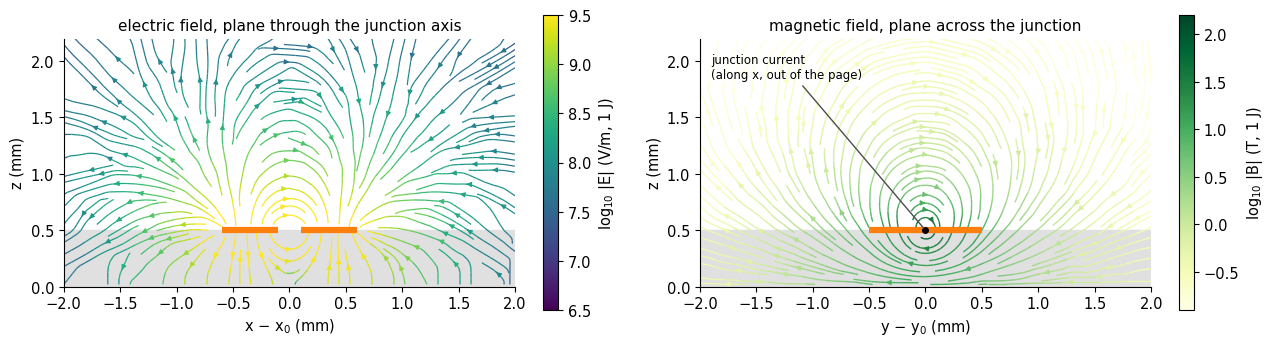

60 µm above the junction: |B| = 80.1 T, 1.02 × the field of an infinite wire carrying I = 23.5 kA
100 µm above the junction: |B| = 30.3 T, 0.64 × the field of an infinite wire carrying I = 23.5 kA


In [11]:
if RUN_SINGLE_QUBIT_BOX:
    yy_ = np.linspace(cb - 2, cb + 2, 161)
    zz_ = np.linspace(0.02, 2.2, 150)
    Yg_, Zg_ = np.meshgrid(yy_, zz_)
    pts_yz = np.vstack([np.full(Yg_.size, cb + 0.001), Yg_.ravel(), Zg_.ravel()])
    B_yz = (mp.curl_E(fem_box, mode_box.u, pts_yz) / w_b).reshape(3, *Yg_.shape)
    xx_ = np.linspace(cb - 2, cb + 2, 161)
    Xg_, Zg2_ = np.meshgrid(xx_, zz_)
    pts_xz = np.vstack([Xg_.ravel(), np.full(Xg_.size, cb + 0.001), Zg2_.ravel()])
    E_xz = mode_box.field(pts_xz).reshape(3, *Xg_.shape)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.0))
    Emag = np.hypot(E_xz[0], E_xz[2])
    ax[0].axhspan(0, t, color="0.88", zorder=0)
    sl = ax[0].streamplot(xx_ - cb, zz_, E_xz[0], E_xz[2], color=np.log10(Emag), cmap="viridis", density=1.4, linewidth=0.9,
                          arrowsize=0.7, norm=mcolors.Normalize(6.5, 9.5))
    ax[0].plot([-0.6, -0.1], [t, t], color="tab:orange", lw=4.5, solid_capstyle="butt")
    ax[0].plot([0.1, 0.6], [t, t], color="tab:orange", lw=4.5, solid_capstyle="butt")
    ax[0].set(aspect="equal", xlim=(-2, 2), ylim=(0, 2.2), xlabel="x − x$_0$ (mm)", ylabel="z (mm)",
              title="electric field, plane through the junction axis")
    plt.colorbar(sl.lines, ax=ax[0], shrink=0.8, label="log$_{10}$ |E| (V/m, 1 J)")
    Bmag = np.hypot(B_yz[1], B_yz[2])
    ax[1].axhspan(0, t, color="0.88", zorder=0)
    sl = ax[1].streamplot(yy_ - cb, zz_, B_yz[1], B_yz[2], color=np.log10(Bmag), cmap="YlGn", density=1.6, linewidth=1.0,
                          arrowsize=0.7, norm=mcolors.Normalize(-0.9, 2.2))
    ax[1].plot([-0.5, 0.5], [t, t], color="tab:orange", lw=4.5, solid_capstyle="butt")
    ax[1].plot([0], [t], "ko", ms=4)
    ax[1].annotate("junction current\n(along x, out of the page)", xy=(0, t), xytext=(-1.9, 1.85), fontsize=8.5,
                   arrowprops=dict(arrowstyle="-", color="0.3"))
    ax[1].set(aspect="equal", xlim=(-2, 2), ylim=(0, 2.2), xlabel="y − y$_0$ (mm)", ylabel="z (mm)",
              title="magnetic field, plane across the junction")
    plt.colorbar(sl.lines, ax=ax[1], shrink=0.8, label="log$_{10}$ |B| (T, 1 J)")
    plt.tight_layout()
    show(fig, "fig03_qubit_E_and_B")
    r_chk = [0.06, 0.1]
    for r_ in r_chk:
        B_ = mp.curl_E(fem_box, mode_box.u, np.array([[cb], [cb], [t + r_]]))[:, 0] / w_b
        print(f"{r_ * 1e3:.0f} µm above the junction: |B| = {np.linalg.norm(B_):.1f} T,"
              f" {np.linalg.norm(B_) / (pm.MU0 * abs(I_J) / (2 * np.pi * r_ * 1e-3)):.2f} × the field of an infinite wire carrying I = {abs(I_J) / 1e3:.1f} kA")

**How good is the sheet-current model?** The full-wave field above the paddles can be compared with the Biot–Savart field of the model current $\omega\tilde{\mathbf K}$. At 0.1 mm above the chip, the normal field $B_z$ that the model predicts should have the same pattern and size as the full-wave $B_z$, which includes the junction current, the paddle currents, and the grounded box (the nearest conducting surfaces, the floor and the lid, enter the model as their first image currents).

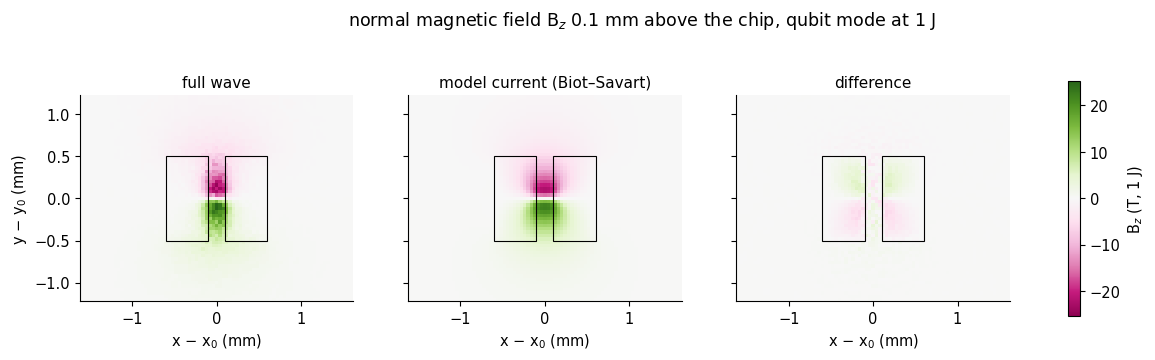

the model's B_z, scaled by the best fit factor 0.87, has correlation 0.957 with the full-wave B_z; peak |B_z| 22.3 T (model) against 25.3 T (full wave)


In [12]:
if RUN_SINGLE_QUBIT_BOX:
    xs_b = np.linspace(cb - 1.6, cb + 1.6, 81)
    ys_b = np.linspace(cb - 1.2, cb + 1.2, 61)
    Xb, Yb = np.meshgrid(xs_b, ys_b)
    zh = 0.1  # mm above the chip
    Bz_fw = (mp.curl_E(fem_box, mode_box.u, np.vstack([Xb.ravel(), Yb.ravel(), np.full(Xb.size, t + zh)])) / w_b)[2].reshape(Xb.shape)
    P_b = np.vstack([(Xb.ravel() - cb) * 1e-3, (Yb.ravel() - cb) * 1e-3])
    Bz_model = src_box["cur"].bz(P_b, zh * 1e-3, w_b, images=[(-2 * t * 1e-3, -1), (2 * (3.0 - t) * 1e-3, -1)]).reshape(Xb.shape)
    sgn = np.sign(np.sum(Bz_fw * Bz_model))  # the sign of a full-wave eigenvector is arbitrary
    Bz_model *= sgn
    lim = np.abs(Bz_fw).max()
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
    for a, F_, ttl in zip(ax, (Bz_fw, Bz_model, Bz_fw - Bz_model),
                          ("full wave", "model current (Biot–Savart)", "difference")):
        im = a.pcolormesh(Xb - cb, Yb - cb, F_, cmap="PiYG", vmin=-lim, vmax=lim, shading="auto")
        for xr in ((-0.6, -0.1), (0.1, 0.6)):
            a.add_patch(plt.Rectangle((xr[0], -0.5), xr[1] - xr[0], 1.0, fill=False, ec="k", lw=0.8))
        a.set(aspect="equal", xlabel="x − x$_0$ (mm)", title=ttl)
    ax[0].set_ylabel("y − y$_0$ (mm)")
    fig.colorbar(im, ax=ax, shrink=0.85, label="B$_z$ (T, 1 J)")
    fig.suptitle("normal magnetic field B$_z$ 0.1 mm above the chip, qubit mode at 1 J", y=1.02)
    show(fig, "fig04_Bz_model_vs_fullwave")
    corr = np.corrcoef(Bz_fw.ravel(), Bz_model.ravel())[0, 1]
    ratio = np.sum(Bz_fw * Bz_model) / np.sum(Bz_model**2)
    print(f"the model's B_z, scaled by the best fit factor {ratio:.2f}, has correlation {corr:.3f} with the full-wave B_z;"
          f" peak |B_z| {np.abs(Bz_model).max():.1f} T (model) against {np.abs(Bz_fw).max():.1f} T (full wave)")
    claim("the sheet-current model reproduces the qubit's own B_z pattern", "single qubit in a box, 0.1 mm above the chip",
          "Biot–Savart of the model current vs the full-wave curl E/ω",
          f"correlation {corr:.3f}; full wave / model amplitude = {ratio:.2f}", "PASS" if corr > 0.9 and 0.5 < ratio < 2 else "FAIL",
          "one geometry; the model's factor-2 flag stays for the magnetic quadrupole")

## 3. What a flat source sees

The qubit is a flat object: charge and current confined to the plane of the paddles, $z=t$, a distance that is a thousand times shorter than the wavelength. Its coupling energy with a mode, written in the multipolar (Power–Zienau–Woolley) form [3, 4] in which a neutral source couples to the *fields* $\mathbf E$ and $\mathbf B$ and not to the potentials, is a sum of two pieces,

$$U=\underbrace{\sum_k q_k\int_0^1\mathbf r_k\cdot\mathbf E(\mathbf r_0+\lambda\mathbf r_k)\,d\lambda}_{\text{charges: the electric multipoles}}\;+\;\underbrace{\int\mathcal M_z(\mathbf r)\,(\nabla\times\mathbf E)_z\,dA}_{\text{currents: the magnetic multipoles}},$$

the first term being an exact sum over the charges (the charge $q_k$ at $\mathbf r_k$ is pushed along the straight line from the origin $\mathbf r_0$, and the work it does in the field is added up), the second the interaction of a magnetization sheet $\mathcal M$ with the field's curl, which by Faraday's law is $\nabla\times\mathbf E=\omega\mathbf B$ up to phase. Expanding both in the position about $\mathbf r_0$ gives the series of the introduction,

$$U=\mathbf p\!\cdot\!\mathbf E+\tfrac12S_{ij}\partial_iE_j+\tfrac16O_{ijk}\partial_i\partial_jE_k+\dots\;+\;\tilde m\,(\nabla\!\times\!\mathbf E)_z+\tfrac13\tilde M_{iz}\,\partial_i(\nabla\!\times\!\mathbf E)_z+\dots$$

with $g/2\pi=fU/4$ for two modes of 1 J on resonance (the same normalization that gives $A=p_xE_{0x}f/4$ in 4.41). Three consequences follow from the source being flat, and none of them is an approximation:

1. **Only the in-plane electric field enters.** $\mathbf r_k$ lies in the plane, so $\mathbf r_k\cdot\mathbf E$ involves $E_x$ and $E_y$ at $z=t$ and nothing else. The quantities that jump across the silicon surface do not enter: $E_z$ jumps by the factor $\varepsilon_r=11.9$ and $D_x$ by the same factor, while $E_x$, $E_y$ (tangential $\mathbf E$) are continuous. The field the qubit feels is unambiguous.
2. **Only the normal magnetic field enters.** $\mathbf r\times\tilde{\mathbf K}$ points along $z$ for an in-plane current, so the magnetization sheet is $\mathcal M_z$ and couples to $(\nabla\times\mathbf E)_z=\omega B_z$. The in-plane magnetic field $B_x,B_y$ — which for these modes is $16$ times larger than $E_x/c$ — exerts no torque on a current loop that has no extent along $z$. With $\mu_r=1$ everywhere, $\mathbf B=\mu_0\mathbf H$ and all components of $\mathbf B$ are continuous across the interface.
3. **A mode whose in-plane $\mathbf E$ is a gradient has no magnetic coupling to any flat source.** $(\nabla\times\mathbf E)_z=\partial_xE_y-\partial_yE_x=0$ means $\mathbf E_t=-\nabla_t\Phi$ in the plane. The LSM$_{ab0}$ modes of the loaded box are the modes that are transverse-magnetic to $z$: their $H_z$, hence $B_z$, is zero by construction, and their in-plane field is $\mathbf E_t=\nabla_t\partial_zE_z/\gamma^2$, a gradient. (The loaded-box modes with $B_z\neq0$ are the LSE, or TE$_z$, modes; Sec. 8 looks for them.)

The same three statements can be put in the velocity gauge, where the coupling is $\int\tilde{\mathbf K}\cdot\mathbf E\,dA$ (the sheet current in the field it moves through), and then the third has a one-line proof: for a gradient field $\int\tilde{\mathbf K}\cdot(-\nabla\Phi)\,dA=\int\Phi\,\nabla\!\cdot\!\tilde{\mathbf K}\,dA=-\int\Phi\,\sigma\,dA$, the potential energy of the charges, whatever $\tilde{\mathbf K}$ is. **The divergence-free part of the current, the part that the model of Sec. 2 cannot fix, drops out exactly** when $B_z=0$.

The cell below checks all of this on the computed current. With the analytic in-plane field of the LSM$_{110}$ mode at one qubit, the overlap $\int\tilde{\mathbf K}\cdot\mathbf E\,dA$ with the model current matches the charge-only ray integral; adding an arbitrary loop current changes nothing; and with a field that has curl, the same added loop does change the overlap.

In [13]:
E_an110 = mp.lsm_inplane(an["110"])
s_ = src[(1, 2)]
cu_ = s_["cur"]
U_vel = cu_.overlap(E_an110, s_["c"])
U_ray = mp.ray_coupling(E_an110, s_["c"], s_["r"], s_["q"])
# a divergence-free loop current on each paddle: K_loop = (d_y chi, -d_x chi), chi = a bubble that vanishes on the paddle edges
X_, Y_ = cu_.X, cu_.K * 0
chi_scale = 1e-6  # a loop current about as strong as K̃ itself
xr, yr = np.abs(cu_.X[0]), cu_.X[1]
x_lo, x_hi, y_hi = 0.1e-3, 0.6e-3, 0.5e-3
dchi_dx = chi_scale * ((x_hi - xr) - (xr - x_lo)) * np.sign(cu_.X[0]) * (y_hi**2 - yr**2) / (y_hi**2 * 0.25e-3**2)
dchi_dy = chi_scale * (xr - x_lo) * (x_hi - xr) * (-2 * yr) / (y_hi**2 * 0.25e-3**2)
loop = mp.SheetCurrent(cu_.X, cu_.K + np.vstack([dchi_dy, -dchi_dx]), cu_.w, cu_.lines)
div_free = np.abs(loop.dipole() - cu_.dipole()).max() / abs(cu_.dipole()[0])
U_loop = loop.overlap(E_an110, s_["c"])
E_curl = lambda x, y: (-(y - s_["c"][1]) * 1e-3, (x - s_["c"][0]) * 1e-3)  # a field with (curl E)_z = 2 V/m^2
dU_curl = loop.overlap(E_curl, s_["c"]) - cu_.overlap(E_curl, s_["c"])
print(f"qubit (1,2) in the analytic LSM110 field, g/2π = f U/4:")
print(f"  charges only, ray integral        : {mp.g_MHz(an['110'].f, U_ray):+.4f} MHz")
print(f"  model current, ∫K̃·E dA            : {mp.g_MHz(an['110'].f, U_vel):+.4f} MHz  (differs by {abs(U_vel / U_ray - 1):.1e})")
print(f"  plus a loop current K̃' = K̃ + ∇×(zχ) : {mp.g_MHz(an['110'].f, U_loop):+.4f} MHz  (net current moved: {div_free:.0e} of p; "
      f"change of the coupling {abs(U_loop - U_vel) / abs(U_ray):.1e} of the total)")
print(f"  the same loop in a field with curl : changes ∫K̃·E dA by {dU_curl:+.2e} J  "
      f"= {dU_curl / (2 * loop.m() - 2 * cu_.m()):.3f} × 2Δm̃_z  (a loop current has a magnetic moment, and it couples to curl E)")
claim("the divergence-free part of the current does not couple to a mode with B_z = 0",
      "flat source; in-plane E a gradient", "∫K̃·E dA of the model with and without an added loop current, analytic LSM110",
      f"change {abs(U_loop - U_vel) / abs(U_ray):.1e} of the coupling", "PASS" if abs(U_loop - U_vel) / abs(U_ray) < 1e-4 else "FAIL",
      "this is why the factor-2 uncertainty of the current model does not touch the electric coupling")

qubit (1,2) in the analytic LSM110 field, g/2π = f U/4:
  charges only, ray integral        : -9.8787 MHz
  model current, ∫K̃·E dA            : -9.8785 MHz  (differs by 1.9e-05)
  plus a loop current K̃' = K̃ + ∇×(zχ) : -9.8785 MHz  (net current moved: 8e-07 of p; change of the coupling 7.8e-07 of the total)
  the same loop in a field with curl : changes ∫K̃·E dA by +8.89e-13 J  = 1.000 × 2Δm̃_z  (a loop current has a magnetic moment, and it couples to curl E)


(The dipole approximation is the standard starting point for the coupling of a transmon to a cavity mode [9, 10]; it is known to need replacing when a qubit is not small against the wavelength, as for giant atoms [11]. This notebook is the opposite regime, a qubit a fortieth of a wavelength across, where the question is how fast the expansion converges and which terms exist.)

That settles which fields a flat qubit can feel. What remains is to *measure* those fields in the finite-element solution, because "the mode has $B_z=0$" is a property of the idealized analytic mode, and the real package has 200 paddles in it. First the bare mode, the one the series is an expansion in: the package without any paddles. Then (Sec. 6) the mode with every paddle present.

## 4. The package mode at the chip plane

`mp.bare_mode` removes the paddles and junctions from the mesh of Sec. 1 and solves for the mode of the empty package, on a mesh that is still fine around every qubit: the field is sampled where the qubits are. A polynomial fit over a disc around each qubit gives the field and its gradient there (the field of a lowest-order edge element scatters by a percent or so from one tetrahedron to the next, so the value at the central point alone is not the value of the underlying field, but a fit over several hundred tetrahedra is). The same fit gives $(\nabla\times E)_z$, computed from the edge coefficients, and its gradient.

Two modes, as in 4.44: LSM$_{110}$ (PMC cuts) and LSM$_{210}$ (PEC at the middle of $x$, which excludes its degenerate twin LSM$_{120}$).

In [14]:
bare = {}
for tag, cuts, f_guess in (("110", ("pmc", "pmc"), 6.5e9), ("210", ("pec", "pmc"), 10.2e9)):
    start = time.time()
    bare[tag] = mp.bare_data(quarter, cuts, f_guess, an[tag], src, t + 1e-6, N=BUD["N_fit"], maps=True, keep=True)
    bare[tag]["fem"]._factors.clear()
    TIMES["bare " + tag] = time.time() - start
    d = bare[tag]
    print(f"LSM{tag}: {d['f'] / 1e9:.4f} GHz (analytic {an[tag].f / 1e9:.4f}), {d['n_dofs']:,} unknowns, {TIMES['bare ' + tag]:.0f} s")

LSM110: 6.4917 GHz (analytic 6.4928), 340,363 unknowns, 56 s


LSM210: 10.2326 GHz (analytic 10.2368), 339,095 unknowns, 56 s


Does the finite-element field agree with the analytic mode where the qubits are? The in-plane field, its gradient, and the magnetic field, which here is the curl of the stored electric field divided by $\omega$ (Faraday), each against the analytic LSM mode:

In [15]:
rows = []
for tag in bare:
    d, a_ = bare[tag], an[tag]
    E1_err, grad_err = [], []
    for ij in QUBITS:
        c = src[ij]["c"]
        ft = d["fits"][ij]
        E_an = -mp.phi_derivs(a_, c[0], c[1], 1)
        dE_an = -mp.phi_derivs(a_, c[0], c[1], 2)
        E1_err.append(np.abs(ft["E0"] - E_an).max())
        grad_err.append(np.abs(ft["dE"] - dE_an).max())
    G, w_ = d["maps"], 2 * np.pi * d["f"]
    X_, Y_ = np.meshgrid(G["x"], G["x"])
    Ea_, Ba_ = mp.lsm_fields(a_, X_, Y_, t + 1e-6)
    Bt_max = np.hypot(G["curl"][0], G["curl"][1]).max() / w_
    errB = np.linalg.norm(np.stack([G["curl"][0] / w_ - Ba_[0], G["curl"][1] / w_ - Ba_[1]])) / np.linalg.norm(Ba_[:2])
    Bz_rms = np.sqrt(np.mean((G["curl"][2] / w_) ** 2))
    Emax = np.abs(mp.phi_derivs(a_, 0, 0, 1)).max()
    rows.append((tag, np.max(E1_err) / (a_.a * a_.E0x), np.max(grad_err) / (a_.E0x * np.pi / 30e-3 * a_.a), errB, Bz_rms / Bt_max, np.abs(G["curl"][2] / w_).max() / Bt_max, Bt_max))
print(f"{'':>7} {'E at qubits':>12} {'∇E at qubits':>13} {'in-plane B':>11} {'rms B_z / max B_t':>18} {'max B_z / max B_t':>18} {'max B_t (T)':>12}")
for tag, e1, ge, eb, bzr, bzm, btm in rows:
    print(f"LSM{tag}: {e1:12.2%} {ge:13.2%} {eb:11.2%} {bzr:18.1e} {bzm:18.1e} {btm:12.2f}")
print("(errors are relative to the field maximum of the mode; E and ∇E: worst of the 25 qubits)")

# the loop test: the circulation of E around a closed loop is omega times the magnetic flux through it, with no derivative taken
loops = [(3, 5, 3, 5), (6, 9, 6, 9), (10, 14, 2, 6), (1, 3, 10, 13)]
for tag in bare:
    d = bare[tag]
    E_fe = mp.plane_field(d["mode"], t + 1e-6)
    w_ = 2 * np.pi * d["f"]
    Bt_max = np.hypot(d["maps"]["curl"][0], d["maps"]["curl"][1]).max() / w_
    circ_fe = [mp.loop_circulation(E_fe, r) for r in loops]
    circ_an = [mp.loop_circulation(mp.lsm_inplane(an[tag]), r) for r in loops]
    scale = [w_ * Bt_max * (r[1] - r[0]) * (r[3] - r[2]) * 1e-6 for r in loops]
    d["loop_ratio"] = max(abs(c_) / s_ for c_, s_ in zip(circ_fe, scale))
    print(f"LSM{tag}: ∮E·dl around four loops: finite element {[f'{c_:+.0f}' for c_ in circ_fe]} V, analytic "
          f"{[f'{c_:.0e}' for c_ in circ_an]} V; relative to ω·B_t,max·area: ≤ {d['loop_ratio']:.1e}")
    for k_, (lab, val) in enumerate((("in-plane E at the qubits", rows[0][1] if tag == "110" else rows[1][1]),)):
        pass
claim("B_z = 0 for the bare package mode", "LSM_ab0 (TM in z): H_z = 0", "FE curl E/ω on the quarter chip plane; loop circulation",
      "; ".join(f"LSM{r[0]}: rms B_z/max B_t = {r[4]:.1e}, loop ≤ {bare[r[0]]['loop_ratio']:.1e}" for r in rows),
      "PASS" if all(r[4] < 2e-3 for r in rows) else "CAVEAT",
      "B_z is not identically zero in the discrete solution; it is a discretization floor (Sec. 9)")
claim("the FE mode reproduces the analytic in-plane E, ∇E and in-plane B at the qubits", "bare mode, h_metal as set by BUDGET",
      "disc fit vs analytic, 25 qubits", "; ".join(f"LSM{r[0]}: E {r[1]:.1%}, ∇E {r[2]:.1%}, B_t {r[3]:.1%}" for r in rows),
      "PASS" if all(max(r[1], r[3]) < 0.02 and r[2] < 0.15 for r in rows) else "CAVEAT")

         E at qubits  ∇E at qubits  in-plane B  rms B_z / max B_t  max B_z / max B_t  max B_t (T)
LSM110:        0.39%         4.03%       0.73%            8.1e-04            4.1e-03         1.37
LSM210:        0.29%         5.08%       1.11%            1.3e-03            6.2e-03         1.73
(errors are relative to the field maximum of the mode; E and ∇E: worst of the 25 qubits)
LSM110: ∮E·dl around four loops: finite element ['+200', '-537', '+89', '+232'] V, analytic ['4e-12', '1e-11', '1e-11', '3e-12'] V; relative to ω·B_t,max·area: ≤ 1.1e-03
LSM210: ∮E·dl around four loops: finite element ['+442', '-74', '-322', '+550'] V, analytic ['0e+00', '1e-11', '-3e-11', '-5e-12'] V; relative to ω·B_t,max·area: ≤ 9.9e-04


The finite-element mode reproduces the analytic one: the electric field at the qubits to a fraction of a percent of its maximum, its gradient to a few percent, and the in-plane magnetic field (obtained by differentiating the electric field, the less accurate direction) to about one percent. The normal magnetic field is not exactly zero in the discrete solution, and the ratio to the in-plane field is the *noise floor* of the finite-element curl, which Sec. 9 follows under refinement. The loop test, which differentiates nothing, agrees: the circulation of $\mathbf E$ around any loop is a tiny fraction of $\omega B_{t}\times\text{area}$.

**Seeing it.** The next figure maps the LSM$_{110}$ mode over the quarter chip at the silicon surface. The electric field (left) is the in-plane gradient of the potential, with the in-plane gradient tensor at each qubit drawn as a cross along its principal axes (red where the field grows along that axis, blue where it falls). The magnetic field (center) is a rotation of the electric one, with 16 times the weight, and the normal component (right), drawn on the *same* color scale as the in-plane magnitude, is invisible.

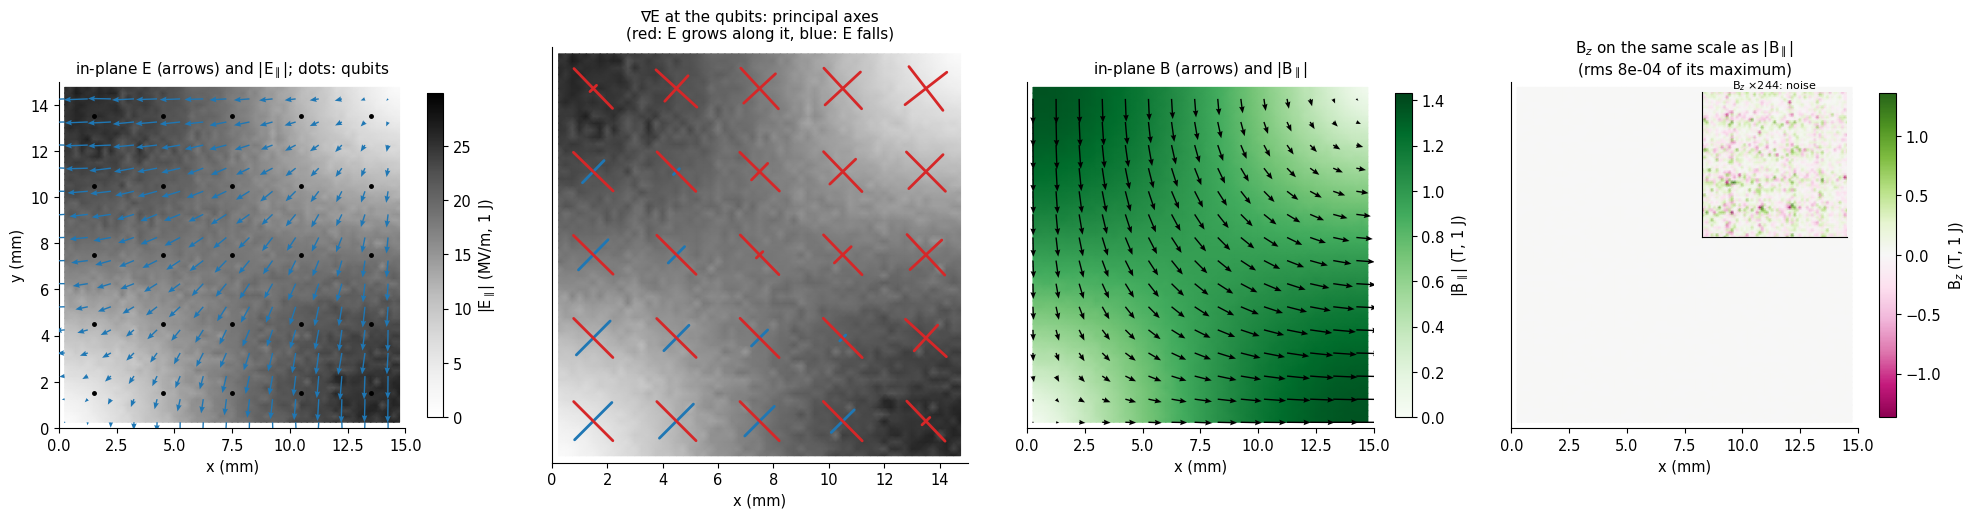

In [16]:
d, a_ = bare["110"], an["110"]
G, w_ = d["maps"], 2 * np.pi * d["f"]
gx_ = G["x"]
X_, Y_ = np.meshgrid(gx_, gx_)
Bt_ = np.hypot(G["curl"][0], G["curl"][1]) / w_
Bz_ = G["curl"][2] / w_
Bmax = Bt_.max()
fig, ax = plt.subplots(1, 4, figsize=(20, 4.9))
st = 4  # one arrow per mm
Em = np.hypot(G["E"][0], G["E"][1]) / 1e6
for a_k in (ax[0], ax[1]):
    im = a_k.pcolormesh(X_, Y_, Em, cmap="Greys", vmin=0, vmax=Em.max() * 1.1, shading="gouraud")
# (1) in-plane E arrows
ax[0].quiver(X_[::st, ::st], Y_[::st, ::st], G["E"][0][::st, ::st], G["E"][1][::st, ::st], color="tab:blue", angles="xy",
             scale_units="xy", scale=np.hypot(G["E"][0], G["E"][1]).max() / 1.1, width=0.004, headwidth=4, zorder=3)
for ij in QUBITS:
    ax[0].plot(*src[ij]["c"], "o", ms=2.5, color="k", zorder=6)
ax[0].set(aspect="equal", xlim=(0, 15), ylim=(0, 15), xlabel="x (mm)", ylabel="y (mm)",
          title="in-plane E (arrows) and |E$_\\parallel$|; dots: qubits")
plt.colorbar(im, ax=ax[0], shrink=0.78, label="|E$_\\parallel$| (MV/m, 1 J)")
# (2) gradient tensor at each qubit, drawn along its principal axes
for ij in QUBITS:
    c = src[ij]["c"]
    dE = d["fits"][ij]["dE"]
    ev, evec = np.linalg.eigh(0.5 * (dE + dE.T))
    for lam_, v_ in zip(ev, evec.T):
        L_ = 0.15 + 0.85 * abs(lam_) / np.abs(ev).max()
        ax[1].plot([c[0] - L_ * v_[0], c[0] + L_ * v_[0]], [c[1] - L_ * v_[1], c[1] + L_ * v_[1]],
                   color="tab:red" if lam_ > 0 else "tab:blue", lw=2.0, solid_capstyle="round", zorder=5)
ax[1].set(aspect="equal", xlim=(0, 15), ylim=(0, 15), xlabel="x (mm)", yticks=[],
          title="∇E at the qubits: principal axes\n(red: E grows along it, blue: E falls)")
# (3) in-plane B
im3 = ax[2].pcolormesh(X_, Y_, Bt_, cmap="Greens", vmin=0, vmax=Bmax * 1.05, shading="gouraud")
ax[2].quiver(X_[::st, ::st], Y_[::st, ::st], G["curl"][0][::st, ::st], G["curl"][1][::st, ::st], color="k", angles="xy",
             scale_units="xy", scale=np.hypot(G["curl"][0], G["curl"][1]).max() / 1.1, width=0.004, headwidth=4)
ax[2].set(aspect="equal", xlim=(0, 15), ylim=(0, 15), xlabel="x (mm)", yticks=[],
          title="in-plane B (arrows) and |B$_\\parallel$|")
plt.colorbar(im3, ax=ax[2], shrink=0.78, label="|B$_\\parallel$| (T, 1 J)")
# (4) B_z on the same scale, and on its own scale in the inset
im4 = ax[3].pcolormesh(X_, Y_, Bz_, cmap="PiYG", vmin=-Bmax, vmax=Bmax, shading="gouraud")
ax[3].set(aspect="equal", xlim=(0, 15), ylim=(0, 15), xlabel="x (mm)", yticks=[],
          title=f"B$_z$ on the same scale as |B$_\\parallel$|\n(rms {np.sqrt(np.mean(Bz_**2)) / Bmax:.0e} of its maximum)")
plt.colorbar(im4, ax=ax[3], shrink=0.78, label="B$_z$ (T, 1 J)")
ins = ax[3].inset_axes([0.55, 0.55, 0.42, 0.42])
bz_lim = np.abs(Bz_).max()
ins.pcolormesh(X_, Y_, Bz_ / bz_lim, cmap="PiYG", vmin=-1, vmax=1, shading="gouraud")
ins.set(xticks=[], yticks=[], aspect="equal")
ins.set_title(f"B$_z$ ×{Bmax / bz_lim:.0f}: noise", fontsize=8, pad=2)
plt.tight_layout()
show(fig, "fig05_chip_plane_E_B_Bz")

**Across the surface.** The three statements of Sec. 3 about what jumps and what does not can be read off the finite-element field at a point 1 µm below and above the silicon surface. The figure plots $E_x$ and $E_z$ and the corresponding $D$ (as $D/\varepsilon_0$) and the three components of $B$ against height, at a point away from any qubit, for the analytic mode (lines) and the finite-element one (dots): $E_x$ passes through the surface unchanged, $D_x$ jumps; $E_z$ jumps by $\varepsilon_r$ while $D_z$ is continuous; $B$ is continuous in every component and $B_z$ vanishes.

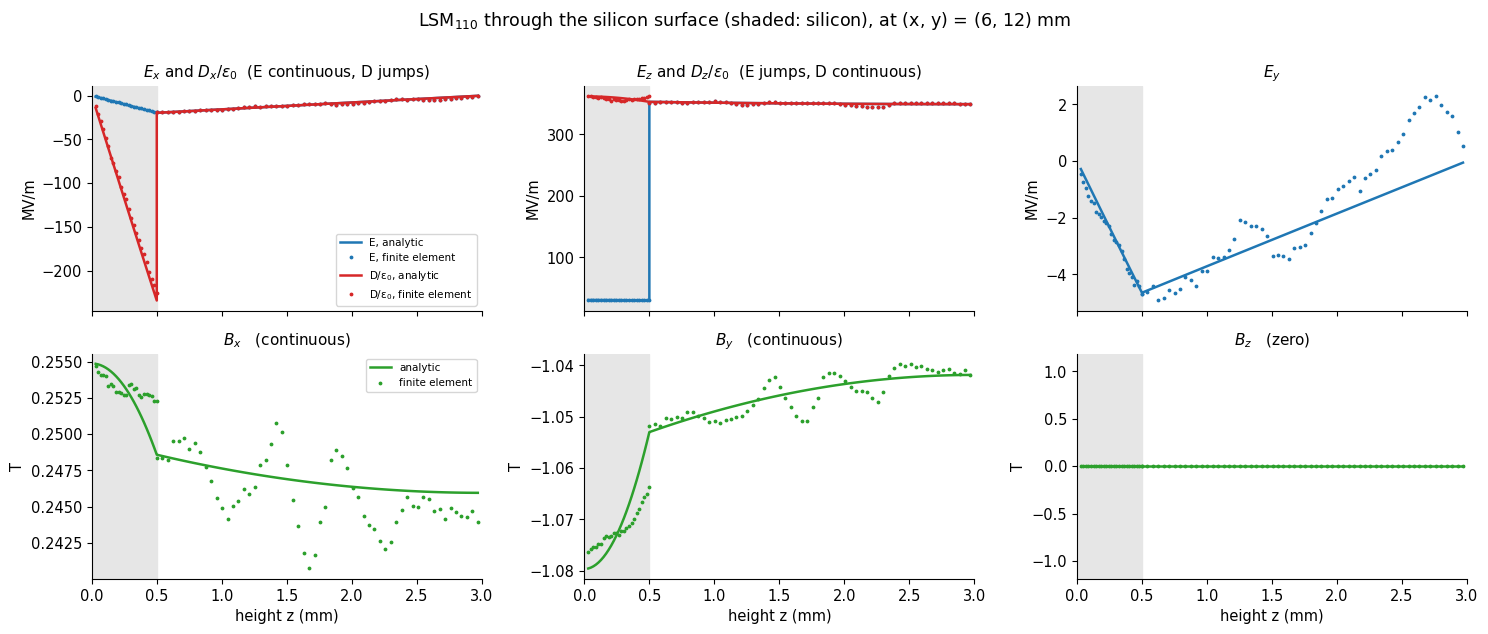

across the surface, finite element, value above / value below: E_x 1.000, D_x 0.084 (= 1/ε_r, ε_r = 11.9); E_z 11.56, D_z 0.971; B_x 0.985; max |B_z| / max |B_t| on this line = 1.7e-03


In [17]:
px_, py_ = 6.0, 12.0  # between qubits, 0.9 mm from the nearest paddle
zs_ = np.concatenate([np.linspace(0.03, t - 1e-5, 25), np.linspace(t + 1e-5, 2.97, 60)])
mode_ = bare["110"]["mode"]
fem_ = bare["110"]["fem"]
w110 = 2 * np.pi * bare["110"]["f"]
both = lambda p: np.vstack([mode_.field(p), mp.curl_E(fem_, mode_.u, p) / w110])  # E (V/m) and B (T)
# the finite-element value at a point is, as everywhere in this notebook, the fit over a small disc in that plane
fits_z = np.array([mp.disc_fit(both, (px_, py_, z_), R=0.6, N=300).value for z_ in zs_])
E_fe, B_fe = fits_z[:, :3].T, fits_z[:, 3:].T
E_a, B_a = mp.lsm_fields(an["110"], px_, py_, zs_)
eps_z = np.where(zs_ <= t, pm.DEVICE["eps_r"], 1.0)
fig, ax = plt.subplots(2, 3, figsize=(15, 6.3), sharex=True)
sub = slice(None)
panels = [(ax[0, 0], "$E_x$ and $D_x/\\varepsilon_0$", E_a[0] / 1e6, E_fe[0] / 1e6, eps_z, "MV/m", "E continuous, D jumps"),
          (ax[0, 1], "$E_z$ and $D_z/\\varepsilon_0$", E_a[2] / 1e6, E_fe[2] / 1e6, eps_z, "MV/m", "E jumps, D continuous"),
          (ax[0, 2], "$E_y$", E_a[1] / 1e6, E_fe[1] / 1e6, None, "MV/m", "")]
for a, ttl, an_, fe_, ez, unit, note in panels:
    a.axvspan(0, t, color="0.9", zorder=0)
    a.plot(zs_, an_, color="tab:blue", lw=1.8, label="E, analytic")
    a.plot(zs_[sub], fe_[sub], ".", color="tab:blue", ms=3.5, label="E, finite element")
    if ez is not None:
        a.plot(zs_, an_ * ez, color="tab:red", lw=1.8, label="D/ε$_0$, analytic")
        a.plot(zs_[sub], (fe_ * ez)[sub], ".", color="tab:red", ms=3.5, label="D/ε$_0$, finite element")
    a.set(title=f"{ttl}  ({note})" if note else ttl, ylabel=unit)
ax[0, 0].legend(fontsize=7.5, loc="best")
for a, k_, ttl in ((ax[1, 0], 0, "$B_x$"), (ax[1, 1], 1, "$B_y$"), (ax[1, 2], 2, "$B_z$")):
    a.axvspan(0, t, color="0.9", zorder=0)
    a.plot(zs_, B_a[k_], color="tab:green", lw=1.8, label="analytic")
    a.plot(zs_[sub], B_fe[k_][sub], ".", color="tab:green", ms=3.5, label="finite element")
    a.set(title=ttl + ("   (continuous)" if k_ < 2 else "   (zero)"), ylabel="T", xlabel="height z (mm)")
    if k_ == 2:
        a.set_ylim(-np.abs(B_a[:2]).max() * 1.1, np.abs(B_a[:2]).max() * 1.1)
ax[1, 0].legend(fontsize=7.5)
for a in ax[1]:
    a.set_xlim(0, 3)
fig.suptitle(f"LSM$_{{110}}$ through the silicon surface (shaded: silicon), at (x, y) = ({px_:g}, {py_:g}) mm", y=1.0)
plt.tight_layout()
show(fig, "fig06_profiles_through_interface")
# the jumps, from the finite-element field one micron on each side
lo, hi = np.argmin(np.abs(zs_ - (t - 1e-5))), np.argmax(zs_ > t)
ratio_Ex = E_fe[0][hi] / E_fe[0][lo]
ratio_Ez = E_fe[2][hi] / E_fe[2][lo]
ratio_Dz = (E_fe[2][hi]) / (pm.DEVICE["eps_r"] * E_fe[2][lo])
ratio_Bx = B_fe[0][hi] / B_fe[0][lo]
print(f"across the surface, finite element, value above / value below: E_x {ratio_Ex:.3f}, D_x {ratio_Ex / pm.DEVICE['eps_r']:.3f} (= 1/ε_r, ε_r = {pm.DEVICE['eps_r']}); "
      f"E_z {ratio_Ez:.2f}, D_z {ratio_Ez / pm.DEVICE['eps_r']:.3f}; B_x {ratio_Bx:.3f}; max |B_z| / max |B_t| on this line = {np.abs(B_fe[2]).max() / np.abs(B_fe[:2]).max():.1e}")
claim("E_t and B are continuous across the silicon surface; D_x and E_z jump by ε_r", "μ_r = 1, no surface charge or current at the surface",
      "FE field 1 µm either side of z = t", f"E_x ratio {ratio_Ex:.3f}, B_x ratio {ratio_Bx:.3f}, E_z ratio {ratio_Ez:.2f} (ε_r = 11.9), D_z ratio {ratio_Ez / pm.DEVICE['eps_r']:.3f}",
      "PASS" if abs(ratio_Ex - 1) < 0.03 and abs(ratio_Bx - 1) < 0.05 and abs(ratio_Ez / pm.DEVICE["eps_r"] - 1) < 0.1 else "CAVEAT")

## 5. The hierarchy of couplings

Everything is in place to compute each term of the series for every qubit and both modes, with the moments of Sec. 1–2 and the field of Sec. 4:

| term | formula | field input | source |
|---|---|---|---|
| $E_1$ | $\mathbf p\cdot\mathbf E$ | value at the qubit (disc fit) | finite element |
| $E_2$ | $\tfrac12S_{ij}\partial_iE_j$ | gradient (disc fit) | finite element |
| $E_3$ | $\tfrac16O_{ijk}\partial_i\partial_jE_k$ | third derivatives of the potential | **analytic** mode |
| exact | $\sum_kq_k\int_0^1\mathbf r_k\cdot\mathbf E\,d\lambda$ | all orders along every ray | finite element and analytic |
| $M_1$ | $\tilde m\,(\nabla\times\mathbf E)_z$ | value of $\omega B_z$ (disc fit) | finite element |
| $M_2$ | $\tfrac13\tilde M_{iz}\partial_i(\nabla\times\mathbf E)_z$ | gradient of $\omega B_z$ | finite element |

The octupole is computed from the analytic field because its size, about $10^{-3}$ of the dipole, is below the one-element scatter of the finite-element field (a fit cannot resolve third derivatives at that level); the finite element supplies the dipole, the quadrupole, the all-orders ray integral (which averages the element scatter over the paddles) and every magnetic term. $E_2$ and the magnetic terms are zero by symmetry, so what the finite element returns for them is a *measurement of the noise floor of the method*, to be compared with the nonzero terms next to it.

Couplings in MHz, $g/2\pi=fU/4$ with $f$ the mode's frequency, for qubits with large, medium and small coupling. The values are printed bare here; the floors that say which of the small ones are resolved are measured in Secs. 9–10, and the hierarchy and the maps of the couplings, with those floors on them, are Sec. 11.

In [18]:
terms = {tag: mp.terms_per_qubit(src, bare[tag]) for tag in bare}
show_q = [(0, 4), (2, 2), (0, 0), (4, 0)]
hdr = f"{'':>10}" + "".join(f"{'qubit ' + str(q_):>12}" for q_ in show_q)
for tag in bare:
    T = terms[tag]
    print(f"LSM{tag}  g/2π (MHz)   [pattern |g| at (i,j) = A cos(aπx/L) sin(bπy/L)]\n{hdr}")
    for lab, key, fmt in (("E1 dipole", "E1", "{:+.4f}"), ("E2 quad.", "E2", "{:+.1e}"), ("E3 oct.", "E3", "{:+.1e}"),
                          ("exact (FE)", "exact_fe", "{:+.4f}"), ("exact (an.)", "exact_a", "{:+.4f}"),
                          ("M1 mag.dip", "M1", "{:+.0e}"), ("M2 mag.quad", "M2", "{:+.0e}")):
        print(f"{lab:>12}" + "".join(f"{fmt.format(T[key][q_[1], q_[0]]):>12}" for q_ in show_q))
    print()

A_E1 = {tag: mp.pattern_amplitude(terms[tag]["E1"], an[tag]) for tag in bare}
A_ex = {tag: mp.pattern_amplitude(terms[tag]["exact_fe"], an[tag]) for tag in bare}
A_dip = {tag: pm.dipole_coupling(abs(px.mean()), an[tag])[1] / 1e6 for tag in bare}
print(f"{'':>8} {'|A| from E1':>12} {'|A| exact':>11} {'dipole formula':>15} {'paper (full wave)':>18}   (MHz)")
for tag, ppr in (("110", P["A_110"]), ("210", P["A_210"])):
    print(f"LSM{tag}: {abs(A_E1[tag]):12.2f} {abs(A_ex[tag]):11.2f} {A_dip[tag]:15.2f} {ppr / 1e6:18.1f}")

LSM110  g/2π (MHz)   [pattern |g| at (i,j) = A cos(aπx/L) sin(bπy/L)]
          qubit (0, 4)qubit (2, 2)qubit (0, 0)qubit (4, 0)
   E1 dipole    -15.3685     -7.8741     -2.4340     -0.3786
    E2 quad.    +1.3e-04    +4.3e-04    -8.5e-04    -1.2e-05
     E3 oct.    +1.5e-02    +7.7e-03    +2.4e-03    +3.6e-04
  exact (FE)    -15.4075     -7.8897     -2.4386     -0.3758
 exact (an.)    -15.3450     -7.8475     -2.4268     -0.3643
  M1 mag.dip      -2e-07      +2e-06      -9e-07      +1e-08
 M2 mag.quad      +6e-05      -2e-06      -4e-06      -1e-05

LSM210  g/2π (MHz)   [pattern |g| at (i,j) = A cos(aπx/L) sin(bπy/L)]
          qubit (0, 4)qubit (2, 2)qubit (0, 0)qubit (4, 0)
   E1 dipole    -47.9343     +0.0033     -7.5918     +7.5890
    E2 quad.    +1.5e-03    +2.8e-03    -2.3e-03    -1.6e-03
     E3 oct.    +1.0e-01    +5.1e-06    +1.6e-02    -1.6e-02
  exact (FE)    -48.0001     -0.0018     -7.5970     +7.5783
 exact (an.)    -47.7785     +0.0058     -7.5560     +7.5431
  M1 mag.

The dipole term and the sum over all electric orders differ by a fraction of a percent, the pattern amplitudes $|A|$ agree with the dipole formula of 4.41 and with the paper's Figs. 8–9, and every term that is zero by symmetry comes out several orders of magnitude below the dipole. The octupole is a stable correction of about one part in a thousand. Whether it is an extra term with its own dependence on position, or the same cosine-sine pattern again with a slightly different amplitude, is the question the next cell answers.

For the separable potential $\Phi\propto\sin k_xx\,\sin k_yy$ each additional pair of derivatives multiplies the same function by $-k^2$, so the answer can be written down: with $p$ along $x$ and the only surviving octupole components $O_{xxx}$ and $O_{xyy}$,

$$\frac{E_3}{E_1}=-\frac{k_x^2\,O_{xxx}+3k_y^2\,O_{xyy}}{6\,p_x},$$

independent of the qubit's position, a renormalization of the amplitude $A$ and not of the pattern. The check compares this closed form with the ratio computed qubit by qubit.

In [19]:
print(f"{'':>8} {'E3/E1 closed form':>18} {'median over qubits':>19} {'spread (std)':>13}")
for tag in bare:
    T, a_ = terms[tag], an[tag]
    kx, ky = a_.a * np.pi / (a_.Lx * 1e3), a_.b * np.pi / (a_.Ly * 1e3)  # 1/mm
    ratio_cf = -(kx**2 * Oxxx.mean() + 3 * ky**2 * Oxyy.mean()) / 6
    big = np.abs(T["E1a"]) > 0.05 * np.nanmax(np.abs(T["E1a"]))
    r_all = (T["E3"] / T["E1a"])[big]
    exact_gain = np.nanmax(np.abs(T["exact_a"][big] / T["E1a"][big] - 1))
    terms[tag]["ratio_cf"] = ratio_cf
    print(f"LSM{tag}: {ratio_cf:18.2e} {np.median(r_all):19.2e} {np.std(r_all):13.1e}   (exact/E1 - 1 ≤ {exact_gain:.1e} over qubits with |g| > 5% of the maximum)")
    claim(f"the octupole E3 renormalizes the amplitude of LSM{tag} and not its pattern",
          "separable potential; surviving octupole components O_xxx, O_xyy", "E3/E1 qubit by qubit, analytic field",
          f"E3/E1 = {np.median(r_all):.2e} ± {np.std(r_all):.0e}; closed form {ratio_cf:.2e}",
          "PASS" if np.std(r_all) < 5e-5 and abs(np.median(r_all) / ratio_cf - 1) < 0.02 else "FAIL", term=("E3 octupole (analytic field)", tag))
    claim(f"the electric dipole is correct to a fraction of a percent for LSM{tag}", "this qubit, this mode, qubits with |g| > 5% of the maximum",
          "(exact ray integral − E1)/E1, analytic field", f"≤ {exact_gain:.1e}", "PASS" if exact_gain < 5e-3 else "FAIL")

          E3/E1 closed form  median over qubits  spread (std)
LSM110:          -9.84e-04           -9.83e-04       7.6e-06   (exact/E1 - 1 ≤ 1.5e-03 over qubits with |g| > 5% of the maximum)
LSM210:          -2.11e-03           -2.11e-03       1.1e-05   (exact/E1 - 1 ≤ 2.6e-03 over qubits with |g| > 5% of the maximum)


### The dark columns

For LSM$_{210}$ the qubits of column $i=2$ ($x=7.5$ mm) sit on a node of $E_x$: their coupling is zero to every order, so what the pipeline returns for them measures its noise directly. Two numbers: the all-orders coupling computed in the finite-element field, and in the analytic field (with the same charges, which then isolates the asymmetry of the mesh's charges).

In [20]:
dark = {}
T = terms["210"]
a_ = an["210"]
g_dark = np.array([T["exact_fe"][j, 2] for j in range(5)])  # finite-element field, all orders
g_dark_q = np.array([T["exact_a"][j, 2] for j in range(5)])  # analytic field: only the asymmetry of the charges
dark["res"] = np.abs(g_dark).max()
dark["rel"] = dark["res"] / np.nanmax(np.abs(T["exact_a"]))
dark["rel_q"] = np.abs(g_dark_q).max() / np.nanmax(np.abs(T["exact_a"]))
Ex_dark = [abs(bare["210"]["fits"][(2, j)]["E0"][0]) / 1e6 for j in range(5)]
print(f"LSM210, column i = 2 (x = 7.5 mm, a node of E_x): the analytic coupling is zero to all orders.")
print(f"  finite-element field, charges from the mesh: {', '.join(f'{v * 1e3:+.0f}' for v in g_dark)} kHz = {dark['rel']:.1e} of the largest coupling")
print(f"  analytic field, charges from the mesh      : {', '.join(f'{v * 1e3:+.0f}' for v in g_dark_q)} kHz = {dark['rel_q']:.1e}"
      f"  (the asymmetry of the mesh's charges alone, p_y E_y)")
print(f"  in-plane E_x there, from the disc fit: {', '.join(f'{v:.3f}' for v in Ex_dark)} MV/m (the field maximum is {a_.E0x * 2 / 1e6:.1f} MV/m)")
claim("the qubits of column i = 2 are dark to LSM210", "they sit on a node of E_x (cos(2πx/L) = 0)", "FE ray coupling of the 5 qubits of the column",
      f"max |g| = {dark['res'] * 1e3:.0f} kHz = {dark['rel']:.1e} of the largest coupling (charges alone: {dark['rel_q']:.1e})",
      "PASS" if dark["rel"] < 1e-3 else ("CAVEAT" if dark["rel"] < 4e-3 else "FAIL"),
      "a residue near 10^-3 is the mesh noise of p_y E_y and of E_x; Sec. 9 follows it under refinement", term=("dark column i = 2", "210"))

LSM210, column i = 2 (x = 7.5 mm, a node of E_x): the analytic coupling is zero to all orders.
  finite-element field, charges from the mesh: +33, +1, -2, +35, +12 kHz = 7.3e-04 of the largest coupling
  analytic field, charges from the mesh      : +22, -7, +6, +40, +7 kHz = 8.4e-04  (the asymmetry of the mesh's charges alone, p_y E_y)
  in-plane E_x there, from the disc fit: 0.007, 0.028, 0.000, 0.012, 0.015 MV/m (the field maximum is 52.5 MV/m)


## 6. Is the zero a blind spot? The paddles, and the exact answer

The magnetic terms above are zero for two reasons that are both properties of the *bare* mode: it has $B_z=0$, and the series is expanded in it. A real processor changes this in two ways. The 200 paddles are perfect conductors in the field of the mode and carry induced currents, which have a normal magnetic field of their own, so the mode that the qubits actually sit in is not LSM$_{110}$ but its dressed version, which has $B_z\neq0$ near the paddles. And a coupling extracted from a model that computes the field at the qubit, as the series does, can be wrong in a way that no check inside the model reveals. Two independent tests follow.

**Test 1: the dressed mode.** Solve the mode again with every paddle present and every junction open, the model of 4.44. Its $B_z$ is the normal magnetic field of the induced currents on the paddles. The magnetic terms $M_1$ and $M_2$ are evaluated with that $B_z$ at each qubit, from a fit over the annulus $0.85$–$1.7$ mm around it, outside the qubit's own paddles (where the field is zero on the metal). The annulus contains the halo of the induced currents of the qubit's own paddles, which is generous: the expansion should see the field of everything *but* the qubit, and the nearest paddles of the neighbors are 2.4 mm from its center, outside the annulus.

**Test 2: the exact answer.** The induced-EMF coupling of 4.44, $g=\tfrac12\omega_mV_{\rm open}\sqrt{C/2E_m}$, uses the voltage across the open junction in the dressed mode. That voltage is the line integral of the *complete* electric field of the dressed mode across the gap. It contains every multipole of the field, the loading of the mode by all the paddles, and whatever is induced, so it holds no multipole expansion to truncate. The difference between it and the all-orders electric coupling of Sec. 5 is therefore a bound, up to its own discretization error, on everything the series leaves out: the magnetic terms and the paddle loading together.

In [21]:
dress = {}
for tag, cuts, f_guess in (("110", ("pmc", "pmc"), 6.5e9), ("210", ("pec", "pmc"), 10.2e9)):
    start = time.time()
    dress[tag] = mp.dressed_data(quarter, cuts, f_guess, an[tag], src, t + 1e-6, N=BUD["N_fit"], maps=True, keep=True)
    dress[tag]["fem"]._factors.clear()
    TIMES["dressed " + tag] = time.time() - start
    print(f"LSM{tag} with the 50 paddles of the quarter: {dress[tag]['f'] / 1e9:.4f} GHz (bare {bare[tag]['f'] / 1e9:.4f}), "
          f"{dress[tag]['n_dofs']:,} unknowns, {TIMES['dressed ' + tag]:.0f} s")
for tag in bare:
    terms[tag].update(mp.terms_per_qubit(src, bare[tag], dress[tag]))

# the normal magnetic field, bare and dressed, over the quarter chip, relative to the in-plane field of the mode
print(f"\n{'':>8} {'rms B_z / max B_t':>19} {'':>3}")
for tag in bare:
    out_ = []
    for name, dd in (("bare", bare[tag]), ("dressed", dress[tag])):
        G_, w_ = dd["maps"], 2 * np.pi * dd["f"]
        Bt_max = np.hypot(G_["curl"][0], G_["curl"][1]).max() / w_
        rms = np.sqrt(np.mean((G_["curl"][2] / w_) ** 2)) / Bt_max
        out_.append(f"{name} {rms:.1e}")
        dd["Bz_rms"] = rms
    print(f"LSM{tag}:   " + "   ".join(out_) + "   (on the 59 × 59 grid of the quarter)")

LSM110 with the 50 paddles of the quarter: 6.4880 GHz (bare 6.4917), 323,834 unknowns, 47 s


LSM210 with the 50 paddles of the quarter: 10.2202 GHz (bare 10.2326), 322,566 unknowns, 49 s

           rms B_z / max B_t    
LSM110:   bare 8.1e-04   dressed 4.0e-03   (on the 59 × 59 grid of the quarter)
LSM210:   bare 1.3e-03   dressed 8.3e-03   (on the 59 × 59 grid of the quarter)


The dressed mode's $B_z$ is larger than the bare mode's by a factor of a few, on this grid, and is concentrated near the paddles. It is at the half-percent level of the in-plane magnetic field, not at the noise level. A zoom on four neighboring qubits shows where it lives. Same color scale for all four panels, a few percent of the maximum in-plane $B$:

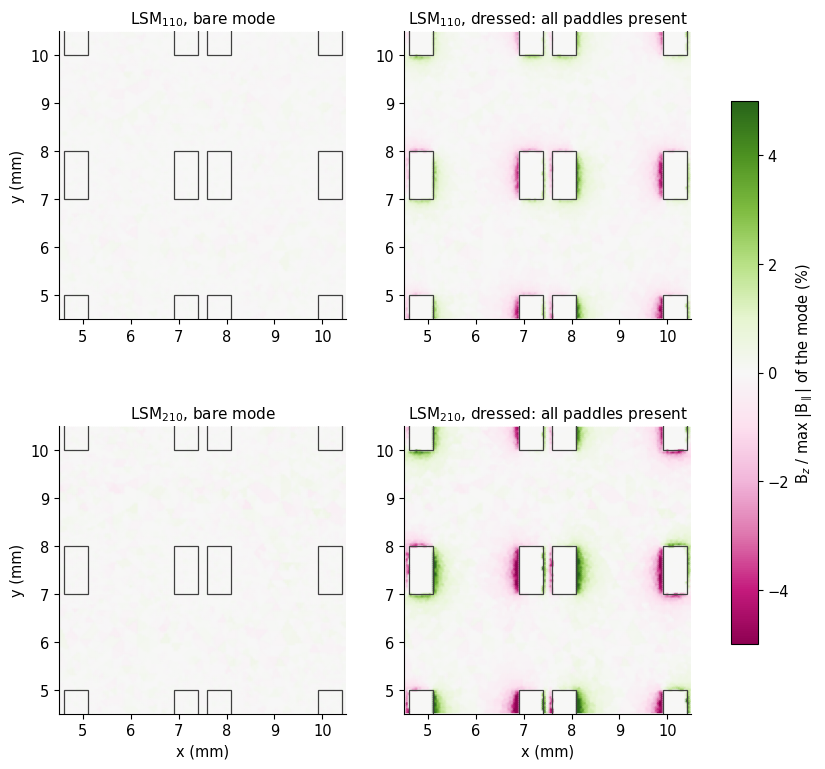

In [22]:
win = (4.5, 10.5)  # mm, four qubits of the quarter, with the one at (7.5, 7.5) in the middle
gz = np.linspace(win[0] + 0.02, win[1] - 0.02, 150)
Xz, Yz = np.meshgrid(gz, gz)
ptz = np.vstack([Xz.ravel(), Yz.ravel(), np.full(Xz.size, t + 1e-6)])
fig, ax = plt.subplots(2, 2, figsize=(10.2, 9.4))
zoom = {}
for r_, tag in enumerate(("110", "210")):
    for c_, (name, dd) in enumerate((("bare mode", bare[tag]), ("dressed: all paddles present", dress[tag]))):
        w_ = 2 * np.pi * dd["f"]
        Bz_zoom = (mp.curl_E(dd["fem"], dd["mode"].u, ptz)[2] / w_).reshape(Xz.shape)
        Bt_max = np.hypot(bare[tag]["maps"]["curl"][0], bare[tag]["maps"]["curl"][1]).max() / (2 * np.pi * bare[tag]["f"])
        lim = 0.05 * Bt_max
        zoom[(tag, name)] = Bz_zoom / Bt_max
        im = ax[r_, c_].pcolormesh(Xz, Yz, Bz_zoom / Bt_max * 100, cmap="PiYG", vmin=-5, vmax=5, shading="gouraud")
        for poly in package.metals.values():
            if win[0] - 1 < poly[:, 0].mean() < win[1] + 1 and win[0] - 1 < poly[:, 1].mean() < win[1] + 1:
                ax[r_, c_].fill(poly[:, 0], poly[:, 1], facecolor="none", edgecolor="0.25", lw=0.9)
        ax[r_, c_].set(aspect="equal", xlim=win, ylim=win, title=f"LSM$_{{{tag}}}$, {name}",
                       xlabel="x (mm)" if r_ == 1 else None, ylabel="y (mm)" if c_ == 0 else None)
fig.colorbar(im, ax=ax, shrink=0.75, label="B$_z$ / max |B$_\\parallel$| of the mode (%)")
show(fig, "fig09_Bz_bare_vs_dressed")

The paddles do induce a normal field. It sits at the edges of the paddles and points in the directions the in-plane field of the mode would drive currents. This is what the dressed-mode test measures: evaluate $M_1$ and $M_2$ with that field. $M_1$ uses its value at the center of the qubit, extrapolated from the annulus; $M_2$ its slope.

In [23]:
print(f"{'':>8} {'bare M1+M2':>14} {'dressed M1+M2':>15} {'E1 (largest)':>14}   max over the 25 qubits, |g|/2π")
rel_bare, rel_dress = {}, {}
for tag in bare:
    T = terms[tag]
    e1 = np.nanmax(np.abs(T["E1"]))
    mb = np.nanmax(np.abs(T["M1"] + T["M2"]))
    md = np.nanmax(np.abs(T["M1d"] + T["M2d"]))
    rel_bare[tag], rel_dress[tag] = mb / e1, md / e1
    print(f"LSM{tag}: {mb * 1e3:11.4f} kHz {md * 1e3:12.3f} kHz {e1:11.2f} MHz   -> bare {mb / e1:.1e}, dressed {md / e1:.1e} of E1")
# what the same moments would give if a mode had a normal field as large as its in-plane one, varying on the wavelength of the mode
for tag in bare:
    a_, f_ = an[tag], bare[tag]["f"]
    w_ = 2 * np.pi * f_
    Bt_max = np.hypot(bare[tag]["maps"]["curl"][0], bare[tag]["maps"]["curl"][1]).max() / w_
    k_ = np.hypot(a_.a, a_.b) * np.pi / (a_.Lx)
    U_m2 = abs(Myz.mean()) / 3 * w_ * Bt_max * k_
    U_m1_asym = 0.15 * px.mean() * 1e-3 * w_ * Bt_max
    print(f"LSM{tag}, if B_z were as large as max B_t: M2 would be {mp.g_MHz(f_, U_m2) * 1e3:.0f} kHz = {mp.g_MHz(f_, U_m2) / np.nanmax(np.abs(terms[tag]['E1'])):.1e} of E1"
          f" (symmetric qubit); M1 for an m̃_z of 0.15 p·1 mm would be {mp.g_MHz(f_, U_m1_asym):.1f} MHz")
    terms[tag]["M2_whatif"] = mp.g_MHz(f_, U_m2)
claim("the magnetic coupling is zero for the bare package mode", "flat symmetric qubit; bare LSM mode; Poisson sheet current",
      "M1 + M2 with the FE curl E, 25 qubits", f"max |M1 + M2|/max |E1|: LSM110 {rel_bare['110']:.1e}, LSM210 {rel_bare['210']:.1e}",
      "PASS" if max(rel_bare.values()) < 1e-4 else "CAVEAT", "a floor, not a measurement of a nonzero value; M2 uses the factor-2 model of M̃_yz",
      term=("M1 + M2, bare mode", "110"))
claim("the magnetic coupling stays small with the 200 paddles present", "dressed mode, annulus fit around each qubit",
      "M1 + M2 with the dressed-mode B_z, 25 qubits", f"max |M1 + M2|/max |E1|: LSM110 {rel_dress['110']:.1e}, LSM210 {rel_dress['210']:.1e}",
      "PASS" if max(rel_dress.values()) < 1e-3 else "CAVEAT",
      "B_z of the dressed mode is a few times its bare noise floor; the annulus fit extrapolates inward over the qubit's own paddles",
      term=("M1 + M2, dressed mode", "110"))

             bare M1+M2   dressed M1+M2   E1 (largest)   max over the 25 qubits, |g|/2π
LSM110:      0.0667 kHz        0.265 kHz       15.37 MHz   -> bare 4.3e-06, dressed 1.7e-05 of E1
LSM210:      0.5361 kHz        2.194 kHz       47.93 MHz   -> bare 1.1e-05, dressed 4.6e-05 of E1
LSM110, if B_z were as large as max B_t: M2 would be 52 kHz = 3.4e-03 of E1 (symmetric qubit); M1 for an m̃_z of 0.15 p·1 mm would be 5.1 MHz
LSM210, if B_z were as large as max B_t: M2 would be 257 kHz = 5.4e-03 of E1 (symmetric qubit); M1 for an m̃_z of 0.15 p·1 mm would be 16.2 MHz


The magnetic coupling, with the induced $B_z$ of the dressed mode and the factor-2 model of the current, is a few times the bare floor but still only about $10^{-5}$ to $5\times10^{-5}$ of the electric coupling. The what-if lines give the scale that the same moments would reach if $B_z$ were as strong as the in-plane field: for a symmetric qubit a few $10^{-3}$ of $E_1$, which is why the *absence* of $B_z$ matters; for a qubit with a magnetic dipole moment ($\tilde m_z\neq0$, Sec. 7) it would be comparable to the electric coupling, which is why Sec. 8 looks for modes that have it.

**Test 2: the exact answer.** The induced-EMF couplings of every qubit, from the voltages of the dressed modes, against the all-orders electric coupling of Sec. 5 (finite-element field, ray integral):

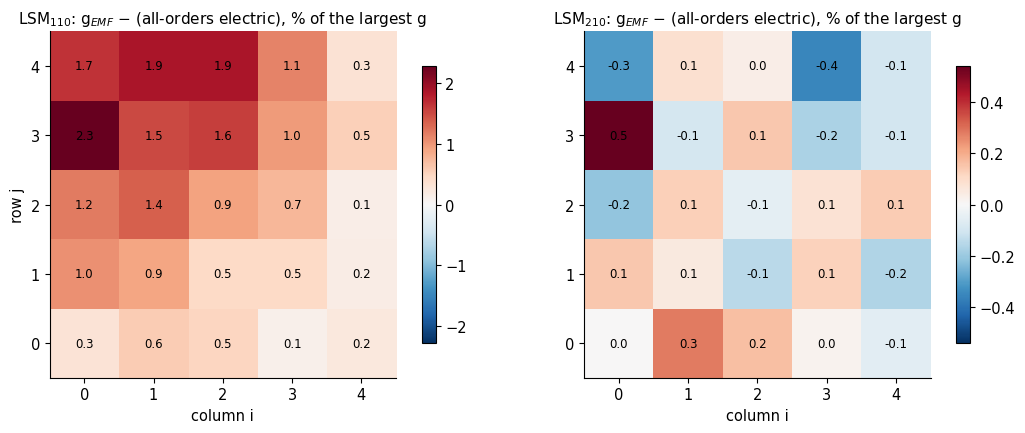

LSM110: g_EMF / (all-orders electric) − 1 = -2.31% ± 0.76% over the qubits with |g| above 5% of the maximum; largest residual 2.3% of the largest coupling
LSM210: g_EMF / (all-orders electric) − 1 = -0.22% ± 0.68% over the qubits with |g| above 5% of the maximum; largest residual 0.5% of the largest coupling


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 4.3))
resid = {}
for a_k, tag in zip(ax, ("110", "210")):
    T = terms[tag]
    gmax = np.nanmax(np.abs(T["exact_fe"]))
    res = (T["emf"] - T["exact_fe"]) / gmax * 100  # percent of the largest coupling
    resid[tag] = res
    lim = np.nanmax(np.abs(res))
    im = a_k.imshow(res, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    for jj in range(5):
        for ii in range(5):
            a_k.text(ii, jj, f"{res[jj, ii]:.1f}", ha="center", va="center", fontsize=8.5)
    a_k.set(title=f"LSM$_{{{tag}}}$: g$_{{EMF}}$ − (all-orders electric), % of the largest g", xticks=range(5), yticks=range(5),
            xlabel="column i", ylabel="row j" if tag == "110" else None)
    plt.colorbar(im, ax=a_k, shrink=0.8)
plt.tight_layout()
show(fig, "fig10_emf_residual")
for tag in bare:
    T = terms[tag]
    big = np.abs(T["exact_a"]) > 0.05 * np.nanmax(np.abs(T["exact_a"]))
    rr = (T["emf"] / T["exact_fe"] - 1)[big]
    resid[tag + "_ratio"] = (rr.mean(), rr.std())
    print(f"LSM{tag}: g_EMF / (all-orders electric) − 1 = {rr.mean():+.2%} ± {rr.std():.2%} over the qubits with |g| above 5% of the maximum;"
          f" largest residual {np.nanmax(np.abs(resid[tag])):.1f}% of the largest coupling")

The EMF coupling is lower in magnitude than the electric series, by about two percent for LSM$_{110}$ and less for LSM$_{210}$ (the printout above), and the residual follows the *pattern of the coupling itself*: largest where the coupling is largest, with no structure of its own. That is what a discretization error of the voltage looks like, and not what a missing physical term, which would carry its own pattern, looks like. The induced-EMF method is the quantity that 4.44 found to depend on the paddle-edge mesh: its $|A|$ rises from 14.9 to 15.6 MHz as the mesh is refined from 0.1 to 0.05 mm, because the elements cannot follow the charge crowding at the paddle edges and underestimate the voltage across the gap, while the multipole side takes its charges from second-order electrostatics. Whether the residual *converges to zero* under refinement is therefore the real test, and it is the last panel of Sec. 9; this section reports the residual on the mesh set by `BUDGET`, as an upper bound on all neglected physics at that mesh. Any magnetic or paddle-loading contribution is inside it.

<!-- TODO-ZKM: confirm that the open-junction induced EMF captures the inductive (g_L) part of the coupling in the paper's circuit model; the text treats it as the complete coupling of the dressed mode and reads the residual as a bound on neglected terms. -->

**A remark on the paper's $g_L$.** The impedance-matrix fit of the paper (and of 4.45) splits the coupling of qubit (0,0) into a capacitive part $g_C$ and an inductive part $g_L=-0.25$ MHz, about 12% of $g_C$. That split is the one of the *lumped circuit* in which the qubit and the package are two LC oscillators with a capacitance and an inductance matrix: the inductive coupling $g_L$ comes from the mutual inductance of the circuit's loops and from the mode's own geometric inductance, and a lumped model has no way to say which field of the mode drives which part of the qubit. The multipole split of this notebook is a different decomposition, of the electromagnetic *field* seen by the charges and currents of the flat qubit, and the two do not have to line up term by term.

<!-- TODO-ZKM: co-authored paper; confirm the wording of this remark about the paper's g_L before it is published. -->

## 7. Breaking the symmetry: the quadrupole, and the origin

Every zero in Secs. 1–2 rests on a symmetry. A theorem is only informative if its conditions can be broken, so this section breaks them one at a time and watches the zeros turn into numbers. Two things first need care: what a quadrupole *is* about a source that has a dipole, and which of its components can be removed by moving the origin.

**Origin dependence.** The moments depend on where the origin is. For a neutral source, shifting the origin by $\mathbf d$ leaves $\mathbf p$ alone but changes

$$S_{ij}\;\to\;S_{ij}-d_ip_j-p_id_j,\qquad \tilde m_z\;\to\;\tilde m_z-\tfrac12(\mathbf d\times\mathbf p)_z .$$

With the dipole along $x$ this means $S_{xx}\to S_{xx}-2d_xp_x$ and $S_{xy}\to S_{xy}-d_yp_x$: **$S_{xx}$ and $S_{xy}$ are the dipole's own position, not a shape.** If $S_{xx}\neq0$ the "center" of the dipole is displaced from the origin along $x$ by $d_x=S_{xx}/(2p_x)$, and moving the origin there removes it; the dipole then simply sees the field at its own center, and the coupling is the same to the order that the series is truncated. Likewise the junction-midpoint origin of this notebook, if the junction is not on the symmetry axis of the paddles, produces an $S_{xy}$ that is the offset of the junction from the dipole's center. What cannot be removed is $S_{yy}$, the spread of the charge across the dipole axis: **$S_{yy}$ is the quadrupole of the source about its own dipole center.** The same shift changes $\tilde m_z$ by $-\tfrac12\mathbf d\times\mathbf p$, so the magnetic dipole of a source that has an electric dipole is also origin-dependent, and the intrinsic value is the one about the dipole center.

**Cartesian or traceless.** Textbooks [2] use the traceless quadrupole $Q_{ij}=3S_{ij}-\delta_{ij}S_{kk}$, whose coupling $\tfrac16Q_{ij}\partial_iE_j$ differs from the Cartesian $\tfrac12S_{ij}\partial_iE_j$ by $\tfrac16S_{kk}\,\nabla\!\cdot\!\mathbf E$, and drops that term because $\nabla\!\cdot\!\mathbf E=0$ in vacuum. For a flat source on a dielectric surface the term cannot be dropped so lightly. The traceless form needs the $zz$ component, $\partial_zE_z$, and the qubit sits *in* the surface where $E_z$ jumps by $\varepsilon_r$ and the divergence of $\mathbf E$ is a bound-charge sheet, so there is no well-defined single value of $\nabla\!\cdot\!\mathbf E$ at the source. The Cartesian in-plane form needs only $\partial_iE_j$ for $i,j\in\{x,y\}$, the in-plane gradient of the continuous in-plane field, and is used throughout. The cell below computes the size of the term the traceless form would have to supply.

The three qubits of this section each break one condition. All are solved alone in the small box of Sec. 2, which costs seconds, and placed at a qubit position of the array for the coupling: **(i) symmetric**, the reference; **(ii) unequal paddles**, the right one a little more than half as tall as the left (breaks the $x\to-x$ mirror, so $S_{yy}$ is allowed); **(iii) the junction off the axis** by 0.3 mm (breaks the $y\to-y$ mirror of the current, so $\tilde m_z$ is allowed, while the charge is unchanged).

In [25]:
if RUN_SYMMETRY_BREAKING:
    start = time.time()
    variants = {"symmetric": box_package(), "unequal paddles": box_package(pad_right=(0.1, 0.6, -0.3, 0.3)),
                "junction off the axis": box_package(junction_y=0.3)}
    VAR = {}
    th_v = np.linspace(0, 2 * np.pi, 361)[:-1]
    for name, pk_v in variants.items():
        mesh_v = pm.mesh_package(pk_v, region="full", h_metal=0.05, h_max=0.8)
        es_v = pm.Electrostatics(mesh_v, order=BUD["order"])
        sv = mp.qubit_sources(es_v, mesh_v, pk_v, [(0, 0)], order=BUD["order"])[(0, 0)]
        circ_v = np.vstack([cb + 2.0 * np.cos(th_v), cb + 2.0 * np.sin(th_v), np.full(th_v.size, t + 1e-6)])
        sv["phi_circle"] = es_v.potential("Q_0_0.pad_left", "Q_0_0.pad_right", circ_v)
        del es_v
        VAR[name] = sv
    TIMES["symmetry breaking"] = time.time() - start
    print(f"three qubits solved in {TIMES['symmetry breaking']:.0f} s")
    print(f"{'':>24} {'p_x (C m)':>11} {'S_xx':>10} {'S_xy':>10} {'S_yy':>10} {'m_z':>10}   (S in C m², m in C m², about the junction midpoint)")
    for name, sv in VAR.items():
        m_ = sv["mom"]
        print(f"{name:>24} {m_['p'][0]:11.3e} {m_['S'][0, 0]:10.1e} {m_['S'][0, 1]:10.1e} {m_['S'][1, 1]:10.1e} {sv['cur'].m():10.1e}")

    print(f"\nabout the dipole center (shift d chosen to remove S_xx and S_xy):")
    print(f"{'':>24} {'d (µm)':>16} {'S_yy/(p·1 mm)':>14} {'m_z/(p·1 mm)':>13} {'|M_yz| (p mm²)':>15}")
    for name, sv in VAR.items():
        d_ = mp.dipole_center(sv["mom"])
        sh = mp.shift_origin(sv["mom"], d_)
        cur_s = sv["cur"].shifted(d_)
        sv["d"], sv["cur_dc"], sv["S_dc"] = d_, cur_s, sh["S"]
        p_ = sv["mom"]["p"][0]
        print(f"{name:>24} ({d_[0] * 1e6:+6.1f}, {d_[1] * 1e6:+6.1f}) {sh['S'][1, 1] / (p_ * 1e-3):14.3f} {cur_s.m() / (p_ * 1e-3):13.3f} {abs(cur_s.M()[1]) / p_ / 1e-6:15.3f}")
        sv["Syy_rel"] = sh["S"][1, 1] / (p_ * 1e-3)
        sv["mz_dc_rel"] = cur_s.m() / (p_ * 1e-3)
    # the shift identity of the current: m_z -> m_z - (d x p)/2
    sv = VAR["junction off the axis"]
    mz_formula = sv["cur"].m() - 0.5 * (sv["d"][0] * sv["mom"]["p"][1] - sv["d"][1] * sv["mom"]["p"][0])
    print(f"\ncheck of the shift rule for m_z, off-axis junction: moved current {sv['cur_dc'].m():.3e}, formula {mz_formula:.3e} C m²")
    yJ = 0.3e-3
    print(f"about the dipole center m_z = {sv['cur_dc'].m():.3e} C m²; compare −p_x·y_J = {-sv['mom']['p'][0] * yJ:.3e} C m² "
          f"(a charge p_x/Δx carried across the gap at height y_J above the charge center: the moment is the dipole times the offset)")
else:
    print("RUN_SYMMETRY_BREAKING = False: skipped")

three qubits solved in 5 s
                           p_x (C m)       S_xx       S_xy       S_yy        m_z   (S in C m², m in C m², about the junction midpoint)
               symmetric   3.770e-10    3.0e-16    4.0e-18   -6.9e-17    4.2e-17
         unequal paddles   3.410e-10    2.7e-15    1.8e-18   -3.3e-14   -9.8e-17
   junction off the axis   3.774e-10   -8.3e-17   -1.1e-13    1.3e-16   -5.5e-14

about the dipole center (shift d chosen to remove S_xx and S_xy):
                                   d (µm)  S_yy/(p·1 mm)  m_z/(p·1 mm)  |M_yz| (p mm²)
               symmetric (  +0.4,   +0.0)         -0.000         0.000           0.030
         unequal paddles (  +3.9,   +0.0)         -0.097        -0.000           0.016
   junction off the axis (  -0.1, -299.4)         -0.000        -0.297           0.085

check of the shift rule for m_z, off-axis junction: moved current -1.120e-13, formula -1.120e-13 C m²
about the dipole center m_z = -1.120e-13 C m²; compare −p_x·y_J = -1.132e-13 

Unequal paddles give $S_{yy}\neq0$ about the dipole's own center, at about a tenth of $p\cdot1$ mm, and about the same $S_{xx}$ offset that the dipole center absorbs. The off-axis junction leaves the charge distribution alone, so $S_{yy}$ stays at its reference value, but the origin at the junction is displaced from the dipole center and the shift rule moves $S_{xy}$ and $\tilde m_z$ together: the intrinsic $\tilde m_z$, about the dipole center, is the number in the second table. Now the angular harmonics of the potential on the 2 mm circle, which show the quadrupole as a shape:

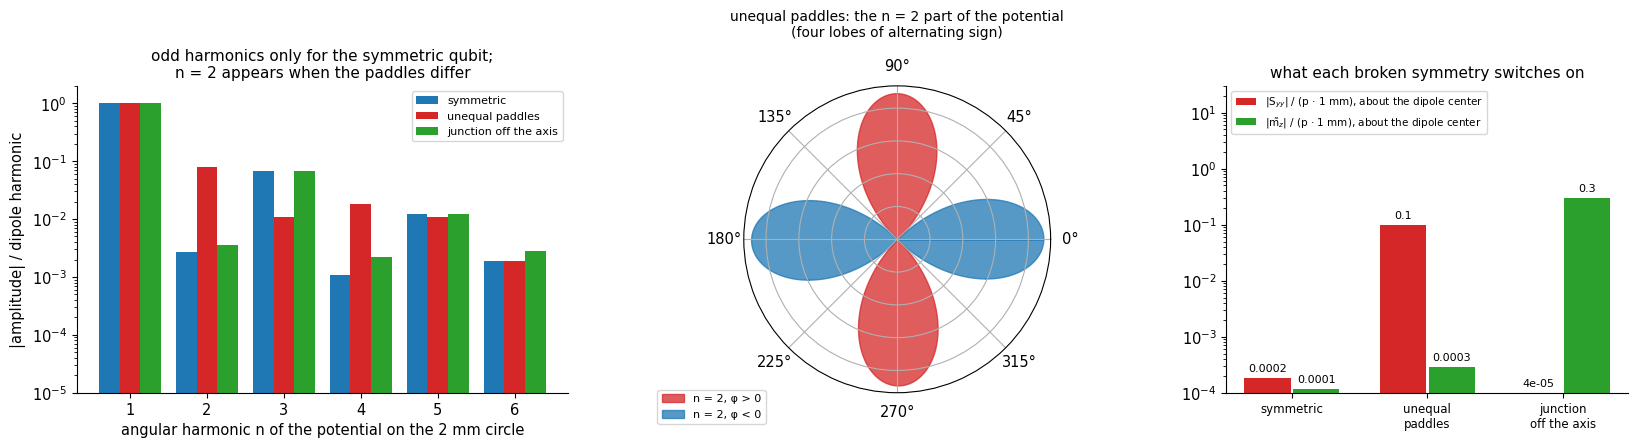

In [26]:
if RUN_SYMMETRY_BREAKING:
    fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1.0, 0.9]))
    cols = {"symmetric": "tab:blue", "unequal paddles": "tab:red", "junction off the axis": "tab:green"}
    harm = {}
    for name, sv in VAR.items():
        a_h, b_h = harmonics(th_v, sv["phi_circle"], 6)
        harm[name] = (a_h, b_h)
    width = 0.27
    for k_, (name, (a_h, b_h)) in enumerate(harm.items()):
        amp = np.hypot(a_h, b_h)
        ax[0].bar(np.arange(1, 7) + (k_ - 1) * width, amp / amp[0], width, color=cols[name], label=name)
    ax[0].set_yscale("log")
    ax[0].set(xlabel="angular harmonic n of the potential on the 2 mm circle", ylabel="|amplitude| / dipole harmonic",
              title="odd harmonics only for the symmetric qubit;\nn = 2 appears when the paddles differ", xticks=range(1, 7), ylim=(1e-5, 2))
    ax[0].legend(fontsize=8, loc="upper right")
    # (middle) the quadrupole part of the potential: the n = 2 harmonic of the unequal-paddle qubit, as the four lobes it makes
    phi_fine = np.linspace(0, 2 * np.pi, 400)
    ax[1].remove()
    axp = fig.add_subplot(1, 3, 2, projection="polar")
    a_h, b_h = harm["unequal paddles"]
    n2 = a_h[1] * np.cos(2 * phi_fine) + b_h[1] * np.sin(2 * phi_fine)
    axp.fill_between(phi_fine, 0, np.where(n2 > 0, n2, 0), color="tab:red", alpha=0.75, label="n = 2, φ > 0")
    axp.fill_between(phi_fine, 0, np.where(n2 < 0, -n2, 0), color="tab:blue", alpha=0.75, label="n = 2, φ < 0")
    axp.set_title("unequal paddles: the n = 2 part of the potential\n(four lobes of alternating sign)", fontsize=10, pad=16)
    axp.set_yticklabels([])
    axp.legend(fontsize=8, loc="lower left", bbox_to_anchor=(-0.3, -0.12))
    # (right) the dipole's own center and the quadrupole against the paddle geometry
    names = list(VAR)
    Syy = [VAR[n]["Syy_rel"] for n in names]
    mzr = [VAR[n]["mz_dc_rel"] for n in names]
    xk = np.arange(len(names))
    ax[2].bar(xk - 0.18, np.abs(Syy), 0.34, color="tab:red", label="|S$_{yy}$| / (p · 1 mm), about the dipole center")
    ax[2].bar(xk + 0.18, np.abs(mzr), 0.34, color="tab:green", label="|m̃$_z$| / (p · 1 mm), about the dipole center")
    ax[2].set_yscale("log")
    ax[2].set_xticks(xk, [n.replace(" ", "\n", 1) for n in names], fontsize=8.5)
    for k_, (sv_, mv_) in enumerate(zip(Syy, mzr)):
        ax[2].text(k_ - 0.18, max(abs(sv_), 1e-4) * 1.3, f"{abs(sv_):.1g}", ha="center", fontsize=8)
        ax[2].text(k_ + 0.18, max(abs(mv_), 1e-4) * 1.3, f"{abs(mv_):.1g}", ha="center", fontsize=8)
    ax[2].set(title="what each broken symmetry switches on", ylim=(1e-4, 30))
    ax[2].legend(fontsize=7.5, loc="upper left")
    plt.tight_layout()
    show(fig, "fig11_symmetry_breaking")

The symmetric qubit has only odd harmonics. Unequal paddles add an $n=2$ harmonic, four lobes of alternating sign, which is the quadrupole of the charge, and the off-axis junction changes nothing in the potential at all, because the junction is open for the electrostatics: its effect is entirely on the current.

**How much do they couple?** Place each qubit at the position of array qubit (1,2) and compute the electric terms in the analytic LSM$_{110}$ field. $E_2=\tfrac12S_{ij}\partial_iE_j$ splits into its three Cartesian parts; the dipole center shifts the expansion point and takes the $xx$ and $xy$ parts with it.

In [27]:
if RUN_SYMMETRY_BREAKING:
    qc = np.array(centers[(1, 2)])
    a_ = an["110"]
    print(f"qubit at (1,2) = {tuple(float(v) for v in qc)} mm in LSM110 (E_x-dominated there); g/2π in MHz")
    print(f"{'':>24} {'E1':>9} {'E2: xx':>9} {'xy':>9} {'yy':>9} {'E3':>9} {'exact':>9}  {'E2/E1':>8}  {'(E1+E2) from dipole center':>28}  {'trace term (1/6)Skk ∇·E':>26}")
    for name, sv in VAR.items():
        m_ = sv["mom"]
        d2 = phi_d2 = mp.phi_derivs(a_, qc[0], qc[1], 2)  # d_i d_j Phi
        E1 = mp.g_MHz(a_.f, mp.multipole_terms(m_, a_, qc, 3)[0])
        E2_parts = [mp.g_MHz(a_.f, -0.5 * m_["S"][i_, j_] * phi_d2[i_, j_] * (1 if i_ == j_ else 2)) for i_, j_ in ((0, 0), (0, 1), (1, 1))]
        E3 = mp.g_MHz(a_.f, mp.multipole_terms(m_, a_, qc, 3)[2])
        ex = mp.g_MHz(a_.f, mp.exact_analytic(a_, qc, sv["r"], sv["q"]))
        # expansion about the dipole center: the same coupling, a different split between E1 and E2
        qd = qc + sv["d"] * 1e3
        m_dc = mp.moments(sv["r"] - sv["d"][:, None], sv["q"])
        t_dc = mp.multipole_terms(m_dc, a_, qd, 3)
        E12_dc = mp.g_MHz(a_.f, t_dc[0] + t_dc[1])
        # the term of the traceless form: (1/6) S_kk div_t E, div_t E_t = -laplacian Phi = gamma^2 Phi
        trace_term = mp.g_MHz(a_.f, np.trace(m_["S"]) / 6 * a_.gamma**2 * mp.lsm_potential(a_, qc[0], qc[1]))
        sv["E2_rel"] = sum(E2_parts) / E1
        print(f"{name:>24} {E1:9.4f} {E2_parts[0]:9.4f} {E2_parts[1]:9.4f} {E2_parts[2]:9.4f} {E3:9.4f} {ex:9.4f}  {sum(E2_parts) / E1:8.1e}  {E12_dc:28.4f}  {trace_term:26.4f}")
        sv["trace_term"] = trace_term
    sv = VAR["unequal paddles"]
    S_dc = sv["S_dc"]
    E2_yy = mp.g_MHz(a_.f, -0.5 * S_dc[1, 1] * mp.phi_derivs(a_, qc[0], qc[1], 2)[1, 1])
    print(f"\nunequal paddles: the quadrupole about the dipole center, ½ S_yy ∂_yE_y, couples {E2_yy * 1e3:+.0f} kHz = {E2_yy / mp.g_MHz(a_.f, mp.multipole_terms(sv['mom'], a_, qc, 3)[0]):.1e} of the dipole coupling at this position;"
          f" the traceless form would have to add {sv['trace_term'] * 1e3:+.0f} kHz from ∂_zE_z, at an interface.")
    claim("an unequal-paddle qubit has a nonzero quadrupole S_yy", "x → −x mirror broken, y mirror kept", "single qubit in a box, order-2 charges, about the dipole center",
          f"S_yy/(p·1 mm) = {VAR['unequal paddles']['Syy_rel']:+.3f} (symmetric: {VAR['symmetric']['Syy_rel']:+.1e}); couples {VAR['unequal paddles']['E2_rel']:.1e} of the dipole at (1,2) in LSM110",
          "PASS" if abs(VAR["unequal paddles"]["Syy_rel"]) > 20 * abs(VAR["symmetric"]["Syy_rel"]) else "FAIL")
    claim("an off-axis junction gives the current a magnetic dipole m_z, and leaves the charge alone", "y → −y mirror of the current broken", "Poisson sheet current, single qubit",
          f"m_z/(p·1 mm) = {VAR['junction off the axis']['mz_dc_rel']:+.2f} about the dipole center (symmetric: {VAR['symmetric']['mz_dc_rel']:+.1e}); S_yy unchanged ({VAR['junction off the axis']['Syy_rel']:+.1e})",
          "CAVEAT", "m_z comes from the factor-2 current model; its origin dependence is exact (shift rule checked above)")

qubit at (1,2) = (4.5, 7.5) mm in LSM110 (E_x-dominated there); g/2π in MHz
                                E1    E2: xx        xy        yy        E3     exact     E2/E1    (E1+E2) from dipole center     trace term (1/6)Skk ∇·E
               symmetric   -9.8527    0.0002   -0.0000   -0.0000    0.0096   -9.8430  -1.5e-05                       -9.8526                      0.0001
         unequal paddles   -8.9114    0.0019   -0.0000   -0.0231    0.0070   -8.9256   2.4e-03                       -8.9327                     -0.0142
   junction off the axis   -9.8619   -0.0001    0.3093    0.0001    0.0145   -9.5385  -3.1e-02                       -9.5478                      0.0000

unequal paddles: the quadrupole about the dipole center, ½ S_yy ∂_yE_y, couples -23 kHz = 2.6e-03 of the dipole coupling at this position; the traceless form would have to add -14 kHz from ∂_zE_z, at an interface.


At the position of qubit (1,2), the quadrupole of the unequal-paddle qubit couples at the level of a few parts in a thousand of the dipole, a few times the octupole, and the dipole-center shift moves the $xx$ and $xy$ parts into $E_1$ without changing the total to that order. The trace term the traceless form would need is not small compared with the quadrupole coupling it modifies, and it comes from a derivative across the interface. Two conclusions: for a transmon that is symmetric the quadrupole is negligible by construction, and for one that is not it is a correction of the size of the octupole.

What an off-axis junction does is for the magnetic side, and no LSM mode can see it: $\tilde m_z$ multiplies $(\nabla\times\mathbf E)_z$, which is zero. The next section shows where it is not.

## 8. Where the magnetic coupling is not zero

A zero that is never seen to fail is a blind spot. Two ways to make the magnetic coupling nonzero, each breaking one of the conditions of Sec. 3 (the source is flat; the mode has $B_z=0$).

### 8a. A source that is not flat

A vertical current element has a moment along the in-plane direction, and the in-plane magnetic field of the mode, 16 times larger than $E_x/c$, couples to it. The simplest model is a bond-wire or airbridge-like arch that carries the qubit's displacement charge $Q$ over a span $s$ with height $h$, in place of a flat path between the same two points. The charges stay on the paddles, so the electric multipoles do not change: the dipole $\mathbf p=Q\,\mathbf\Delta$ depends only on the end points. The current path does change, and with it the magnetic moment, by $Q$ times the vector area between the arch and the chord, $\tilde{\mathbf m}=Q\,\mathbf A$ with $|\mathbf A|=\tfrac23sh$ for a parabola. For an arch in the $xz$-plane the moment is along $y$ and couples to $(\nabla\times\mathbf E)_y=\omega B_y$, an in-plane component that the flat qubit cannot feel. The coupling energy is $U_M=\tilde m_y\,\omega B_y$, in the same normalization as everything else.

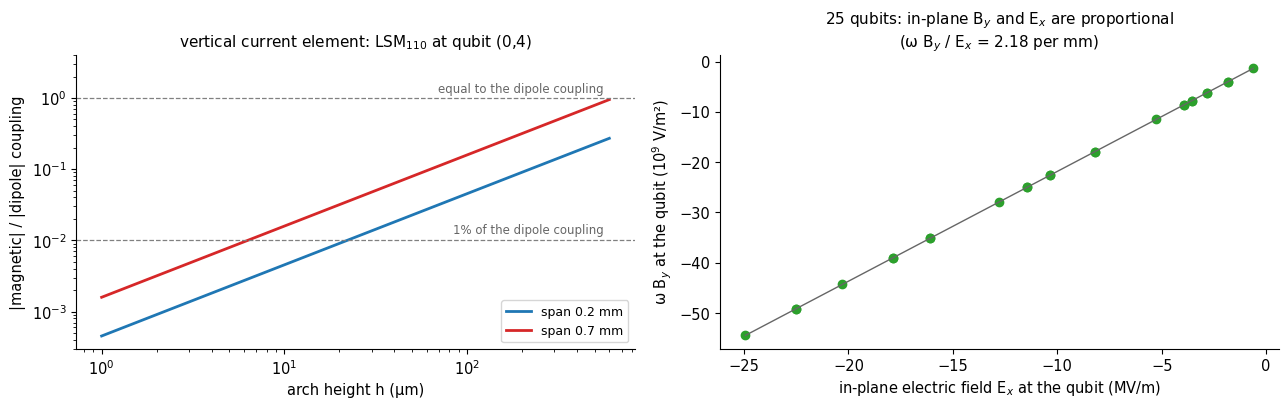

at qubit (0,4): a 0.2 mm-span arch reaches 1% of the dipole coupling at h = 23 µm; at the largest h shown, 0.27 of it
ω B_y / E_x over the 25 qubits: 2.183 per mm, worst deviation from proportionality 2.8e-16 of max |ωB_y| (the same pattern, so the ratio does not depend on the qubit)


In [28]:
a_ = an["110"]
Q_pad = np.abs(src[(0, 4)]["q"][src[(0, 4)]["q"] > 0].sum())
hs = np.logspace(-3, np.log10(0.6), 60)  # arch heights, mm
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ratios = {}
for span, col in ((0.2, "tab:blue"), (0.7, "tab:red")):
    r_h = []
    for h_ in hs:
        i_, j_ = 0, 4
        c_ = src[(i_, j_)]["c"]
        # B at the height of the centroid of the arch's area (about 0.4 h above the chip)
        _, B_arch = mp.lsm_fields(a_, c_[0], c_[1], t + 0.4 * h_)
        U_M = Q_pad * (2 / 3 * span * 1e-3 * h_ * 1e-3) * (2 * np.pi * a_.f) * abs(B_arch[1])
        r_h.append(U_M / abs(src[(i_, j_)]["mom"]["p"][0] * mp.phi_derivs(a_, c_[0], c_[1], 1)[0]))
    ratios[span] = np.array(r_h)
    ax[0].loglog(hs * 1e3, r_h, color=col, lw=2, label=f"span {span} mm")
ax[0].axhline(0.01, color="0.5", ls="--", lw=0.9)
ax[0].text(560, 0.0112, "1% of the dipole coupling", color="0.4", fontsize=8.5, ha="right", va="bottom")
ax[0].axhline(1.0, color="0.5", ls="--", lw=0.9)
ax[0].text(560, 1.1, "equal to the dipole coupling", color="0.4", fontsize=8.5, ha="right", va="bottom")
ax[0].set(xlabel="arch height h (µm)", ylabel="|magnetic| / |dipole| coupling", title="vertical current element: LSM$_{110}$ at qubit (0,4)")
ax[0].legend(fontsize=9, loc="lower right")
ax[0].set_ylim(3e-4, 4)
# the ratio is the same at every qubit: B_y and E_x share the pattern cos(pi x/L) sin(pi y/L)
Ex_all, wBy_all = [], []
for ij in QUBITS:
    c_ = src[ij]["c"]
    _, Bq = mp.lsm_fields(a_, c_[0], c_[1], t + 0.04)
    Ex_all.append(-mp.phi_derivs(a_, c_[0], c_[1], 1)[0])
    wBy_all.append((2 * np.pi * a_.f) * Bq[1])
Ex_all, wBy_all = np.array(Ex_all), np.array(wBy_all)
slope = np.sum(Ex_all * wBy_all) / np.sum(Ex_all**2)
ax[1].plot(Ex_all / 1e6, wBy_all / 1e9, "o", color="tab:green")
xl = np.array([Ex_all.min(), Ex_all.max()]) / 1e6
ax[1].plot(xl, slope * xl * 1e6 / 1e9, color="0.4", lw=1)
ax[1].set(xlabel="in-plane electric field E$_x$ at the qubit (MV/m)", ylabel="ω B$_y$ at the qubit (10$^9$ V/m²)",
          title=f"25 qubits: in-plane B$_y$ and E$_x$ are proportional\n(ω B$_y$ / E$_x$ = {abs(slope) * 1e-3:.2f} per mm)")
plt.tight_layout()
show(fig, "fig12_vertical_element")
h1 = hs[np.argmax(ratios[0.2] > 0.01)] * 1e3
print(f"at qubit (0,4): a 0.2 mm-span arch reaches 1% of the dipole coupling at h = {h1:.0f} µm and the dipole coupling itself at h = {hs[np.argmax(ratios[0.2] > 1)] * 1e3 if (ratios[0.2] > 1).any() else float('nan'):.0f} µm"
      if (ratios[0.2] > 1).any() else f"at qubit (0,4): a 0.2 mm-span arch reaches 1% of the dipole coupling at h = {h1:.0f} µm; at the largest h shown, {ratios[0.2][-1]:.2f} of it")
print(f"ω B_y / E_x over the 25 qubits: {abs(slope) * 1e-3:.3f} per mm, worst deviation from proportionality {np.abs(wBy_all - slope * Ex_all).max() / np.abs(wBy_all).max():.1e} of max |ωB_y|"
      f" (the same pattern, so the ratio does not depend on the qubit)")
claim("a vertical current element couples magnetically to the in-plane B of the mode", "arch of height h, span 0.2 mm, charge Q of the qubit (a model of the current path)",
      "U_M = Q·(2/3)s h·ωB_y against p·E_x", f"1% of the dipole at h = {h1:.0f} µm; ratio {ratios[0.2][-1]:.2f} at h = {hs[-1] * 1e3:.0f} µm",
      "CAVEAT", "idealized thin arch carrying the whole displacement charge; the order of magnitude, not a bond-wire simulation")

For an arch of a tenth of a millimeter or more, the magnetic coupling to the in-plane field is a percent of the dipole coupling or more, and it is not zero at any height: it grows linearly with $h$ and is the same fraction of $E_1$ at every qubit, because $B_y$ and $E_x$ of LSM$_{110}$ share the pattern $\cos(\pi x/L_x)\sin(\pi y/L_y)$. That is the sense in which magnetic coupling is "small" in this device: not because the in-plane magnetic field is weak, which it is not, but because the qubits are flat. Features of a device with vertical extent (wirebonds, airbridges of a few micrometers contribute proportionally less, a probe or a pin through the chip) do not have that protection.

<!-- TODO-ZKM: the arch is a deliberately simple model (the whole displacement charge on one arch of parabolic shape); confirm that this is the example the paper would want for 'magnetic coupling is not zero for vertical elements', and whether to quote typical airbridge and wirebond sizes. -->

### 8b. A mode with $B_z\neq0$

The other condition is the mode. Modes that are transverse-electric to $z$ (LSE) have $H_z\neq0$ and a rotational in-plane electric field. Where is the lowest one? Their frequency follows from continuity of $h(z)$ and $h'(z)$ at the silicon surface (`mp.lse_frequencies`), and the finite-element solver finds them: solve the paddle-free quarter at 0.3 mm elements near that frequency and sort the modes by the share of the normal magnetic field in their in-plane field. The mesh is coarse for 40 GHz (wavelength in the silicon about 2 mm), so frequencies are good to a few percent.

<!-- TODO-ZKM: the LSE search uses a 0.3 mm mesh with no paddles, coarse for 40 GHz; the lowest LSE candidate and its B_z fraction are indicative (compare the analytic estimates above), and the coupling of a qubit to a mode six times its own frequency is an illustration of the mechanism only. -->

In [29]:
if RUN_LSE_SEARCH:
    start = time.time()
    f_est = {ab: mp.lse_frequencies(*ab, 30.0, 30.0, 3.0, t, pm.DEVICE["eps_r"], 1)[0] for ab in ((0, 1), (1, 1), (2, 1))}
    print("analytic LSE_ab (TE_z) estimates, lowest of each (GHz): " + ", ".join(f"({a}{b}) {f / 1e9:.2f}" for (a, b), f in f_est.items()))
    mesh_lse = pm.mesh_package(package, region="quarter", pads=False, h_max=0.3, h_metal=0.3)
    fem_lse = pm.MaxwellFEM(mesh_lse, cuts=("pmc", "pmc"))
    lse_modes = fem_lse.eigenmodes(39.3e9, n=8)
    gl = np.linspace(0.3, 14.7, 41)
    Xl, Yl = np.meshgrid(gl, gl)
    pl = np.vstack([Xl.ravel(), Yl.ravel(), np.full(Xl.size, t + 1e-6)])
    frac = []
    for m_ in lse_modes:
        C_ = mp.curl_E(fem_lse, m_.u, pl)
        frac.append(np.sqrt(np.mean(C_[2] ** 2) / np.mean(C_[0] ** 2 + C_[1] ** 2)))
    print(f"{fem_lse.n_dofs:,} unknowns; the {len(lse_modes)} modes nearest 39 GHz, with rms B_z / rms B_t at the chip plane:")
    for m_, fr in zip(lse_modes, frac):
        print(f"   {m_.f / 1e9:7.3f} GHz   B_z/B_t = {fr:.3f}")
    # the noise floor of this mesh for B_z: the modes with the smallest ratio are TM (B_z = 0 exactly)
    floor = min(frac)
    k_lse = int(np.argmax(frac))
    mode_lse = lse_modes[k_lse]
    print(f"floor of B_z/B_t on this mesh (smallest ratio, TM modes): {floor:.3f}; lowest clear LSE candidate: {min(m_.f for m_, fr in zip(lse_modes, frac) if fr > 2 * floor) / 1e9:.2f} GHz;"
          f" largest ratio {frac[k_lse]:.2f} at {mode_lse.f / 1e9:.2f} GHz  ({time.time() - start:.0f} s)")
    TIMES["lse"] = time.time() - start
else:
    print("RUN_LSE_SEARCH = False: skipped")

analytic LSE_ab (TE_z) estimates, lowest of each (GHz): (01) 39.40, (11) 39.54, (21) 39.97


111,739 unknowns; the 8 modes nearest 39 GHz, with rms B_z / rms B_t at the chip plane:
    38.865 GHz   B_z/B_t = 0.279
    38.919 GHz   B_z/B_t = 0.257
    38.949 GHz   B_z/B_t = 0.102
    38.968 GHz   B_z/B_t = 0.236
    39.471 GHz   B_z/B_t = 0.110
    39.473 GHz   B_z/B_t = 0.113
    39.490 GHz   B_z/B_t = 0.113
    39.491 GHz   B_z/B_t = 0.113
floor of B_z/B_t on this mesh (smallest ratio, TM modes): 0.102; lowest clear LSE candidate: 38.86 GHz; largest ratio 0.28 at 38.86 GHz  (26 s)


Modes with a clear normal magnetic field exist near 40 GHz, six times the frequency of the modes the qubits are meant to couple to, and several modes of the loaded box lie between (LSM modes with higher $(a,b)$). The lowest of them has a normal field of a few tens of percent of its in-plane field, well above the floor of this mesh. That is the worked example for the magnetic dipole: the off-axis-junction qubit of Sec. 7 has $\tilde m_z\neq0$, and in such a mode $(\nabla\times\mathbf E)_z\neq0$. Its magnetic dipole coupling $M_1=\tilde m_z(\nabla\times\mathbf E)_z$ against its electric coupling $E_1=\mathbf p\cdot\mathbf E$, at every qubit of the quarter, from the same disc fits: (a wide disc, because the mode varies on the scale of the chip; the electric coupling is that of the symmetric qubit, whose dipole is the same). Both are the $g/2\pi$ the two would have if they were resonant at the mode's frequency; the printout compares $M_1$ with its own estimator floor, from the scatter over three fit radii. If it does not clear 3× that floor, the honest reading is that this one coarse mesh illustrates the mechanism and does not measure the number:

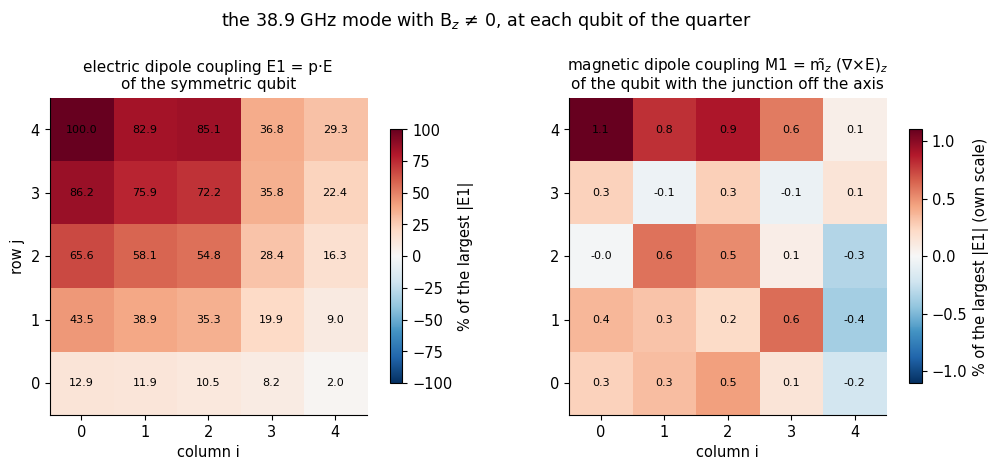

mode at 38.86 GHz: largest |M1| = 14.39 MHz against largest |E1| = 1303.45 MHz (ratio 0.01; g/2π if the two were resonant at that frequency);
fit floor of M1 (scatter over three fit radii, 1.2 / 1.6 / 2.0 mm, peak over qubits): 5.12 MHz -> M1 is NOT above 3× that floor (mesh floor not measured: one coarse mesh); the same qubit in the LSM110 mode: M1 = 0 (B_z = 0)


In [30]:
if RUN_LSE_SEARCH and RUN_SYMMETRY_BREAKING:
    w_l = 2 * np.pi * mode_lse.f
    sv_sym, sv_off = VAR["symmetric"], VAR["junction off the axis"]
    F_l = lambda p_: np.vstack([mode_lse.field(p_)[:2], mp.curl_E(fem_lse, mode_lse.u, p_)[2:3]])
    E1_l, M1_l = np.zeros((5, 5)), np.zeros((5, 5))
    for (i_, j_) in QUBITS:
        c_ = src[(i_, j_)]["c"]
        ft = mp.disc_fit(F_l, (c_[0], c_[1], t + 1e-6), R=1.6, N=3000)  # the mode varies on the scale of the chip: a wide disc
        E1_l[j_, i_] = mp.g_MHz(mode_lse.f, sv_sym["mom"]["p"] @ ft.value[:2])
        M1_l[j_, i_] = mp.g_MHz(mode_lse.f, sv_off["cur_dc"].m() * ft.value[2])
    # the estimator floor of M1: the same fit with other radii (one mesh only, so no mesh floor: unverified)
    M1_R = []
    for R_ in (1.2, 2.0):
        m_ = np.zeros((5, 5))
        for (i_, j_) in QUBITS:
            c_ = src[(i_, j_)]["c"]
            ft = mp.disc_fit(F_l, (c_[0], c_[1], t + 1e-6), R=R_, N=3000)
            m_[j_, i_] = mp.g_MHz(mode_lse.f, sv_off["cur_dc"].m() * ft.value[2])
        M1_R.append(m_)
    M1_fit_floor = np.nanmax(np.nanstd(np.array([M1_l] + M1_R), axis=0, ddof=1))
    e_max = np.abs(E1_l).max()
    fig, ax = plt.subplots(1, 2, figsize=(10.8, 4.4))
    for a_k, F_, ttl in ((ax[0], E1_l, "electric dipole coupling E1 = p·E\nof the symmetric qubit"),
                         (ax[1], M1_l, "magnetic dipole coupling M1 = m̃$_z$ (∇×E)$_z$\nof the qubit with the junction off the axis")):
        lim_k = 100 if a_k is ax[0] else np.abs(F_).max() / e_max * 100
        im = a_k.imshow(F_ / e_max * 100, origin="lower", cmap="RdBu_r", vmin=-lim_k, vmax=lim_k)
        for jj in range(5):
            for ii in range(5):
                a_k.text(ii, jj, f"{F_[jj, ii] / e_max * 100:.1f}", ha="center", va="center", fontsize=8)
        a_k.set(title=ttl, xticks=range(5), yticks=range(5), xlabel="column i", ylabel="row j" if a_k is ax[0] else None)
        plt.colorbar(im, ax=a_k, shrink=0.8, label="% of the largest |E1|" + ("" if a_k is ax[0] else " (own scale)"))
    fig.suptitle(f"the {mode_lse.f / 1e9:.1f} GHz mode with B$_z$ ≠ 0, at each qubit of the quarter", y=1.02)
    plt.tight_layout()
    show(fig, "fig13_lse_mode_coupling")
    ratio_ml = np.abs(M1_l).max() / np.abs(E1_l).max()
    print(f"mode at {mode_lse.f / 1e9:.2f} GHz: largest |M1| = {np.abs(M1_l).max():.2f} MHz against largest |E1| = {np.abs(E1_l).max():.2f} MHz (ratio {ratio_ml:.2f}; "
          f"g/2π if the two were resonant at that frequency);")
    print(f"fit floor of M1 (scatter over three fit radii, 1.2 / 1.6 / 2.0 mm, peak over qubits): {M1_fit_floor:.2f} MHz -> M1 is "
          f"{'above 3× that floor' if np.abs(M1_l).max() > 3 * M1_fit_floor else 'NOT above 3× that floor'} (mesh floor not measured: one coarse mesh); the same qubit in the LSM110 mode: M1 = 0 (B_z = 0)")
    clears = np.abs(M1_l).max() > 3 * M1_fit_floor
    claim("a package mode with B_z ≠ 0 exists, and a qubit with m_z ≠ 0 couples to it magnetically",
          "LSE (TE_z) mode near 40 GHz; qubit with its junction 0.3 mm off the paddle axis",
          "paddle-free quarter, 0.3 mm elements, disc fits; M1 = m̃_z (curl E)_z",
          f"lowest clear mode {min(m_.f for m_, fr in zip(lse_modes, frac) if fr > 2 * floor) / 1e9:.1f} GHz; largest |M1|/|E1| = {ratio_ml:.2f}; M1 {np.abs(M1_l).max():.1f} MHz vs fit floor {M1_fit_floor:.1f} MHz ({np.abs(M1_l).max() / M1_fit_floor:.1f}×)",
          "CAVEAT", ("M1 clears 3× its fit floor; " if clears else "M1 does NOT clear 3× its fit floor on this mesh (a one-mesh illustration, mesh floor unmeasured); ")
          + "coarse mesh (frequencies to a few %), the factor-2 current model, and a qubit placed in a mode 6× its own frequency: the mechanism, not a prediction")
else:
    print("skipped (needs RUN_LSE_SEARCH and RUN_SYMMETRY_BREAKING)")

## 9. Refining the mesh: which terms converge, which zeros stay zero

Everything so far is on one mesh, and a number from one mesh is a statement about that mesh. The test that separates a *physical* zero from a *numerical* one is refinement. A term that is nonzero in the continuum converges to a finite value. A term that vanishes by symmetry is zero only in the continuum: on a discrete mesh, which is not symmetric, it is a small number that should shrink as the mesh refines (the asymmetry of the mesh shrinks), or stay at a floor set by something other than the mesh. Each level below meshes the quarter again with a different element size at the paddle edges, `h_metal`, solves the electrostatics, both bare modes and both dressed modes, and takes every number of Secs. 1–6 from them. (A separately generated mesh never reuses the charges of another: they belong to the nodes of the mesh they were computed on.)

In [31]:
def run_level(hm):
    """Mesh the quarter with paddle-edge element size hm and recompute every quantity of Secs. 1-6."""
    q_ = pm.mesh_package(package, region="quarter", h_metal=hm, h_max=BUD["h_max"])
    es_ = pm.Electrostatics(q_, order=BUD["order"])
    src_ = mp.qubit_sources(es_, q_, package, QUBITS, order=BUD["order"])
    del es_
    b_, d_ = {}, {}
    for tag, cuts, f_guess in (("110", ("pmc", "pmc"), 6.5e9), ("210", ("pec", "pmc"), 10.2e9)):
        b_[tag] = mp.bare_data(q_, cuts, f_guess, an[tag], src_, t + 1e-6, N=BUD["N_fit"], maps=True)
        d_[tag] = mp.dressed_data(q_, cuts, f_guess, an[tag], src_, t + 1e-6, N=BUD["N_fit"], maps=True)
    out = dict(h=hm, summ=mp.summarize_level(src_, b_, d_), dofs=b_["110"]["n_dofs"], n_tets=q_.t.shape[1],
               terms={tag: mp.terms_per_qubit(src_, b_[tag], d_[tag]) for tag in b_})
    return out


if RUN_CONVERGENCE:
    sweep_start = time.time()
    LEVELS = {BUD["h_metal"]: dict(h=BUD["h_metal"], summ=mp.summarize_level(src, bare, dress), dofs=bare["110"]["n_dofs"],
                                   n_tets=quarter.t.shape[1], terms={tag: terms[tag] for tag in bare})}
    for hm in BUD["sweep"]:
        start = time.time()
        LEVELS[hm] = run_level(hm)
        print(f"h_metal = {hm:.2f} mm: {LEVELS[hm]['n_tets']:>7,} tetrahedra, {LEVELS[hm]['dofs']:>7,} unknowns   ({time.time() - start:.0f} s)")
    TIMES["convergence sweep"] = time.time() - sweep_start
    hs_ = sorted(LEVELS, reverse=True)
    print(f"levels (h_metal, mm): {hs_}")

h_metal = 0.20 mm:  71,940 tetrahedra,  78,874 unknowns   (54 s)


h_metal = 0.14 mm: 119,209 tetrahedra, 132,416 unknowns   (96 s)


h_metal = 0.10 mm: 183,286 tetrahedra, 205,309 unknowns   (127 s)
levels (h_metal, mm): [0.2, 0.14, 0.1, 0.07]


The mesher is not deterministic: gmsh's tetrahedral algorithm returns a different mesh each time it is run, even with identical input. That spoils bit-reproducibility, but it hands us a free ensemble. A few meshes of *nearly* the same element size (changed by a few percent, so that they are certainly different) are independent samples of the discretization error, and the scatter of a term over them is a floor that no refinement study can see. Run at the coarse end for cost, where the scatter is largest and so an upper bound for the finer meshes:

In [32]:
ENS = []
if RUN_CONVERGENCE and BUD["n_ens"] > 1:
    ens_start = time.time()
    for k_ in range(BUD["n_ens"]):
        hm = 0.20 * (1 + 0.04 * k_)
        ENS.append(run_level(hm))
        print(f"ensemble member {k_ + 1}: h_metal = {hm:.3f} mm, {ENS[-1]['n_tets']:,} tetrahedra")
    TIMES["mesher ensemble"] = time.time() - ens_start
    ens_arr = lambda key: np.array([e["summ"][key] for e in ENS])
    print(f"relative scatter of the summary numbers over the {len(ENS)} meshes: "
          + ", ".join(f"{k} {np.std(ens_arr(k), ddof=1) / abs(np.mean(ens_arr(k))):.1e}" for k in ("px", "A_110", "A_210")))

ensemble member 1: h_metal = 0.200 mm, 71,966 tetrahedra


ensemble member 2: h_metal = 0.208 mm, 68,646 tetrahedra


ensemble member 3: h_metal = 0.216 mm, 65,547 tetrahedra


ensemble member 4: h_metal = 0.224 mm, 62,981 tetrahedra
relative scatter of the summary numbers over the 4 meshes: px 1.8e-03, A_110 2.0e-03, A_210 2.3e-03


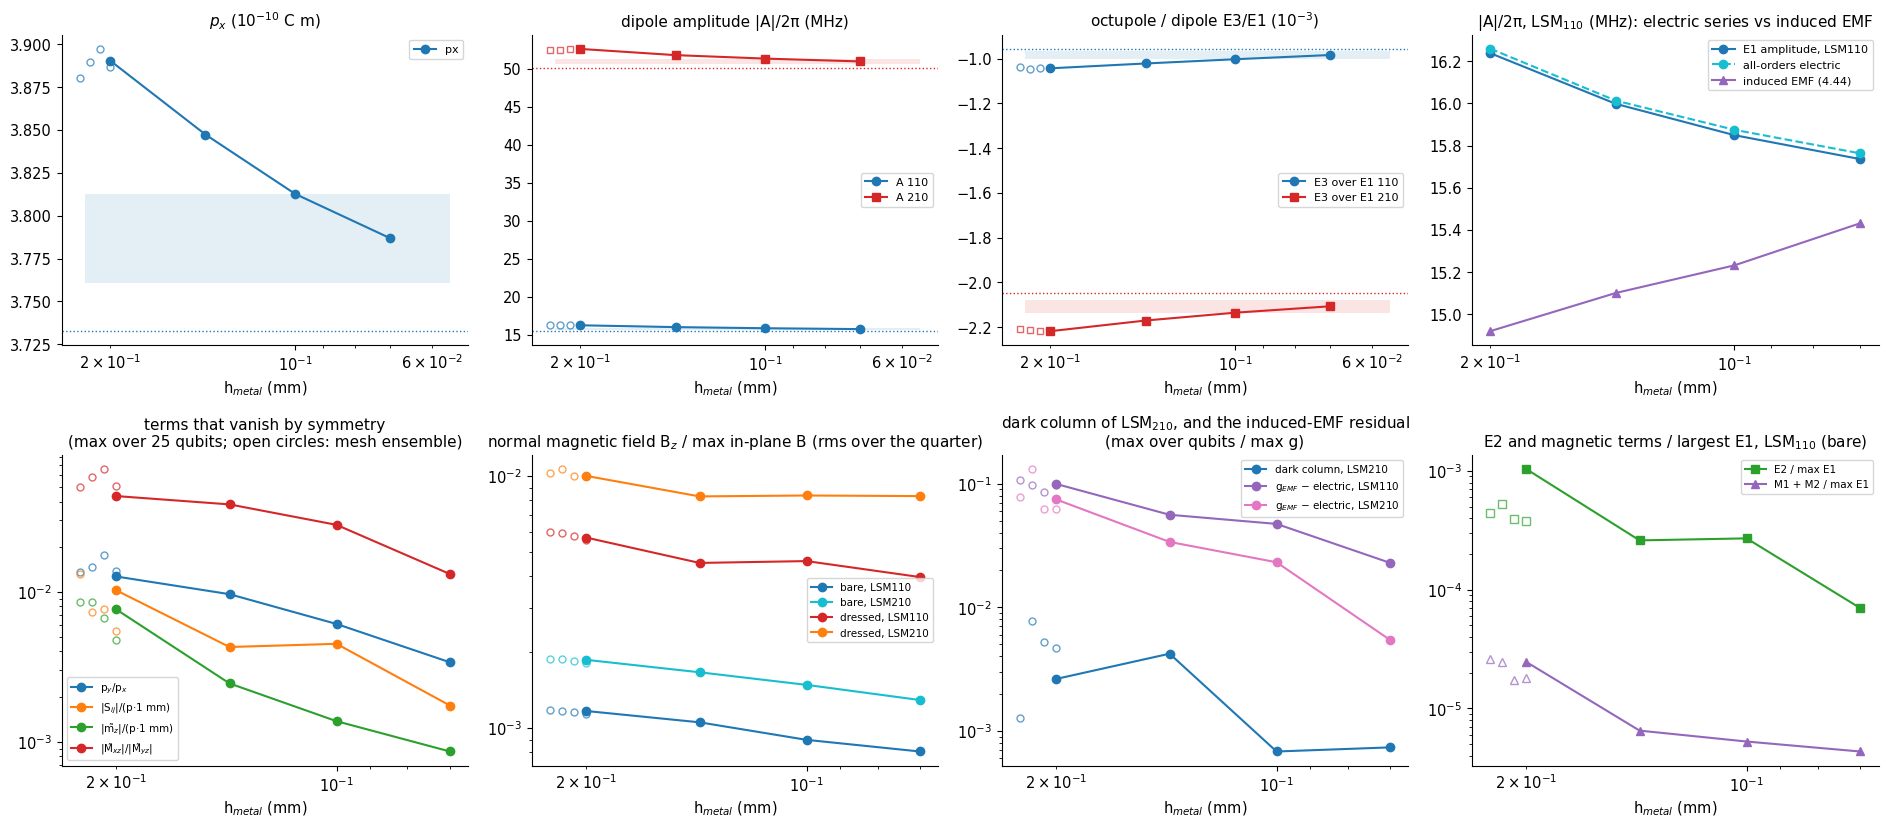

                  quantity    coarsest     h=0.14      h=0.1     h=0.07  fitted rate s   (|v| ~ h^s)
                py_over_px   1.27e-02   9.65e-03   6.10e-03   3.39e-03           1.27
                S_over_pmm   1.02e-02   4.28e-03   4.50e-03   1.74e-03           1.52
               mz_over_pmm   7.64e-03   2.45e-03   1.37e-03   8.60e-04           2.05
              Mxz_over_Myz   4.36e-02   3.83e-02   2.80e-02   1.31e-02           1.12
                Bz_rms_110   1.17e-03   1.05e-03   8.98e-04   8.07e-04           0.36
                Bz_rms_210   1.87e-03   1.66e-03   1.48e-03   1.29e-03           0.35
        Bz_dressed_rms_110   5.70e-03   4.52e-03   4.60e-03   3.97e-03           0.31
                  dark_210   2.63e-03   4.21e-03   6.81e-04   7.35e-04           1.61
         emf_resid_max_110   9.96e-02   5.60e-02   4.73e-02   2.29e-02           1.32
         emf_resid_max_210   7.46e-02   3.38e-02   2.31e-02   5.44e-03           2.37

              nonzero term     finest 

In [33]:
def fit_power(h, v, kind):
    """kind 'zero': |v| ~ c h^s (returns s). kind 'limit': v = v_inf + c h^s on the best of s = 1, 2 (returns v_inf, s)."""
    h, v = np.asarray(h, float), np.asarray(v, float)
    if kind == "zero":
        s, _ = np.polyfit(np.log(h), np.log(np.abs(v)), 1)
        return s
    best = None
    for s in (1.0, 2.0):
        A = np.vstack([np.ones_like(h), h**s]).T
        coef, res, *_ = np.linalg.lstsq(A, v, rcond=None)
        sse = np.sum((A @ coef - v) ** 2)
        if best is None or sse < best[0]:
            best = (sse, coef[0], s)
    return best[1], best[2]


if RUN_CONVERGENCE:
    hl = np.array(sorted(LEVELS, reverse=True))  # coarse to fine
    S = {k: np.array([LEVELS[h]["summ"][k] for h in hl]) for k in LEVELS[hl[0]]["summ"] if k not in ("times", "h")}
    Sens = {k: np.array([e["summ"][k] for e in ENS]) for k in S} if ENS else {}
    h_ens = np.array([e["h"] for e in ENS])
    fig, ax = plt.subplots(2, 4, figsize=(19, 8.4))
    ax = ax.ravel()
    spec_lim = [(0, "$p_x$ (10$^{-10}$ C m)", [("px", 1e10, "tab:blue", "o")]),
                (1, "dipole amplitude |A|/2π (MHz)", [("A_110", -1, "tab:blue", "o"), ("A_210", -1, "tab:red", "s")]),
                (2, "octupole / dipole E3/E1 (10$^{-3}$)", [("E3_over_E1_110", 1e3, "tab:blue", "o"), ("E3_over_E1_210", 1e3, "tab:red", "s")])]
    LIMITS = {}
    for k_, ttl, lines in spec_lim:
        for key, scale, col, mk_ in lines:
            v = S[key] * scale
            ax[k_].plot(hl, v, mk_ + "-", color=col, label=key.replace("_", " "))
            if ENS:
                ax[k_].plot(h_ens, Sens[key] * scale, mk_, color=col, mfc="none", alpha=0.7, ms=5)
            v_inf, s_ = fit_power(hl, v, "limit")
            band = max(abs(v[-1] - v[-2]), np.std(Sens[key] * scale, ddof=1) if len(ENS) > 1 else 0.0)  # floor band at the finest level
            LIMITS[key] = (v_inf, s_, abs(v[-1] / v[-2] - 1), band / abs(v[-1]))
            ax[k_].axhline(v_inf, color=col, ls=":", lw=1.0)
            ax[k_].fill_between([hl.min() * 0.8, hl.max() * 1.1], v[-1] - band, v[-1] + band, color=col, alpha=0.12, lw=0)  # floor band about the finest value
        ax[k_].set(title=ttl, xlabel="h$_{metal}$ (mm)", xscale="log")
        ax[k_].invert_xaxis()
        ax[k_].legend(fontsize=8)
    ax[3].plot(hl, S["A_110"] * -1, "o-", color="tab:blue", label="E1 amplitude, LSM110")
    ax[3].plot(hl, S["A_exact_110"] * -1, "o--", color="tab:cyan", label="all-orders electric")
    emf_A = np.array([-mp.pattern_amplitude(LEVELS[h]["terms"]["110"]["emf"], an["110"]) for h in hl])
    ax[3].plot(hl, emf_A, "^-", color="tab:purple", label="induced EMF (4.44)")
    ax[3].set(title="|A|/2π, LSM$_{110}$ (MHz): electric series vs induced EMF", xlabel="h$_{metal}$ (mm)", xscale="log")
    ax[3].invert_xaxis()
    ax[3].legend(fontsize=8)
    RATES = {}
    spec0 = [(4, "terms that vanish by symmetry\n(max over 25 qubits; open circles: mesh ensemble)", [("py_over_px", "p$_y$/p$_x$", "tab:blue"), ("S_over_pmm", "|S$_{ij}$|/(p·1 mm)", "tab:orange"),
                                                                                                      ("mz_over_pmm", "|m̃$_z$|/(p·1 mm)", "tab:green"), ("Mxz_over_Myz", "|M̃$_{xz}$|/|M̃$_{yz}$|", "tab:red")]),
             (5, "normal magnetic field B$_z$ / max in-plane B (rms over the quarter)", [("Bz_rms_110", "bare, LSM110", "tab:blue"), ("Bz_rms_210", "bare, LSM210", "tab:cyan"),
                                                                                         ("Bz_dressed_rms_110", "dressed, LSM110", "tab:red"), ("Bz_dressed_rms_210", "dressed, LSM210", "tab:orange")]),
             (6, "dark column of LSM$_{210}$, and the induced-EMF residual\n(max over qubits / max g)", [("dark_210", "dark column, LSM210", "tab:blue"), ("emf_resid_max_110", "g$_{EMF}$ − electric, LSM110", "tab:purple"),
                                                                                                       ("emf_resid_max_210", "g$_{EMF}$ − electric, LSM210", "tab:pink")])]
    for k_, ttl, lines in spec0:
        for key, lab, col in lines:
            ax[k_].loglog(hl, np.abs(S[key]), "o-", color=col, label=lab)
            if ENS:
                ax[k_].loglog(h_ens, np.abs(Sens[key]), "o", color=col, mfc="none", alpha=0.7, ms=5)
            RATES[key] = fit_power(hl, S[key], "zero")
        ax[k_].set(title=ttl, xlabel="h$_{metal}$ (mm)")
        ax[k_].invert_xaxis()
        ax[k_].legend(fontsize=7.5)
    e1ref = np.array([np.nanmax(np.abs(LEVELS[h]["terms"]["110"]["E1"])) for h in hl])
    ax[7].loglog(hl, S["E2_floor_kHz_110"] * 1e-3 / e1ref, "s-", color="tab:green", label="E2 / max E1")
    ax[7].loglog(hl, S["M_floor_kHz_110"] * 1e-3 / e1ref, "^-", color="tab:purple", label="M1 + M2 / max E1")
    if ENS:
        e1ens = np.array([np.nanmax(np.abs(e["terms"]["110"]["E1"])) for e in ENS])
        ax[7].loglog(h_ens, Sens["E2_floor_kHz_110"] * 1e-3 / e1ens, "s", color="tab:green", mfc="none", alpha=0.7)
        ax[7].loglog(h_ens, Sens["M_floor_kHz_110"] * 1e-3 / e1ens, "^", color="tab:purple", mfc="none", alpha=0.7)
    ax[7].set(title="E2 and magnetic terms / largest E1, LSM$_{110}$ (bare)", xlabel="h$_{metal}$ (mm)")
    ax[7].invert_xaxis()
    ax[7].legend(fontsize=7.5)
    plt.tight_layout()
    show(fig, "fig14_convergence")
    print(f"{'quantity':>26} {'coarsest':>11} " + " ".join(f"{'h=' + str(h):>10}" for h in hl[1:]) + f" {'fitted rate s':>14}   (|v| ~ h^s)")
    for key in ("py_over_px", "S_over_pmm", "mz_over_pmm", "Mxz_over_Myz", "Bz_rms_110", "Bz_rms_210", "Bz_dressed_rms_110", "dark_210", "emf_resid_max_110", "emf_resid_max_210"):
        print(f"{key:>26} " + " ".join(f"{v:10.2e}" for v in S[key]) + f" {RATES.get(key, np.nan):14.2f}")
    print(f"\n{'nonzero term':>26} {'finest':>10} {'extrapolated':>13} {'finest vs previous':>19} {'floor band / value':>19}   (v = v_inf + c h^s)")
    for key, (v_inf, s_, d_prev, band_rel) in LIMITS.items():
        print(f"{key:>26} {S[key][-1]:10.4g} {v_inf:13.4g} {d_prev:19.2%} {band_rel:19.2%}   s = {s_:.0f}")

Two behaviors, as expected, and one that has to be said plainly. The nonzero terms converge: $p_x$, the dipole amplitudes $|A|$ and the octupole ratio settle to finite limits, with the change between the last two levels in the "finest vs previous" column. The terms that vanish by symmetry decrease with refinement or reach a floor: the dipole's $p_y$, the quadrupole $S_{ij}$, the magnetic dipole $\tilde m_z$ and the partner $\tilde M_{xz}$ of the surviving magnetic quadrupole fall with fitted rates of order one in $h$, and the bare $B_z$ floor falls slowly. The open circles, the mesh ensemble at the coarse end, show the scatter that independent meshes of the same nominal size give: of the same order as the change from one level to the next, which is why the ensemble is a floor in its own right.

**What does not simply go away.** The *dressed* $B_z$ does not shrink with refinement, because it is not a discretization error: it is the physical normal field of the induced paddle currents, and its rms relative to the in-plane field plateaus while the bare one falls. The residue of the dark column of LSM$_{210}$ and the induced-EMF residual are limited by the field side of the calculation (the finite-element $E_x$ at the junction), and are discussed in the tables of Sec. 10 with the verdicts that the numbers support.

The right-hand panel of the first row shows the induced EMF approaching the electric series from below as the mesh is refined, as 4.44 found for the EMF alone, while the series is already converged at the coarser levels: the residual of Sec. 6, the bound on everything the series neglects, is dominated by the discretization error of the EMF side and shrinks with it.

## 10. Error bars: which terms are resolved

Sec. 9 gave two of the four floors of the introduction: the change between mesh levels and the scatter over an ensemble of meshes. The third is the estimator. The finite-element field enters every term through a polynomial fit over a disc, and the fit has arbitrary choices: how large the disc, how many points, quadratic or cubic, centered where. Recompute every term of every qubit with ten variants of these choices (and, for the dressed mode, with five annuli) on the finest mesh, and the scatter is the noise of the estimator:

In [34]:
start = time.time()
VAR_TERMS = {tag: mp.fit_variants(bare[tag], dress[tag], src, t + 1e-6) for tag in bare}
TIMES["estimator variants"] = time.time() - start
for tag in bare:
    v_ = VAR_TERMS[tag]
    print(f"LSM{tag}: scatter of the largest value over the {len(mp.BARE_VARIANTS)} fit variants (peak over qubits of the std, kHz): "
          + ", ".join(f"{k} {np.nanmax(np.nanstd(v_[k], axis=0, ddof=1)) * 1e3:.3g}" for k in ("E1", "E2", "E3fe", "M", "Md")))

LSM110: scatter of the largest value over the 10 fit variants (peak over qubits of the std, kHz): E1 38.6, E2 0.0271, E3fe 31.1, M 0.0353, Md 0.204
LSM210: scatter of the largest value over the 10 fit variants (peak over qubits of the std, kHz): E1 117, E2 0.0478, E3fe 103, M 0.251, Md 1.62


The fourth floor, the null calibration, is already in hand: $p_y$, $S_{ij}$, $\tilde m_z$ and the dark column are zero by symmetry, and the table of Sec. 9 shows what the estimators return for them. They calibrate the nonzero terms that depend on the same quantities: the all-orders coupling and the dipole are limited by how well the dark column vanishes, and the octupole by how well the surviving octupole moments are separated from those that must vanish.

Now the budget. For each mode and each term: the peak value over the 25 qubits in kilohertz, the four floors, their quadrature sum, and the verdict of the significance rule. Terms that are zero by symmetry are upper limits by construction, since their value is their own floor. If one of them came out *resolved* against the other floors alone, that would be a real finding, and the cell flags it.

In [35]:
O_null_rel = (Odd.max() / (px.mean() * 1e-6)) / abs(Oxxx.mean())  # relative size of the octupole moments that must vanish
g_dark_fe = np.array([terms["210"]["exact_fe"][j, 2] for j in range(5)])
dark_rel = np.abs(g_dark_fe).max() / np.nanmax(np.abs(terms["210"]["exact_a"]))
if RUN_CONVERGENCE:
    hs_sorted = sorted(LEVELS, reverse=True)  # coarse to fine; the last is this notebook's mesh
    pass
    T_prev = {tag: LEVELS[hs_sorted[-2]]["terms"][tag] for tag in bare}
else:
    T_prev = {tag: None for tag in bare}
BUDGET_ROWS = {}
for tag in bare:
    lev_ = [(h_, LEVELS[h_]["terms"][tag]) for h_ in hs_sorted] if RUN_CONVERGENCE else None
    BUDGET_ROWS[tag] = mp.error_budget(tag, terms[tag], T_prev[tag], [e["terms"][tag] for e in ENS], VAR_TERMS[tag], O_null_rel, dark_rel, levels=lev_)


def fmt_kHz(v):
    return f"{v:.3g}"


lines = ["| mode | term | value (kHz) | % of E1 | floor (kHz): mesh / ensemble / fit / null | total | verdict | > 1 kHz | > 4.8% of E1 |", "|---|---|---|---|---|---|---|---|---|"]
for tag in bare:
    for r_ in BUDGET_ROWS[tag]:
        p_ = r_["parts"]
        lim_ = max(r_["value"], r_["floor"]) * (2 if r_["model_band"] else 1)
        if r_["status"] == "resolved":
            verdict = f"**resolved**: {fmt_kHz(r_['value'])} ± {fmt_kHz(r_['floor'])}" + (" (model ×/÷ 2)" if r_["model_band"] else "")
        elif r_["status"] == "unverified":
            verdict = f"unverified (no second mesh level): {fmt_kHz(r_['value'])} ± {fmt_kHz(r_['floor'])}"
        else:
            verdict = f"upper limit **< {fmt_kHz(lim_)}**" + (" (incl. the ×2 model band)" if r_["model_band"] else "")
        lines.append(f"| {tag} | {r_['term']} | {fmt_kHz(r_['value'])} | {r_['rel_E1']:.1e} | {fmt_kHz(p_['mesh'])} / {fmt_kHz(p_['ensemble'])} / {fmt_kHz(p_['fit'])} / {fmt_kHz(p_['null'])}"
                     f" | {fmt_kHz(r_['floor'])} (largest: {r_['biggest']}) | {verdict} | {'yes' if r_['above_1kHz'] else 'no'} | {'yes' if r_['above_paper'] else 'no'} |")
display(Markdown("\n".join(lines)))
flags = [(tag, r_["term"]) for tag in bare for r_ in BUDGET_ROWS[tag] if r_["flag_real_null"]]
syst = [(tag, r_["term"]) for tag in bare for r_ in BUDGET_ROWS[tag] if r_["systematic_null"]]
if flags:
    display(Markdown("**⚠ REPRODUCIBLE NULL: " + "; ".join(f"LSM{t_}: {n_}" for t_, n_ in flags) + " is zero by symmetry but has the same sign on independent meshes, with a mean above 4 standard errors at some qubit, and does not shrink with refinement. This would be a finding, not noise.**"))
if syst:
    print("reproducible but falling with refinement (a systematic bias of the discretization that goes away, not a finding): " + "; ".join(f"LSM{t_}: {n_}" for t_, n_ in syst))
if not flags and not syst:
    print("no term that is zero by symmetry is reproducible over the mesh ensemble: each is an upper limit at its floor."
          if ENS else "no mesh ensemble was run: reproducibility of the nulls not tested.")
print(f"null calibrations used: dark-column residue {dark_rel:.1e} of the largest coupling; surviving-octupole null {O_null_rel:.1e} of O_xxx")

| mode | term | value (kHz) | % of E1 | floor (kHz): mesh / ensemble / fit / null | total | verdict | > 1 kHz | > 4.8% of E1 |
|---|---|---|---|---|---|---|---|---|
| 110 | E1 dipole | 1.54e+04 | 1.0e+00 | 152 / 223 / 38.6 / 11.3 | 273 (largest: ensemble) | **resolved**: 1.54e+04 ± 273 | yes | yes |
| 110 | all electric orders | 1.54e+04 | 1.0e+00 | 128 / 188 / 0 / 11.3 | 228 (largest: ensemble) | **resolved**: 1.54e+04 ± 228 | yes | yes |
| 110 | E3 octupole (analytic field) | 15.1 | 9.8e-04 | 0.413 / 0.251 / 0 / 0.0624 | 0.487 (largest: mesh) | **resolved**: 15.1 ± 0.487 | yes | no |
| 110 | E3 octupole (FE field) | 28 | 1.8e-03 | 30.2 / 50.8 / 31.1 / 0 | 66.8 (largest: ensemble) | upper limit **< 66.8** | yes | no |
| 110 | E2 quadrupole | 1.08 | 7.0e-05 | 4.14 / 5.35 / 0.0271 / 1.08 | 6.85 (largest: ensemble) | upper limit **< 6.85** | yes | no |
| 110 | M1 + M2, bare mode | 0.0667 | 4.3e-06 | 0.0728 / 0.179 / 0.0353 / 0.0667 | 0.208 (largest: ensemble) | upper limit **< 0.415** (incl. the ×2 model band) | no | no |
| 110 | M1 + M2, dressed mode | 0.265 | 1.7e-05 | 0.0576 / 0.161 / 0.204 / 0 | 0.266 (largest: fit) | upper limit **< 0.533** (incl. the ×2 model band) | no | no |
| 110 | g_EMF - all electric orders | 351 | 2.3e-02 | 443 / 397 / 0 / 0 | 595 (largest: mesh) | upper limit **< 595** | yes | no |
| 210 | E1 dipole | 4.79e+04 | 1.0e+00 | 572 / 531 / 117 / 35.2 | 790 (largest: mesh) | **resolved**: 4.79e+04 ± 790 | yes | yes |
| 210 | all electric orders | 4.8e+04 | 1.0e+00 | 500 / 608 / 0 / 35.3 | 788 (largest: ensemble) | **resolved**: 4.8e+04 ± 788 | yes | yes |
| 210 | E3 octupole (analytic field) | 101 | 2.1e-03 | 2.6 / 1.82 / 0 / 0.417 | 3.2 (largest: mesh) | **resolved**: 101 ± 3.2 | yes | no |
| 210 | E3 octupole (FE field) | 33.1 | 6.9e-04 | 92.4 / 157 / 103 / 0 | 209 (largest: ensemble) | upper limit **< 209** | yes | no |
| 210 | E2 quadrupole | 3.61 | 7.5e-05 | 11.2 / 34 / 0.0478 / 3.61 | 36 (largest: ensemble) | upper limit **< 36** | yes | no |
| 210 | M1 + M2, bare mode | 0.536 | 1.1e-05 | 0.334 / 1.15 / 0.251 / 0.536 | 1.34 (largest: ensemble) | upper limit **< 2.67** (incl. the ×2 model band) | no | no |
| 210 | M1 + M2, dressed mode | 2.19 | 4.6e-05 | 0.553 / 1.31 / 1.62 / 0 | 2.15 (largest: fit) | upper limit **< 4.39** (incl. the ×2 model band) | yes | no |
| 210 | g_EMF - all electric orders | 260 | 5.4e-03 | 1.07e+03 / 1.66e+03 / 0 / 0 | 1.97e+03 (largest: ensemble) | upper limit **< 1.97e+03** | yes | no |
| 210 | dark column i = 2 | 35.1 | 7.3e-04 | 41.7 / 205 / 0 / 35.1 | 213 (largest: ensemble) | upper limit **< 213** | yes | no |

reproducible but falling with refinement (a systematic bias of the discretization that goes away, not a finding): LSM110: E2 quadrupole; LSM110: M1 + M2, bare mode; LSM210: M1 + M2, bare mode
null calibrations used: dark-column residue 7.3e-04 of the largest coupling; surviving-octupole null 4.1e-03 of O_xxx


How to read the table. A term of the **resolved** kind is a number with an error bar: the dipole, the all-orders electric coupling and the analytic octupole. The analytic octupole is the exact function of the mesh's charges and the analytic mode, and its floor is only how well the charges of the mesh determine the octupole moments; the *finite-element* estimate of the same term needs second derivatives of a finite-element field, and, as the row shows, it is not an independent measurement at the finite-element noise level: it is listed because the question "can the finite-element solution see the octupole by itself?" has an answer, and the answer is in the verdict column. Terms that are zero by symmetry are upper limits, and the limit is the number to quote. A zero-by-symmetry term can also be *reproducible* over the mesh ensemble, the same sign on every mesh, and still not be a finding: if it shrinks as the mesh is refined it is a systematic bias of the finite-element curl, as the cell above reports for the bare magnetic terms when that happens (the rms $B_z$ of Sec. 9 falls with $h$ the same way). Only a null that is reproducible and does not shrink would be flagged as a result. The "> 1 kHz" and "> 4.8% of $E_1$" columns separate numerical from physical significance: the octupole is resolved and above the frequency resolution of a lab measurement, and far below the spread between the paper's methods.

## 11. The hierarchy, with error bars

The terms of Sec. 5 again, now with their floors. Left to right in each panel: the value (peak over the 25 qubits, kilohertz) of each term, a filled bar with an error bar where the term is resolved, a hollow bar and a downward arrow at the floor where it is not. Reference lines: 1 kHz (practical frequency resolution), 1% and 4.8% of the dipole coupling (the paper's spread between its four methods).

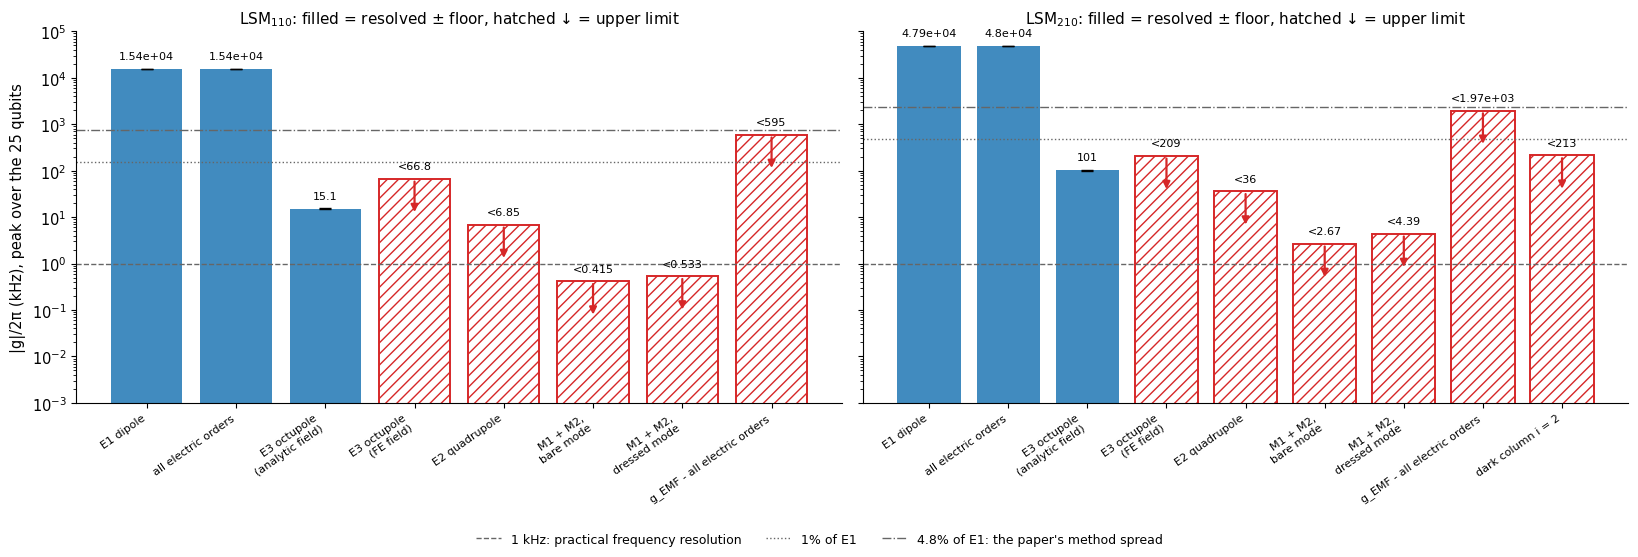

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(16.5, 5.6), sharey=True)
for a_k, tag in zip(ax, bare):
    rows_ = BUDGET_ROWS[tag]
    e1k = rows_[0]["value"]
    for k_, r_ in enumerate(rows_):
        if r_["status"] in ("resolved", "unverified"):
            a_k.bar(k_, r_["value"], color="tab:blue", alpha=0.85 if r_["resolved"] else 0.4)
            a_k.errorbar(k_, r_["value"], yerr=r_["floor"], color="k", capsize=4, lw=1.4)
            if r_["model_band"]:
                a_k.plot([k_, k_], r_["model_band"], color="0.4", lw=3, alpha=0.6)
        else:
            lim = max(r_["value"], r_["floor"]) * (2 if r_["model_band"] else 1)
            a_k.bar(k_, lim, color="none", edgecolor="tab:red", hatch="///", lw=1.4)
            a_k.annotate("", xy=(k_, lim / 6), xytext=(k_, lim), arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=1.6))
        shown = r_["value"] if r_["status"] != "upper limit" else max(r_["value"], r_["floor"]) * (2 if r_["model_band"] else 1)
        a_k.text(k_, (shown + (r_["floor"] if r_["status"] != "upper limit" else 0)) * 1.6, ("<" if r_["status"] == "upper limit" else "") + fmt_kHz(shown), ha="center", fontsize=8)
    for val, lab, ls_ in ((1.0, "1 kHz: practical frequency resolution", "--"), (0.01 * e1k, "1% of E1", ":"), (0.048 * e1k, "4.8% of E1: the paper's method spread", "-.")):
        a_k.axhline(val, color="0.4", lw=1.0, ls=ls_, label=lab)
    a_k.set_yscale("log")
    a_k.set_xticks(range(len(rows_)), [r_["term"].replace(" (", "\n(").replace(", ", ",\n") for r_ in rows_], rotation=35, ha="right", fontsize=8)
    a_k.set(title=f"LSM$_{{{tag}}}$: filled = resolved ± floor, hatched ↓ = upper limit", ylim=(1e-3, 1e5))
ax[0].set_ylabel("|g|/2π (kHz), peak over the 25 qubits")
h_, l_ = ax[0].get_legend_handles_labels()
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend(h_, l_, loc="lower center", ncol=3, fontsize=9, frameon=False)
show(fig, "fig15_hierarchy_error_bars")

**The multipole orders.** The same hierarchy as a series. Left: the error of the partial sums of the electric series against the exact coupling, for qubits with a coupling above 5% of the maximum. The gray band is the relative uncertainty of the *charges themselves* (the null calibration of the previous section): below it the mesh does not determine the answer, and the higher orders are mathematically there but physically not resolved. Right: the octupole estimated from the finite-element field (second derivatives of the fit) against the analytic octupole, qubit by qubit, with the scatter over the fit variants as error bars and the 3× floor as a band. The analytic octupole is exact; the finite-element estimate is what a simulation without the analytic field would have.

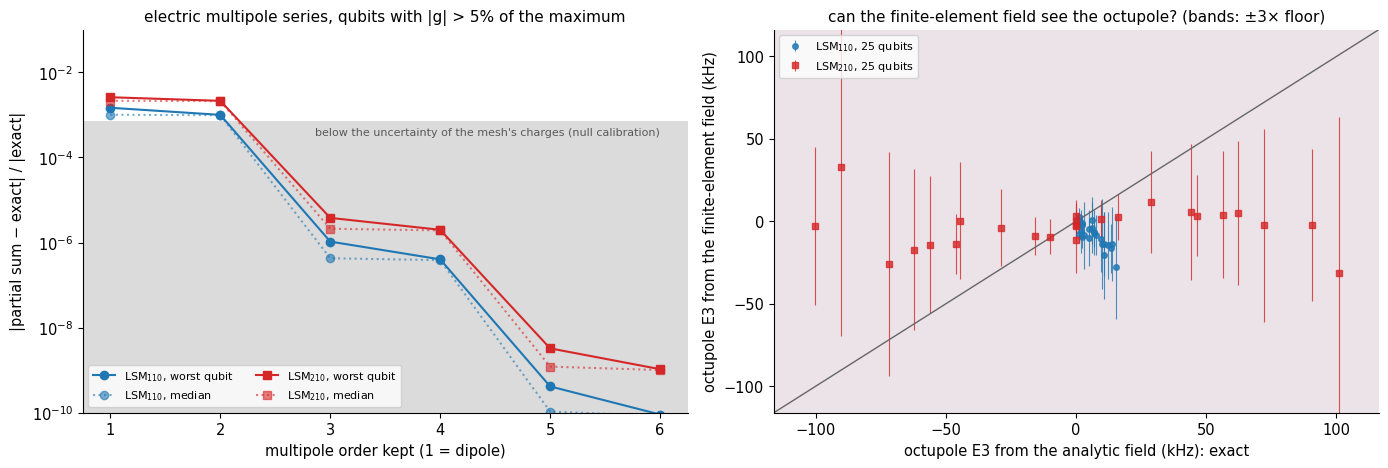

LSM110: octupole, analytic (exact) 15.1 kHz, floor 0.49;  from the finite-element field: peak 28 kHz, floor 66.8 kHz -> NOT resolved: an upper limit, marginal in the finite element
LSM210: octupole, analytic (exact) 101 kHz, floor 3.2;  from the finite-element field: peak 33.1 kHz, floor 209 kHz -> NOT resolved: an upper limit, marginal in the finite element


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
orders = np.arange(1, 7)
for tag, mk_, col in (("110", "o", "tab:blue"), ("210", "s", "tab:red")):
    a_ = an[tag]
    errs = []
    for ij in QUBITS:
        s_ = src[ij]
        T_ = mp.series_terms(a_, s_["c"], s_["r"], s_["q"], 6)
        ex_ = mp.exact_analytic(a_, s_["c"], s_["r"], s_["q"])
        errs.append((np.abs(np.cumsum(T_) - ex_) / abs(ex_), abs(ex_)))
    g_big = max(e[1] for e in errs)
    sel = [e[0] for e in errs if e[1] > 0.05 * g_big]
    ax[0].semilogy(orders, np.max(sel, axis=0), mk_ + "-", color=col, label=f"LSM$_{{{tag}}}$, worst qubit")
    ax[0].semilogy(orders, np.median(sel, axis=0), mk_ + ":", color=col, alpha=0.6, label=f"LSM$_{{{tag}}}$, median")
    terms[tag]["order_err"] = np.max(sel, axis=0)
ax[0].axhspan(1e-14, dark_rel, color="0.8", alpha=0.7, lw=0)
ax[0].text(6.0, dark_rel * 0.7, "below the uncertainty of the mesh's charges (null calibration)", ha="right", va="top", fontsize=8, color="0.35")
ax[0].set(xlabel="multipole order kept (1 = dipole)", ylabel="|partial sum − exact| / |exact|", ylim=(1e-10, 1e-1), xticks=orders,
          title="electric multipole series, qubits with |g| > 5% of the maximum")
ax[0].legend(fontsize=8, ncol=2, loc="lower left")
for tag, col, mk_ in (("110", "tab:blue", "o"), ("210", "tab:red", "s")):
    Ta = terms[tag]
    x_ = Ta["E3"].ravel() * 1e3
    y_ = Ta["E3fe"].ravel() * 1e3
    sd = np.nanstd(VAR_TERMS[tag]["E3fe"], axis=0, ddof=1).ravel() * 1e3
    ax[1].errorbar(x_, y_, yerr=sd, fmt=mk_, color=col, ms=4, alpha=0.8, elinewidth=0.8, label=f"LSM$_{{{tag}}}$, 25 qubits")
    row = [r_ for r_ in BUDGET_ROWS[tag] if r_["term"] == "E3 octupole (FE field)"][0]
    ax[1].fill_between([-1e3, 1e3], -3 * row["floor"], 3 * row["floor"], color=col, alpha=0.08, lw=0)
lim_ = 1.15 * max(np.nanmax(np.abs(terms[t_]["E3"])) for t_ in bare) * 1e3
ax[1].plot([-lim_, lim_], [-lim_, lim_], color="0.4", lw=1)
ax[1].set(xlim=(-lim_, lim_), ylim=(-lim_, lim_), xlabel="octupole E3 from the analytic field (kHz): exact", ylabel="octupole E3 from the finite-element field (kHz)",
          title="can the finite-element field see the octupole? (bands: ±3× floor)")
ax[1].legend(fontsize=8)
plt.tight_layout()
show(fig, "fig16_orders_and_octupole")
for tag in bare:
    row = [r_ for r_ in BUDGET_ROWS[tag] if r_["term"] == "E3 octupole (FE field)"][0]
    ra = [r_ for r_ in BUDGET_ROWS[tag] if r_["term"] == "E3 octupole (analytic field)"][0]
    print(f"LSM{tag}: octupole, analytic (exact) {ra['value']:.3g} kHz, floor {ra['floor']:.2g};  from the finite-element field: peak {row['value']:.3g} kHz, floor {row['floor']:.3g} kHz "
          f"-> {'resolved' if row['resolved'] else 'NOT resolved: an upper limit, marginal in the finite element'}")

**The coupling maps with their floors.** Row 1 is the dipole coupling $E_1$ of all 100 qubits (unfolded from the quarter by the mirror rules of 4.44). Row 2, the octupole ratio $E_3/E_1$ from the analytic field, the same number for every qubit. Row 3, the difference between the all-orders coupling in the finite-element field and in the analytic field with the same charges: it follows the pattern of the coupling, a smooth amplitude difference of a fraction of a percent, the discretization error of the field. Row 4, the magnetic coupling $|M_1|+|M_2|$ of the bare mode in hertz. Stippled cells are below 3× the floor of their term (row 1: relative floor of the dipole plus its null floor, per qubit; rows 3–4: the peak floor of the term): not resolved, a value that must not be read as a number.

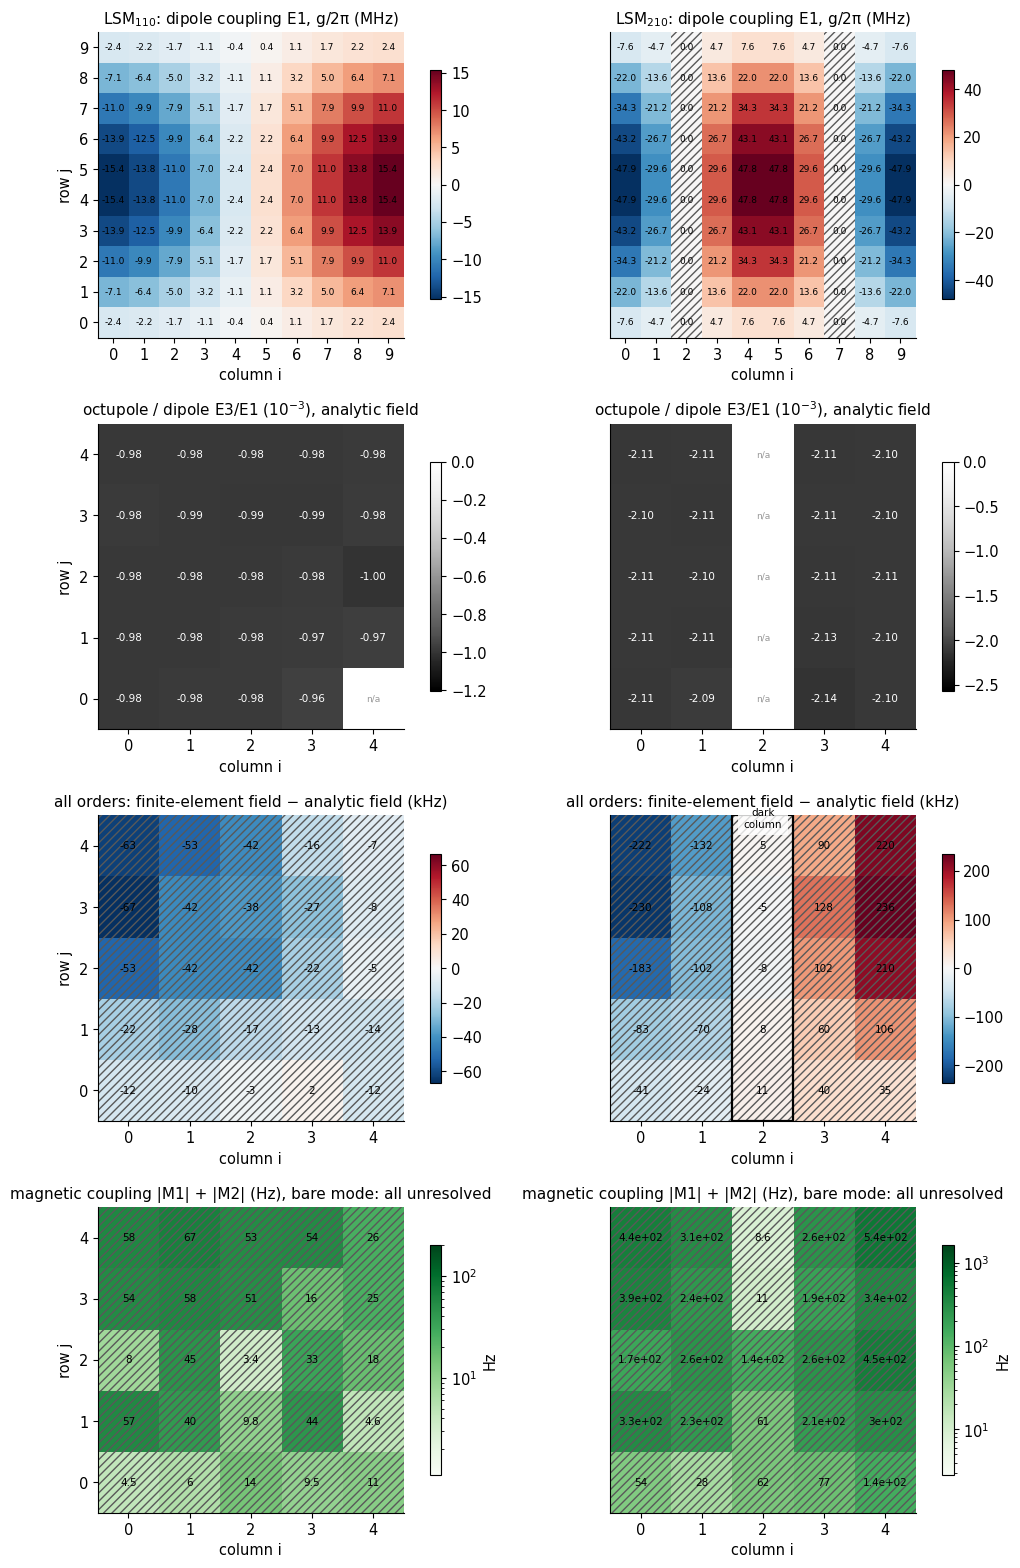

In [38]:
def unfold(vals, cuts):
    return pm.unfold_quarter({(i, j): vals[j, i] for i in range(5) for j in range(5)}, cuts, 10)


def stipple(a_k, mask):
    for jj in range(mask.shape[0]):
        for ii in range(mask.shape[1]):
            if mask[jj, ii]:
                a_k.add_patch(plt.Rectangle((ii - 0.5, jj - 0.5), 1, 1, fill=False, hatch="////", ec="0.35", lw=0))


fig, ax = plt.subplots(4, 2, figsize=(10.8, 15.8))
for col, (tag, cuts) in enumerate((("110", ("pmc", "pmc")), ("210", ("pec", "pmc")))):
    T, a_ = terms[tag], an[tag]
    rows_ = {r_["term"]: r_ for r_ in BUDGET_ROWS[tag]}
    full = unfold(T["E1"], cuts)
    lim = np.nanmax(np.abs(full))
    im = ax[0, col].imshow(full, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    for jj in range(10):
        for ii in range(10):
            ax[0, col].text(ii, jj, f"{full[jj, ii]:.1f}", ha="center", va="center", fontsize=6.5)
    r_e1 = rows_["E1 dipole"]
    f_q = np.sqrt((r_e1["floor"] / r_e1["value"] * np.abs(full)) ** 2 + (r_e1["parts"]["null"] * 1e-3) ** 2)  # relative floor + null floor
    stipple(ax[0, col], np.abs(full) < 3 * f_q)
    ax[0, col].set(title=f"LSM$_{{{tag}}}$: dipole coupling E1, g/2π (MHz)", xticks=range(10), yticks=range(10) if col == 0 else [],
                   xlabel="column i", ylabel="row j" if col == 0 else None)
    plt.colorbar(im, ax=ax[0, col], shrink=0.75)
    ratio_map = T["E3"] / T["E1a"]
    big = np.abs(T["E1a"]) > 0.05 * np.nanmax(np.abs(T["E1a"]))
    rm = np.where(big, ratio_map, np.nan)
    im = ax[1, col].imshow(rm * 1e3, origin="lower", cmap="Greys_r", vmin=np.nanmin(rm * 1e3) * 1.2, vmax=0)
    for jj in range(5):
        for ii in range(5):
            if big[jj, ii]:
                ax[1, col].text(ii, jj, f"{ratio_map[jj, ii] * 1e3:.2f}", ha="center", va="center", fontsize=7.5, color="k" if ratio_map[jj, ii] * 1e3 > np.nanmin(rm * 1e3) * 0.5 else "w")
            else:
                ax[1, col].text(ii, jj, "n/a", ha="center", va="center", fontsize=6.5, color="0.6")
    ax[1, col].set(title="octupole / dipole E3/E1 (10$^{-3}$), analytic field", xticks=range(5), yticks=range(5) if col == 0 else [],
                   xlabel="column i", ylabel="row j" if col == 0 else None)
    plt.colorbar(im, ax=ax[1, col], shrink=0.75)
    res = (T["exact_fe"] - T["exact_a"]) * 1e3
    lim = np.nanmax(np.abs(res))
    im = ax[2, col].imshow(res, origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
    for jj in range(5):
        for ii in range(5):
            ax[2, col].text(ii, jj, f"{res[jj, ii]:.0f}", ha="center", va="center", fontsize=7.5)
    stipple(ax[2, col], np.abs(res) < 3 * rows_["all electric orders"]["floor"])
    if tag == "210":
        ax[2, col].add_patch(plt.Rectangle((1.5, -0.5), 1, 5, fill=False, ec="k", lw=1.6))
        ax[2, col].text(2, 4.45, "dark\ncolumn", ha="center", fontsize=7.5, va="center", bbox=dict(fc="w", ec="none", alpha=0.8))
    ax[2, col].set(title="all orders: finite-element field − analytic field (kHz)", xticks=range(5), yticks=range(5) if col == 0 else [],
                   xlabel="column i", ylabel="row j" if col == 0 else None)
    plt.colorbar(im, ax=ax[2, col], shrink=0.75)
    mag = (np.abs(T["M1"]) + np.abs(T["M2"])) * 1e6  # Hz
    im = ax[3, col].imshow(mag, origin="lower", cmap="Greens", norm=mcolors.LogNorm(vmin=mag.min() / 3, vmax=mag.max() * 3))
    for jj in range(5):
        for ii in range(5):
            ax[3, col].text(ii, jj, f"{mag[jj, ii]:.2g}", ha="center", va="center", fontsize=7.5)
    stipple(ax[3, col], mag * 1e-3 < 3 * rows_["M1 + M2, bare mode"]["floor"])
    ax[3, col].set(title="magnetic coupling |M1| + |M2| (Hz), bare mode: all unresolved", xticks=range(5), yticks=range(5) if col == 0 else [],
                   xlabel="column i", ylabel="row j" if col == 0 else None)
    plt.colorbar(im, ax=ax[3, col], shrink=0.75, label="Hz")
plt.tight_layout()
show(fig, "fig17_coupling_maps")

## 12. What was claimed, and what the numbers say

Every statement in this notebook about what is zero, small or large is a row below, with its condition, the test that was run, and the measured result. The table is built from the values computed above, not typed.

In [39]:
rows_md = ["| # | claim | condition | test | measured | verdict | floor and significance (Sec. 10) |", "|---|---|---|---|---|---|---|"]
budget_lookup = {(tag, r_["term"]): r_ for tag in BUDGET_ROWS for r_ in BUDGET_ROWS[tag]}
for k_, c_ in enumerate(CLAIMS, 1):
    v = {"PASS": "**PASS**", "CAVEAT": "**CAVEAT**", "FAIL": "**FAIL**"}[c_["verdict"]]
    note = f" *{c_['note']}*" if c_["note"] else ""
    sig = "—"
    if c_["term"] and (c_["term"][1], c_["term"][0]) in budget_lookup:
        r_ = budget_lookup[(c_["term"][1], c_["term"][0])]
        sig = (f"resolved: {r_['value']:.3g} ± {r_['floor']:.2g} kHz" if r_["status"] == "resolved" else
               (f"unverified (no mesh levels): {r_['value']:.3g} ± {r_['floor']:.2g} kHz" if r_["status"] == "unverified" else
                f"upper limit < {max(r_['value'], r_['floor']) * (2 if r_['model_band'] else 1):.3g} kHz"))
    rows_md.append(f"| {k_} | {c_['statement']} | {c_['condition']} | {c_['test']} | {c_['measured']} | {v}{note} | {sig} |")
n_by = {k: sum(c["verdict"] == k for c in CLAIMS) for k in ("PASS", "CAVEAT", "FAIL")}
display(Markdown("\n".join(rows_md) + f"\n\n{len(CLAIMS)} claims: {n_by['PASS']} PASS, {n_by['CAVEAT']} CAVEAT (holds, with a named limitation), {n_by['FAIL']} FAIL."))

| # | claim | condition | test | measured | verdict | floor and significance (Sec. 10) |
|---|---|---|---|---|---|---|
| 1 | p_y = 0 | σ even in y (paddles symmetric about the junction axis) | 25 qubits, order-2 charges | max |p_y|/p_x = 3.4e-03 | **PASS** *the mesh is not symmetric: the value changes from run to run with the mesh (ensemble of Sec. 10) and falls under refinement (Sec. 9)* | — |
| 2 | S_ij = 0 (Cartesian electric quadrupole) | two identical paddles, mirror images under x → −x, each even in y | 25 qubits, order-2 charges | max |S_ij|/(p·1 mm) = 1.7e-03 | **PASS** | — |
| 3 | only odd angular harmonics of the potential | σ odd in x, even in y | potential on a 2 mm circle, qubit (2,2) | max even / n=1 amplitude = 2.3e-03 | **PASS** | — |
| 4 | m_z = 0 (magnetic dipole of the current) | y-mirror symmetry of the paddles and of the junction position | Poisson sheet-current model, 25 qubits | max |m_z|/(p·1 mm) = 8.6e-04 | **PASS** | — |
| 5 | only M_yz survives (magnetic quadrupole of the current) | same | Poisson sheet-current model, 25 qubits | |M_xz|/|M_yz| ≤ 1.3e-02; M_yz = 1.16e-17 C m³ | **CAVEAT** *the size of M_yz depends on the current model (factor ~2); its vanishing partners do not* | — |
| 6 | the magnetic energy of the qubit mode outside the junction is a few percent of its energy | single qubit in a box, junction as an inductor L_J, 1 J mode | ∫|curl E|²/(2μ0ω²) over the box plus ½L_J I² | 8.8% of the magnetic, 4.4% of the total energy | **PASS** *the paper's fit gives δL'_n = 0.32 nH of 3.6 nH (8.9%); 4.45 reproduces it* | — |
| 7 | the sheet-current model reproduces the qubit's own B_z pattern | single qubit in a box, 0.1 mm above the chip | Biot–Savart of the model current vs the full-wave curl E/ω | correlation 0.957; full wave / model amplitude = 0.87 | **PASS** *one geometry; the model's factor-2 flag stays for the magnetic quadrupole* | — |
| 8 | the divergence-free part of the current does not couple to a mode with B_z = 0 | flat source; in-plane E a gradient | ∫K̃·E dA of the model with and without an added loop current, analytic LSM110 | change 7.8e-07 of the coupling | **PASS** *this is why the factor-2 uncertainty of the current model does not touch the electric coupling* | — |
| 9 | B_z = 0 for the bare package mode | LSM_ab0 (TM in z): H_z = 0 | FE curl E/ω on the quarter chip plane; loop circulation | LSM110: rms B_z/max B_t = 8.1e-04, loop ≤ 1.1e-03; LSM210: rms B_z/max B_t = 1.3e-03, loop ≤ 9.9e-04 | **PASS** *B_z is not identically zero in the discrete solution; it is a discretization floor (Sec. 9)* | — |
| 10 | the FE mode reproduces the analytic in-plane E, ∇E and in-plane B at the qubits | bare mode, h_metal as set by BUDGET | disc fit vs analytic, 25 qubits | LSM110: E 0.4%, ∇E 4.0%, B_t 0.7%; LSM210: E 0.3%, ∇E 5.1%, B_t 1.1% | **PASS** | — |
| 11 | E_t and B are continuous across the silicon surface; D_x and E_z jump by ε_r | μ_r = 1, no surface charge or current at the surface | FE field 1 µm either side of z = t | E_x ratio 1.000, B_x ratio 0.985, E_z ratio 11.56 (ε_r = 11.9), D_z ratio 0.971 | **PASS** | — |
| 12 | the octupole E3 renormalizes the amplitude of LSM110 and not its pattern | separable potential; surviving octupole components O_xxx, O_xyy | E3/E1 qubit by qubit, analytic field | E3/E1 = -9.83e-04 ± 8e-06; closed form -9.84e-04 | **PASS** | resolved: 15.1 ± 0.49 kHz |
| 13 | the electric dipole is correct to a fraction of a percent for LSM110 | this qubit, this mode, qubits with |g| > 5% of the maximum | (exact ray integral − E1)/E1, analytic field | ≤ 1.5e-03 | **PASS** | — |
| 14 | the octupole E3 renormalizes the amplitude of LSM210 and not its pattern | separable potential; surviving octupole components O_xxx, O_xyy | E3/E1 qubit by qubit, analytic field | E3/E1 = -2.11e-03 ± 1e-05; closed form -2.11e-03 | **PASS** | resolved: 101 ± 3.2 kHz |
| 15 | the electric dipole is correct to a fraction of a percent for LSM210 | this qubit, this mode, qubits with |g| > 5% of the maximum | (exact ray integral − E1)/E1, analytic field | ≤ 2.6e-03 | **PASS** | — |
| 16 | the qubits of column i = 2 are dark to LSM210 | they sit on a node of E_x (cos(2πx/L) = 0) | FE ray coupling of the 5 qubits of the column | max |g| = 35 kHz = 7.3e-04 of the largest coupling (charges alone: 8.4e-04) | **PASS** *a residue near 10^-3 is the mesh noise of p_y E_y and of E_x; Sec. 9 follows it under refinement* | upper limit < 213 kHz |
| 17 | the magnetic coupling is zero for the bare package mode | flat symmetric qubit; bare LSM mode; Poisson sheet current | M1 + M2 with the FE curl E, 25 qubits | max |M1 + M2|/max |E1|: LSM110 4.3e-06, LSM210 1.1e-05 | **PASS** *a floor, not a measurement of a nonzero value; M2 uses the factor-2 model of M̃_yz* | upper limit < 0.415 kHz |
| 18 | the magnetic coupling stays small with the 200 paddles present | dressed mode, annulus fit around each qubit | M1 + M2 with the dressed-mode B_z, 25 qubits | max |M1 + M2|/max |E1|: LSM110 1.7e-05, LSM210 4.6e-05 | **PASS** *B_z of the dressed mode is a few times its bare noise floor; the annulus fit extrapolates inward over the qubit's own paddles* | upper limit < 0.533 kHz |
| 19 | an unequal-paddle qubit has a nonzero quadrupole S_yy | x → −x mirror broken, y mirror kept | single qubit in a box, order-2 charges, about the dipole center | S_yy/(p·1 mm) = -0.097 (symmetric: -1.8e-04); couples 2.4e-03 of the dipole at (1,2) in LSM110 | **PASS** | — |
| 20 | an off-axis junction gives the current a magnetic dipole m_z, and leaves the charge alone | y → −y mirror of the current broken | Poisson sheet current, single qubit | m_z/(p·1 mm) = -0.30 about the dipole center (symmetric: +1.2e-04); S_yy unchanged (-3.7e-05) | **CAVEAT** *m_z comes from the factor-2 current model; its origin dependence is exact (shift rule checked above)* | — |
| 21 | a vertical current element couples magnetically to the in-plane B of the mode | arch of height h, span 0.2 mm, charge Q of the qubit (a model of the current path) | U_M = Q·(2/3)s h·ωB_y against p·E_x | 1% of the dipole at h = 23 µm; ratio 0.27 at h = 600 µm | **CAVEAT** *idealized thin arch carrying the whole displacement charge; the order of magnitude, not a bond-wire simulation* | — |
| 22 | a package mode with B_z ≠ 0 exists, and a qubit with m_z ≠ 0 couples to it magnetically | LSE (TE_z) mode near 40 GHz; qubit with its junction 0.3 mm off the paddle axis | paddle-free quarter, 0.3 mm elements, disc fits; M1 = m̃_z (curl E)_z | lowest clear mode 38.9 GHz; largest |M1|/|E1| = 0.01; M1 14.4 MHz vs fit floor 5.1 MHz (2.8×) | **CAVEAT** *M1 does NOT clear 3× its fit floor on this mesh (a one-mesh illustration, mesh floor unmeasured); coarse mesh (frequencies to a few %), the factor-2 current model, and a qubit placed in a mode 6× its own frequency: the mechanism, not a prediction* | — |

22 claims: 18 PASS, 4 CAVEAT (holds, with a named limitation), 0 FAIL.

In [40]:
summ_rows = ["| quantity | this notebook | reference |", "|---|---|---|"]
summ_rows.append(f"| dipole moment $p_x$ (second-order electrostatics) | {px.mean():.3e} C m | 3.41×10⁻¹⁰ C m (paper, `pm.PAPER`); 3.79×10⁻¹⁰ C m (notebook 4.43) |")
summ_rows.append(f"| $\\lvert A\\rvert/2\\pi$, LSM$_{{110}}$ (electric, all orders) | {abs(A_ex['110']):.2f} MHz | 15.6 MHz (paper, full wave) |")
summ_rows.append(f"| $\\lvert A_{{210}}\\rvert/2\\pi$, LSM$_{{210}}$ (electric, all orders) | {abs(A_ex['210']):.1f} MHz | 49.8 MHz (paper, full wave) |")
summ_rows.append(f"| octupole / dipole, LSM$_{{110}}$, LSM$_{{210}}$ | {np.median((terms['110']['E3'] / terms['110']['E1a'])[np.abs(terms['110']['E1a']) > 0.05 * np.nanmax(np.abs(terms['110']['E1a']))]):.1e}, {np.median((terms['210']['E3'] / terms['210']['E1a'])[np.abs(terms['210']['E1a']) > 0.05 * np.nanmax(np.abs(terms['210']['E1a']))]):.1e} | — |")
summ_rows.append(f"| quadrupole $S_{{ij}}$, magnetic dipole $\\tilde m_z$ (symmetric qubit) | ≤ {(S_all / (px * 1e-3)).max():.0e}, ≤ {np.abs(mz).max() / (px.mean() * 1e-3):.0e} of $p\\cdot1$ mm | zero by symmetry |")
summ_rows.append(f"| magnetic coupling $\\lvert M_1+M_2\\rvert$ / $\\lvert E_1\\rvert$ (bare, dressed), LSM$_{{110}}$ | {rel_bare['110']:.0e}, {rel_dress['110']:.0e} | — |")
summ_rows.append(f"| magnetic energy outside the junction (qubit mode) | {(f'{U_geo / (U_L + U_geo):.1%} of the magnetic energy' if RUN_SINGLE_QUBIT_BOX else 'not run')} | ≈ 4% of the qubit's energy (paper, 4.45) |")
display(Markdown("\n".join(summ_rows)))
if TIMES:
    print("time per stage (s): " + ", ".join(f"{k} {v:.0f}" for k, v in TIMES.items()))

| quantity | this notebook | reference |
|---|---|---|
| dipole moment $p_x$ (second-order electrostatics) | 3.787e-10 C m | 3.41×10⁻¹⁰ C m (paper, `pm.PAPER`); 3.79×10⁻¹⁰ C m (notebook 4.43) |
| $\lvert A\rvert/2\pi$, LSM$_{110}$ (electric, all orders) | 15.76 MHz | 15.6 MHz (paper, full wave) |
| $\lvert A_{210}\rvert/2\pi$, LSM$_{210}$ (electric, all orders) | 51.0 MHz | 49.8 MHz (paper, full wave) |
| octupole / dipole, LSM$_{110}$, LSM$_{210}$ | -9.8e-04, -2.1e-03 | — |
| quadrupole $S_{ij}$, magnetic dipole $\tilde m_z$ (symmetric qubit) | ≤ 2e-03, ≤ 9e-04 of $p\cdot1$ mm | zero by symmetry |
| magnetic coupling $\lvert M_1+M_2\rvert$ / $\lvert E_1\rvert$ (bare, dressed), LSM$_{110}$ | 4e-06, 2e-05 | — |
| magnetic energy outside the junction (qubit mode) | 8.8% of the magnetic energy | ≈ 4% of the qubit's energy (paper, 4.45) |

time per stage (s): mesh 3, electrostatics 89, box 106, bare 110 56, bare 210 56, dressed 110 47, dressed 210 49, symmetry breaking 5, lse 26, convergence sweep 278, mesher ensemble 141, estimator variants 14


## What this tells you

- **The dipole picture is right, and now it has an error bar.** The electric dipole coupling and the sum of all electric multipoles agree to a few parts in a thousand; the first correction that exists, the octupole, multiplies the dipole coupling of a mode by a factor of about $1-10^{-3}$ (LSM$_{110}$) or $1-2\times10^{-3}$ (LSM$_{210}$), the same factor at every qubit, and so changes the amplitude $A$ and not the pattern.
- **The zeros are properties of a geometry, and each has a condition.** The electric quadrupole and the magnetic dipole of a two-pad transmon vanish because the charge is odd in $x$ and even in $y$ and the current has the matching mirror symmetry. Break the symmetry and they appear (Sec. 7). The magnetic coupling of a flat qubit to the lowest package modes vanishes because a flat source couples only to $B_z$ and these modes have none (Secs. 3, 4, 6); give the source vertical extent, or use a mode with $B_z\neq0$, and it does not vanish (Sec. 8).
- **A zero is shown by a floor, and a floor is shown by refinement.** The symmetry zeros fall under mesh refinement or sit at the noise floor; the nonzero terms converge to limits (Sec. 9). The induced-EMF coupling, which holds every multipole and the loading by the paddles, differs from the electric series by an amount that refinement shrinks (Secs. 6, 9), which bounds all neglected terms from above.
- **A number below its floor is not a number.** With the floors of Sec. 10 (mesh, mesher ensemble, fit estimator, null calibration) every term is either resolved, with an error bar, or an upper limit. The dipole, the all-orders electric coupling and the analytic octupole are resolved; the quadrupole, the magnetic terms of the bare and of the dressed mode and the dark-column coupling are upper limits at their floors; the octupole read off the finite-element field is not resolved by it, though the analytic one is exact. Which of these matter physically is a separate question, answered by the 1 kHz and 4.8% columns of the table.
- **What is not settled here.** The size of the magnetic quadrupole of the current rests on a model good to about a factor of 2; the symmetry arguments do not. The rows of the table marked CAVEAT carry their own limitation.

## Where to go next

- **Break the symmetry of the real device.** Replace the paddles with the ones of a particular layout (`pm.build_design` takes the geometry; `mp.qubit_sources` takes any `Package`) and read $S_{yy}$ and $\tilde m_z$ off the table of Sec. 7.
- **A chip in a pocket smaller than the box.** The statement "LSM modes have $B_z=0$" needs the package to be translation-invariant in the plane, as a box with a full-size slab is. A chip smaller than the box, or a lid with a pocket, mixes LSM and LSE: the modes are no longer TM in $z$ and their normal field is no longer zero. The dressed-mode test of Sec. 6 (the same `mp.dressed_data`) measures it for that geometry without any new theory.
- **Put a vertical element in the full-wave model.** Add a post or an airbridge to the mesh and compare its induced voltage with the arch estimate of Sec. 8a.
- **Other expansion points.** `mp.multipole_terms` and `mp.series_terms` take any analytic field of the form $\sin k_xx\,\sin k_yy$, and `mp.disc_fit` any finite-element field: the same machinery gives the gradient coupling to a strongly inhomogeneous field.

## References

1. R. Molavi, E. Forati, Y. Zhang, A. R. Klots, J. Atalaya, B. W. Langley, D. A. Timucin, M. Nazari, G. Khan, Z. K. Minev, A. N. Korotkov, M. H. Devoret, "Extracting electromagnetic bare mode couplings in large superconducting quantum processors," [arXiv:2609.22442](https://arxiv.org/abs/2609.22442) (2026).
2. J. D. Jackson, *Classical Electrodynamics*, 3rd ed. (Wiley, 1999) — multipole expansions and the traceless quadrupole.
3. E. A. Power, S. Zienau, "Coulomb gauge in non-relativistic quantum electro-dynamics and the shape of spectral lines," *Phil. Trans. R. Soc. A* **251**, 427 (1959); R. G. Woolley, "Molecular quantum electrodynamics," *Proc. R. Soc. A* **321**, 557 (1971).
4. C. Cohen-Tannoudji, J. Dupont-Roc, G. Grynberg, *Photons and Atoms: Introduction to Quantum Electrodynamics* (Wiley, 1989) — the multipolar form of the atom–field coupling.
5. Z. K. Minev, Z. Leghtas, S. O. Mundhada, L. Christakis, I. M. Pop, M. H. Devoret, "Energy-participation quantization of Josephson circuits," *npj Quantum Inf.* **7**, 131 (2021). [doi:10.1038/s41534-021-00461-8](https://doi.org/10.1038/s41534-021-00461-8) — exact to all orders in the field, no multipole expansion.
6. C. A. Balanis, *Advanced Engineering Electromagnetics*, 2nd ed. (Wiley, 2012) — LSM and LSE modes of a partially filled waveguide.
7. C. Geuzaine, J.-F. Remacle, "Gmsh: A 3-D finite element mesh generator with built-in pre- and post-processing facilities," *Int. J. Numer. Methods Eng.* **79**, 1309–1331 (2009). [doi:10.1002/nme.2579](https://doi.org/10.1002/nme.2579)
8. T. Gustafsson, G. D. McBain, "scikit-fem: A Python package for finite element assembly," *J. Open Source Softw.* **5**, 2369 (2020). [doi:10.21105/joss.02369](https://doi.org/10.21105/joss.02369)

9. H. Paik *et al.*, "Observation of high coherence in Josephson junction qubits measured in a three-dimensional circuit QED architecture," *Phys. Rev. Lett.* **107**, 240501 (2011).
10. S. E. Nigg *et al.*, "Black-box superconducting circuit quantization," *Phys. Rev. Lett.* **108**, 240502 (2012).
11. A. F. Kockum, P. Delsing, G. Johansson, "Designing frequency-dependent relaxation rates and Lamb shifts for a giant artificial atom," *Phys. Rev. A* **90**, 013837 (2014); B. Kannan *et al.*, "Waveguide quantum electrodynamics with superconducting artificial giant atoms," *Nature* **583**, 775 (2020).

<!-- TODO-ZKM: not verified and therefore not cited: Stokes & Nazir, Rev. Mod. Phys. 2022, on gauge ambiguities in light-matter models; Di Stefano et al., Nat. Phys. 2019, on resolution of gauge ambiguities in ultrastrong coupling; any earlier multipole analysis of transmon-package coupling or of the magnetic coupling of planar qubits. -->